In [109]:
# NumPy monkey-patch for legacy compatibility with older third-party packages
import numpy as np

np.int = int
np.float = float
np.bool = bool

# Standard library imports
import glob
import json
import logging
import os
import re
import warnings
from collections import defaultdict, Counter
from itertools import combinations

# Data handling and visualization
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

# Medical imaging and PyRadiomics
import SimpleITK as sitk
from radiomics import featureextractor, logger

# Statistical modeling
import statsmodels.api as sm
from scipy.stats import mannwhitneyu
from scipy.stats import chi2_contingency, pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests

# Harmonization and specialized feature selection tools
from boruta import BorutaPy
from neurocombat_sklearn import CombatModel
from neuroHarmonize import harmonizationApply, harmonizationLearn
from pyearth import Earth

# Scikit-learn: core base classes
from sklearn.base import BaseEstimator, ClassifierMixin, clone

# Scikit-learn: classifiers
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier

# Scikit-learn: feature selection
from sklearn.feature_selection import SelectFromModel, SelectKBest, f_classif, RFE

# Scikit-learn: evaluation metrics, including confusion matrix and roc curve plotting support
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    auc,
)

# Scikit-learn: model selection and cross-validation
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict

# Scikit-learn: preprocessing
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    StandardScaler,
    label_binarize,
    QuantileTransformer,
)

# Scikit-learn: class weight
from sklearn.utils.class_weight import compute_class_weight

from sklearn.decomposition import PCA

from joblib import Parallel, delayed, parallel_backend

from sklearn.exceptions import ConvergenceWarning as SklearnConvergenceWarning
from statsmodels.tools.sm_exceptions import ConvergenceWarning as SmConvergenceWarning

from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

In [108]:
# Blanket suppression of every python level warning
warnings.filterwarnings("ignore")
warnings.simplefilter("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

# Silence the two noisiest loggers individually as well
logging.getLogger("statsmodels").setLevel(logging.ERROR)
logging.getLogger("pyearth").setLevel(logging.ERROR)

# Explicit filters for convergence and user warnings, redundant with the blanket rule above but kept
# in case the blanket rule is ever narrowed later
warnings.filterwarnings("ignore", category=SklearnConvergenceWarning)
warnings.filterwarnings("ignore", category=SmConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Added later in the project, filterwarnings checks the most recently added rule first, so these two
# take priority over the earlier ones above for this specific warning type and module
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn.linear_model._logistic")
warnings.filterwarnings("once", category=SklearnConvergenceWarning)
warnings.filterwarnings("once", category=SmConvergenceWarning)

In [3]:
# Display helper, wraps any dataframe in an explicitly scrollable box instead of letting a wide
# table wrap or rely on the notebook theme's default table styling
from IPython.display import HTML, display as ipy_display

def display_scrollable(df, max_width_px=1400):
    html = df.to_html()
    scrollable_html = f'<div style="overflow-x:auto; white-space:nowrap; max-width:{max_width_px}px;">{html}</div>'
    ipy_display(HTML(scrollable_html))

In [ ]:
# Display options, remove truncation so full feature names and wide tables print completely
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)

# Patient CT scans
radiomics_dir = "./NSCLC_Subtype/radiomics"
radiogenomics_dir = "./NSCLC_Subtype/radiogenomics"

# Clinical data
radiomics_clinical_path = "./NSCLC_Subtype/NSCLC-Radiomics-Clinical.csv"
radiogenomics_clinical_path = "./NSCLC_Subtype/NSCLC-Radiogenomics-Clinical.csv"

# Where extracted radiomics features get cached, and the numeric to name mapping used everywhere below
feature_output_path = "extracted_radiomics_features.csv"
label_map = {0: "NOS", 1: "Adenocarcinoma", 2: "Squamous", 3: "Large-Cell"}

In [5]:
# Convert free text histology strings into the four numeric subtype labels
def map_histology(text):
    if not isinstance(text, str):
        return np.nan
    t = text.lower()
    if "adeno" in t:
        return 1
    if "squamous" in t:
        return 2
    if "large cell" in t:
        return 3
    if "nos" in t or "not otherwise" in t:
        return 0
    return np.nan

In [6]:
def load_and_prep_clinical():
    # Load and clean radiomics clinical data
    clin1 = pd.read_csv(radiomics_clinical_path)
    clin1.columns = clin1.columns.str.strip()
    clin1["label"] = clin1["Histology"].apply(map_histology)
    clin1 = clin1.dropna(subset=["label"])
    clin1["label"] = clin1["label"].astype(int)
    clin1 = clin1[["PatientID", "label"]].rename(columns={"PatientID": "patient_id"})
    clin1["source"] = "Radiomics"
    clin1["dir"] = radiomics_dir

    # Load and clean radiogenomics clinical data
    clin2 = pd.read_csv(radiogenomics_clinical_path)
    clin2.columns = clin2.columns.str.strip()
    clin2["label"] = clin2["Histology"].apply(map_histology)
    clin2 = clin2.dropna(subset=["label"])
    clin2["label"] = clin2["label"].astype(int)
    clin2 = clin2[["Case ID", "label"]].rename(columns={"Case ID": "patient_id"})
    clin2["source"] = "Radiogenomics"
    clin2["dir"] = radiogenomics_dir

    # Combine both cohorts into one clinical table
    return pd.concat([clin1, clin2], ignore_index=True)


clinical_df = load_and_prep_clinical()

valid_patients = []
skipped_patients = []

# Process each patient and verify files
for idx, row in clinical_df.iterrows():
    p_id = str(row["patient_id"]).strip()
    source = row["source"]
    base_dir = row["dir"]

    patient_folder = os.path.join(base_dir, p_id)

    # Skip and log any patient whose folder doesn't exist on disk
    if not os.path.exists(patient_folder) or not os.path.isdir(patient_folder):
        skipped_patients.append({"Patient ID": p_id, "Source": source, "Reason": "Missing patient directory"})
        continue

    all_files = glob.glob(os.path.join(patient_folder, "*"))

    # Locate the image file by keyword, excluding anything that looks like a segmentation or mask
    image_files = [f for f in all_files if any(kw in os.path.basename(f).lower() for kw in ["image", "ct", "t1", "t2"])
                   and not any(kw in os.path.basename(f).lower() for kw in ["seg", "mask", "label"])]

    # Fall back to any non-segmentation file if no explicit image keyword matched
    if not image_files:
        image_files = [f for f in all_files if not any(kw in os.path.basename(f).lower() for kw in ["seg", "mask", "label"])]

    # Locate the segmentation mask file by keyword
    seg_files = [f for f in all_files if any(kw in os.path.basename(f).lower() for kw in ["seg", "mask", "label"])]

    # Skip and log if no image file was found even after the fallback
    if not image_files:
        skipped_patients.append({"Patient ID": p_id, "Source": source, "Reason": "Missing image file"})
        continue

    # Skip and log if no segmentation mask was found
    if not seg_files:
        skipped_patients.append({"Patient ID": p_id, "Source": source, "Reason": "Missing segmentation mask"})
        continue

    # Record the first matching image and segmentation path for this patient
    valid_patients.append({
        "Patient ID": p_id, "Label": row["label"], "Source": source,
        "Image Path": image_files[0], "Seg Path": seg_files[0]
    })

df_valid = pd.DataFrame(valid_patients)
df_skipped = pd.DataFrame(skipped_patients)

# Print a summary of how many patients made it through versus were skipped
print("Processing summary")
print(f"Total valid patients: {len(df_valid)}")
print(f"Total skipped patients: {len(df_skipped)}")

# Break down the valid patients by source and label
if not df_valid.empty:
    print("Label distribution by source:")
    label_counts = (
        df_valid.groupby(["Source", "Label"])
        .size()
        .unstack(fill_value=0)
        .rename(columns=label_map)
    )
    display(label_counts)

# Show exactly which patients were skipped and why
if not df_skipped.empty:
    print("Omitted patient details:")
    display(df_skipped)

Processing summary
Total valid patients: 513
Total skipped patients: 78
Label distribution by source:


Label,NOS,Adenocarcinoma,Squamous,Large-Cell
Source,,,,
Radiogenomics,3,112,29,0
Radiomics,59,51,147,112


Omitted patient details:


,Patient ID,Source,Reason
0,LUNG1-050,Radiomics,Missing patient directory
1,LUNG1-067,Radiomics,Missing patient directory
2,LUNG1-115,Radiomics,Missing patient directory
3,LUNG1-119,Radiomics,Missing patient directory
4,LUNG1-121,Radiomics,Missing patient directory
5,LUNG1-128,Radiomics,Missing patient directory
6,LUNG1-149,Radiomics,Missing patient directory
7,LUNG1-158,Radiomics,Missing patient directory
8,LUNG1-210,Radiomics,Missing patient directory
9,LUNG1-219,Radiomics,Missing patient directory


In [7]:
# Suppress PyRadiomics GLCM symmetry and info warnings
logger.setLevel(logging.ERROR)

# Configure extractor settings
settings = {
    "resampledPixelSpacing": [1, 1, 1],
    "interpolator": "sitkBSpline",
    "binWidth": 25,
    "label": 1,
}

# Enable the original image plus wavelet and multi scale LoG decompositions
extractor = featureextractor.RadiomicsFeatureExtractor(**settings)
extractor.enableAllFeatures()
extractor.enableImageTypeByName("Original")
extractor.enableImageTypeByName("Wavelet")
extractor.enableImageTypeByName("LoG", customArgs={"sigma": [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]})

feature_rows = []
failed = []
total_patients = len(df_valid)

# Extract features from valid patients
for i, row in df_valid.iterrows():
    try:
        result = extractor.execute(row["Image Path"], row["Seg Path"])
        # Drop pyradiomics diagnostic metadata columns, keep only the actual feature values
        feat = {k: v for k, v in result.items() if not k.startswith("diagnostics_")}
        feat["patient_id"] = row["Patient ID"]
        feat["label"] = row["Label"]
        feat["source"] = row["Source"]
        feature_rows.append(feat)
    except Exception as e:
        failed.append({"Patient ID": row["Patient ID"], "Source": row["Source"], "Error": str(e)})

    # Print progress every ten patients and on the last one
    if (i + 1) % 10 == 0 or (i + 1) == total_patients:
        print(f"{i + 1}/{total_patients} processed")

# Save extracted features
features_df = pd.DataFrame(feature_rows)
features_df.to_csv(feature_output_path, index=False)

# Display failure summary if any extractions failed
print(f"Total failed extractions: {len(failed)}")
if failed:
    failed_df = pd.DataFrame(failed)
    print("Failed extraction details:")
    display(failed_df)

10/513 processed
20/513 processed
30/513 processed
40/513 processed
50/513 processed
60/513 processed
70/513 processed
80/513 processed
90/513 processed
100/513 processed
110/513 processed
120/513 processed
130/513 processed
140/513 processed
150/513 processed
160/513 processed
170/513 processed
180/513 processed
190/513 processed
200/513 processed
210/513 processed
220/513 processed
230/513 processed
240/513 processed
250/513 processed
260/513 processed
270/513 processed
280/513 processed
290/513 processed
300/513 processed
310/513 processed
320/513 processed
330/513 processed
340/513 processed
350/513 processed
360/513 processed
370/513 processed
380/513 processed
390/513 processed
400/513 processed
410/513 processed
420/513 processed
430/513 processed
440/513 processed
450/513 processed
460/513 processed
470/513 processed
480/513 processed
490/513 processed
500/513 processed
510/513 processed
513/513 processed
Total failed extractions: 58
Failed extraction details:


,Patient ID,Source,Error
0,LUNG1-007,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
1,LUNG1-015,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
2,LUNG1-024,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
3,LUNG1-049,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
4,LUNG1-078,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
5,LUNG1-081,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
6,LUNG1-086,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
7,LUNG1-089,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
8,LUNG1-098,Radiomics,No labels found in this mask (i.e. nothing is segmented)!
9,LUNG1-102,Radiomics,No labels found in this mask (i.e. nothing is segmented)!


In [8]:
# Load extracted features
features_df = pd.read_csv(feature_output_path)
meta_cols = ["patient_id", "label", "source"]
feat_cols = [c for c in features_df.columns if c not in meta_cols]

# Force feature values to numeric and drop columns that completely failed
features_df[feat_cols] = features_df[feat_cols].apply(pd.to_numeric, errors="coerce")
features_df = features_df.dropna(axis=1, how="all")
feat_cols = [c for c in feat_cols if c in features_df.columns]

# Impute remaining missing values using column medians
features_df[feat_cols] = features_df[feat_cols].fillna(features_df[feat_cols].median())

# Identify and drop constant zero-variance features
nunique = features_df[feat_cols].nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
features_df = features_df.drop(columns=constant_cols)
feat_cols = [c for c in feat_cols if c not in constant_cols]

# Separate feature matrix X and target labels Y
X = features_df[feat_cols].copy()
Y = features_df["label"].copy()

# Enforce explicit ordering: NOS, Adenocarcinoma, Squamous, Large-Cell
ordered_labels = ["NOS", "Adenocarcinoma", "Squamous", "Large-Cell"]
counts = Y.map(label_map).value_counts().reindex(ordered_labels, fill_value=0)

print("Label distribution after cleaning:")
display(counts.to_frame(""))

Label distribution after cleaning:


,
label,
NOS,53
Adenocarcinoma,146
Squamous,160
Large-Cell,96


In [ ]:
# External validation settings, one path per collection with a confirmed label source, rider and
# pd1 are intentionally left out of TARGET_COLLECTIONS since no public histology label could be
# found for either
NSCLC_SUBTYPE_DIR = "./NSCLC_Subtype"

TARGET_COLLECTIONS = {
    "luad": {"dir": os.path.join(NSCLC_SUBTYPE_DIR, "luad"), "label_source": "all_adenocarcinoma"},
    "lusc": {"dir": os.path.join(NSCLC_SUBTYPE_DIR, "lusc"), "label_source": "all_squamous"},
    "dx": {"dir": os.path.join(NSCLC_SUBTYPE_DIR, "dx"), "label_source": "patient_id_code"},
}

# Letter code embedded in each dx patient id, per TCIA's own documentation for LUNG-PET-CT-Dx
DX_CODE_TO_LABEL = {"A": 1, "G": 2, "E": 3}
external_feature_output_path = os.path.join(NSCLC_SUBTYPE_DIR, "extracted_radiomics_features_external.csv")

In [10]:
# Builds one manifest row per external patient with an image, a segmentation, and a resolvable label
valid_external = []
skipped_external = []

for collection_name, info in TARGET_COLLECTIONS.items():
    collection_dir = info["dir"]
    if not os.path.isdir(collection_dir):
        print(f"Warning, {collection_dir} does not exist, skipping {collection_name}")
        continue

    for patient_id in sorted(os.listdir(collection_dir)):
        patient_dir = os.path.join(collection_dir, patient_id)
        if not os.path.isdir(patient_dir):
            continue

        image_path = os.path.join(patient_dir, "image.nii.gz")
        seg_path = os.path.join(patient_dir, "segmentation.nii.gz")
        if not os.path.exists(image_path) or not os.path.exists(seg_path):
            skipped_external.append({"Patient ID": patient_id, "Source": collection_name, "Reason": "Missing image or segmentation file"})
            continue

        # Resolve the label according to this collection's label source
        if info["label_source"] == "all_adenocarcinoma":
            label = 1
        elif info["label_source"] == "all_squamous":
            label = 2
        elif info["label_source"] == "patient_id_code":
            match = re.search(r"Dx-([A-Z])\d+", patient_id)
            code = match.group(1) if match else None
            label = DX_CODE_TO_LABEL.get(code)
            if label is None:
                reason = f"Small Cell, not part of the trained classes" if code == "B" else f"Unrecognized code '{code}' in patient id"
                skipped_external.append({"Patient ID": patient_id, "Source": collection_name, "Reason": reason})
                continue
        else:
            skipped_external.append({"Patient ID": patient_id, "Source": collection_name, "Reason": "No label source configured"})
            continue

        valid_external.append({
            "Patient ID": patient_id, "Label": label, "Source": collection_name,
            "Image Path": image_path, "Seg Path": seg_path
        })

df_valid_external = pd.DataFrame(valid_external)
df_skipped_external = pd.DataFrame(skipped_external)

print("External validation manifest summary")
print(f"Total valid patients: {len(df_valid_external)}")
print(f"Total skipped patients: {len(df_skipped_external)}")

if not df_valid_external.empty:
    print("\nLabel distribution by source:")
    display(df_valid_external.groupby(["Source", "Label"]).size().unstack(fill_value=0).rename(columns=label_map))

if not df_skipped_external.empty:
    print("\nOmitted patient details:")
    display(df_skipped_external)

External validation manifest summary
Total valid patients: 102
Total skipped patients: 24

Label distribution by source:


Label,Adenocarcinoma,Squamous,Large-Cell
Source,,,
dx,63,19,3
luad,9,0,0
lusc,0,8,0



Omitted patient details:


,Patient ID,Source,Reason
0,TCGA-50-8459,luad,Missing image or segmentation file
1,TCGA-34-7107,lusc,Missing image or segmentation file
2,TCGA-51-4080,lusc,Missing image or segmentation file
3,Lung_Dx-A0011,dx,Missing image or segmentation file
4,Lung_Dx-A0022,dx,Missing image or segmentation file
5,Lung_Dx-A0024,dx,Missing image or segmentation file
6,Lung_Dx-A0041,dx,Missing image or segmentation file
7,Lung_Dx-A0046,dx,Missing image or segmentation file
8,Lung_Dx-A0157,dx,Missing image or segmentation file
9,Lung_Dx-B0001,dx,"Small Cell, not part of the trained classes"


In [11]:
# Extracts features using the exact same extractor settings as the training pipeline, feature values
# are only comparable across datasets if the extraction parameters are identical
external_feature_rows = []
external_failed = []
total_external = len(df_valid_external)

for i, row in df_valid_external.iterrows():
    try:
        result = extractor.execute(row["Image Path"], row["Seg Path"])
        feat = {k: v for k, v in result.items() if not k.startswith("diagnostics_")}
        feat["patient_id"] = row["Patient ID"]
        feat["label"] = row["Label"]
        feat["source"] = row["Source"]
        external_feature_rows.append(feat)
    except Exception as e:
        external_failed.append({"Patient ID": row["Patient ID"], "Source": row["Source"], "Error": str(e)})

    if (i + 1) % 10 == 0 or (i + 1) == total_external:
        print(f"{i + 1}/{total_external} processed")

external_features_df = pd.DataFrame(external_feature_rows)
external_features_df.to_csv(external_feature_output_path, index=False)

print(f"Total failed extractions: {len(external_failed)}")
if external_failed:
    display(pd.DataFrame(external_failed))

10/102 processed
20/102 processed
30/102 processed
40/102 processed
50/102 processed
60/102 processed
70/102 processed
80/102 processed
90/102 processed
100/102 processed
102/102 processed
Total failed extractions: 1


,Patient ID,Source,Error
0,Lung_Dx-A0038,dx,"Bounding box of ROI is larger than image space:\n\tROI bounds (x, y, z image coordinate space) ((336.5, 351.5000003487722, 10.333333333333334), (403.49999999999994, 218.50000034877218, 5.0))\n\tImage Size (512, 512, 9)"


In [12]:
# Loads extracted external features and aligns them to the exact training feature columns, zero
# variance and column dropping decisions belong to the training distribution, not recomputed here
external_features_df = pd.read_csv(external_feature_output_path)

external_features_df[X.columns] = external_features_df[X.columns].apply(pd.to_numeric, errors="coerce")
external_features_df[X.columns] = external_features_df[X.columns].fillna(external_features_df[X.columns].median())

X_external = external_features_df[X.columns].copy()
X_external.index = external_features_df["patient_id"]
Y_external = external_features_df["label"].copy()
Y_external.index = external_features_df["patient_id"]
source_external = external_features_df["source"].copy()
source_external.index = external_features_df["patient_id"]

print("External feature matrix shape:", X_external.shape)
print("External label distribution:")
print(Y_external.map(label_map).value_counts())

External feature matrix shape: (101, 1781)
External label distribution:
label
Adenocarcinoma    71
Squamous          27
Large-Cell         3
Name: count, dtype: int64


Sample counts per site and class, before harmonization


Label,Adenocarcinoma,Large-Cell,NOS,Squamous
Site,,,,
Lung-PET-CT-Dx,62,3,0,19
NSCLC-Radiogenomics,105,0,3,28
NSCLC-Radiomics,41,96,50,132
TCGA-LUAD,9,0,0,0
TCGA-LUSC,0,0,0,8


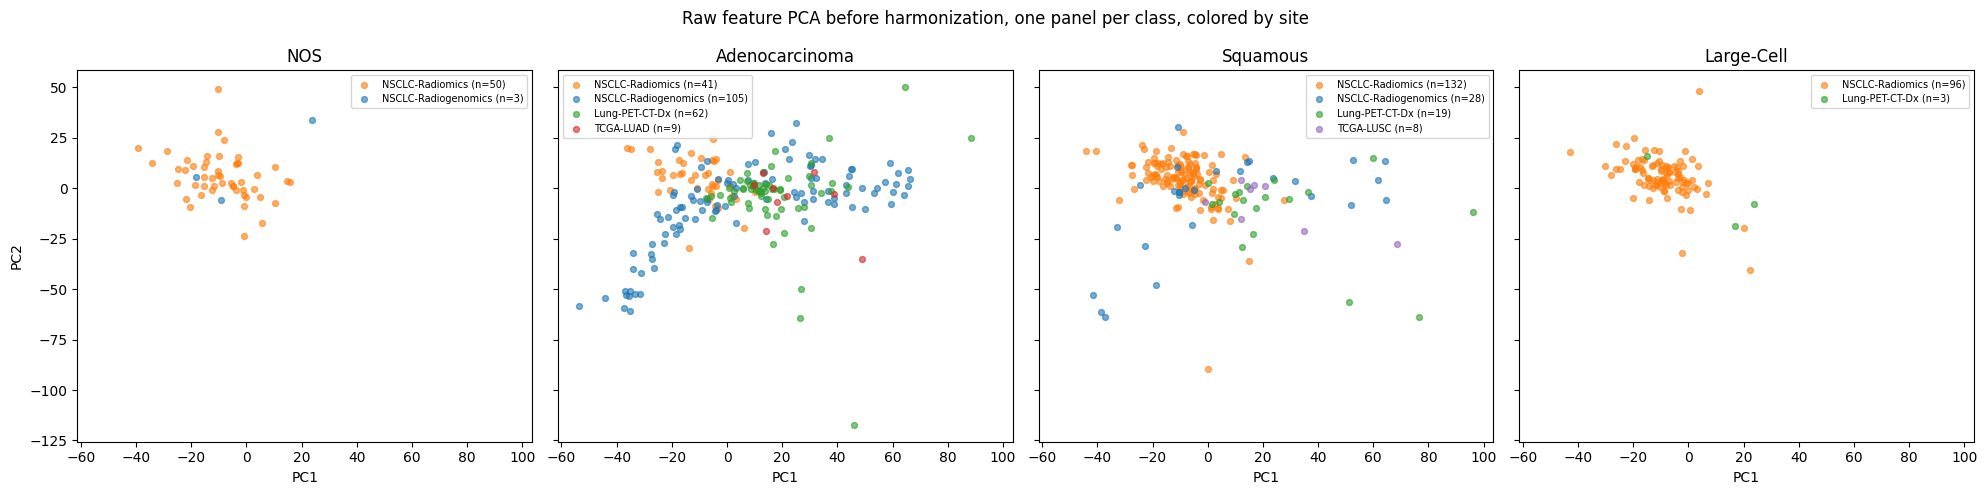

Variance explained by PC1 and PC2: 0.282, 0.161


In [143]:
# Diagnostic only. Visualizes raw, pre-harmonization feature distributions across every site, split
# out per class, using one cheap PCA projection, the per-feature statistical test on close to two
# thousand columns follows in the next cell. A real site effect should separate sites even within a
# single class, a real class effect should not
raw_combined = pd.concat([X, X_external], axis=0)
combined_site = pd.concat(
    [features_df["source"].reset_index(drop=True), source_external.reset_index(drop=True)],
    ignore_index=True,
)
combined_label = pd.concat([Y.reset_index(drop=True), Y_external.reset_index(drop=True)], ignore_index=True)

# Full collection names for every printed table and legend
site_display_names = {
    "Radiomics": "NSCLC-Radiomics",
    "Radiogenomics": "NSCLC-Radiogenomics",
    "dx": "Lung-PET-CT-Dx",
    "luad": "TCGA-LUAD",
    "lusc": "TCGA-LUSC",
}

print("Sample counts per site and class, before harmonization")
site_class_counts = pd.DataFrame({
    "Site": combined_site.map(site_display_names).values,
    "Label": combined_label.map(label_map).values,
})
display(site_class_counts.groupby(["Site", "Label"]).size().unstack(fill_value=0))

# Standardize before PCA so no single high variance feature dominates the projection
pca_scaler = StandardScaler()
raw_scaled_for_pca = pca_scaler.fit_transform(raw_combined)

pca_diagnostic = PCA(n_components=2, random_state=42)
pca_coords = pca_diagnostic.fit_transform(raw_scaled_for_pca)

pca_df = pd.DataFrame(pca_coords, columns=["PC1", "PC2"])
pca_df["Site"] = combined_site.values
pca_df["Label"] = combined_label.map(label_map).values

# Fixed site-to-color mapping so a site has the same color in every panel
site_colors = {
    "Radiomics": "tab:orange",
    "Radiogenomics": "tab:blue",
    "dx": "tab:green",
    "luad": "tab:red",
    "lusc": "tab:purple",
}
assert set(pca_df["Site"].unique()) <= set(site_colors), "Add any new site to site_colors"
assert set(site_colors) <= set(site_display_names), "Add any new site to site_display_names"

present_classes = [name for name in label_map.values() if name in pca_df["Label"].unique()]
fig, axes = plt.subplots(
    1, len(present_classes), figsize=(5 * len(present_classes), 5),
    sharex=True, sharey=True, squeeze=False,
)
axes = axes[0]
for ax, class_name in zip(axes, present_classes):
    subset = pca_df[pca_df["Label"] == class_name]
    for site_name, color in site_colors.items():
        group = subset[subset["Site"] == site_name]
        if len(group) == 0:
            continue
        ax.scatter(
            group["PC1"], group["PC2"], color=color,
            label=f"{site_display_names[site_name]} (n={len(group)})",
            alpha=0.6, s=18,
        )
    ax.set_title(class_name)
    ax.set_xlabel("PC1")
    ax.legend(fontsize=7, loc="best", framealpha=0.8)
axes[0].set_ylabel("PC2")
plt.suptitle("Raw feature PCA before harmonization, one panel per class, colored by site")
plt.tight_layout()
# plt.savefig("figure3_pca_by_site.png", dpi=300, bbox_inches="tight")  # uncomment for the paper figure
plt.show()

print(f"Variance explained by PC1 and PC2: {pca_diagnostic.explained_variance_ratio_[0]:.3f}, {pca_diagnostic.explained_variance_ratio_[1]:.3f}")

In [110]:
def site_effect_by_class(data, site, label, label_map, min_n=15, fallback_min_n=3, alpha=0.05):
    """For each subtype, test every feature for differences across sites, using only cases of that subtype."""
    site, label = np.asarray(site), np.asarray(label)
    rows = []
    for cls in sorted(np.unique(label)):
        name = label_map[cls]
        in_class = label == cls
        counts = pd.Series(site[in_class]).value_counts()

        sites = sorted(counts[counts >= min_n].index)
        low_power = False
        if len(sites) < 2:                       # Large-Cell / NOS: use whatever sites exist
            sites = sorted(counts[counts >= fallback_min_n].index)
            low_power = True
        if len(sites) < 2:
            print(f"{name}: skipped, fewer than two sites with enough cases ({counts.to_dict()})")
            continue

        keep = in_class & np.isin(site, sites)
        Xk, sk = data.values[keep], site[keep]
        masks = [sk == s for s in sites]

        H_vals, p_vals = [], []
        for j in range(Xk.shape[1]):
            try:
                H, p = kruskal(*[Xk[g, j] for g in masks])
            except ValueError:                   # all values identical, nothing to test
                H, p = 0.0, 1.0
            H_vals.append(H); p_vals.append(p)

        q_vals = multipletests(p_vals, method="fdr_bh")[1]
        eps2 = np.array(H_vals) / (keep.sum() - 1)   # Kruskal-Wallis epsilon-squared effect size

        rows.append({
            "Subtype": name,
            "Sites tested (n)": ", ".join(f"{s} ({m.sum()})" for s, m in zip(sites, masks)),
            "Features significant (FDR<0.05)": f"{(q_vals < alpha).mean():.0%}",
            "Median epsilon-squared": round(float(np.median(eps2)), 3),
            "Features with eps2 >= 0.08": f"{(eps2 >= 0.08).mean():.0%}",
            "Low power": "yes" if low_power else "no",
        })
    return pd.DataFrame(rows).set_index("Subtype")

display(site_effect_by_class(raw_combined, combined_site, combined_label, label_map))
# display(site_effect_by_class(X_harmonized_combined, combined_site, combined_label, label_map))

,Sites tested (n),Features significant (FDR<0.05),Median epsilon-squared,Features with eps2 >= 0.08,Low power
Subtype,,,,,
NOS,"Radiogenomics (3), Radiomics (50)",0%,0.013,16%,yes
Adenocarcinoma,"Radiogenomics (105), Radiomics (41), dx (62)",88%,0.129,69%,no
Squamous,"Radiogenomics (28), Radiomics (132), dx (19)",86%,0.146,69%,no
Large-Cell,"Radiomics (96), dx (3)",18%,0.013,12%,yes


In [14]:
# Prepare one covariates dataframe spanning every site, training and external together, site now has
# five levels instead of two, and NOS only appears in the training block since external labels never
# include NOS. Reuses raw_combined from the site distribution diagnostic above instead of concatenating
# X and X_external a second time
combined_site_values = np.concatenate([features_df["source"].values, source_external.values])
combined_label_values = np.concatenate([Y.values, Y_external.values])

covars = pd.DataFrame(
    {"SITE": combined_site_values, "label": pd.Series(combined_label_values).astype("category").values},
    index=raw_combined.index,
)

# Run harmonization once across all five sites, label is passed alongside SITE so ComBat does not
# remove real class signal while correcting for scanner and site differences
model, X_harmonized_array = harmonizationLearn(raw_combined.values, covars)

# Convert harmonized array back into a pandas DataFrame with original column and index names
X_harmonized_combined = pd.DataFrame(X_harmonized_array, columns=raw_combined.columns, index=raw_combined.index)

# Standardize once across the combined harmonized data
scaler = StandardScaler()
X_scaled_combined = pd.DataFrame(
    scaler.fit_transform(X_harmonized_combined), columns=X_harmonized_combined.columns, index=X_harmonized_combined.index
)

# Split back into the training block every fold below uses and the external block held out for
# validation at the end, done by position since X and X_external were concatenated in that order
n_train = len(X)
X_harmonized_raw = X_harmonized_combined.iloc[:n_train]
X_scaled = X_scaled_combined.iloc[:n_train]
X_external_scaled = X_scaled_combined.iloc[n_train:]

In [112]:
# Same diagnostic as before, now on the harmonized features, then a before/after comparison
before_df = site_effect_by_class(raw_combined, combined_site, combined_label, label_map)
after_df = site_effect_by_class(X_harmonized_combined, combined_site, combined_label, label_map)

cols = ["Features significant (FDR<0.05)", "Median epsilon-squared", "Features with eps2 >= 0.08"]
comparison = before_df[cols].join(after_df[cols], lsuffix=" (before)", rsuffix=" (after)")

print("After harmonization")
display(after_df)
print("Before vs after")
display_scrollable(comparison)

After harmonization


,Sites tested (n),Features significant (FDR<0.05),Median epsilon-squared,Features with eps2 >= 0.08,Low power
Subtype,,,,,
NOS,"Radiogenomics (3), Radiomics (50)",15%,0.021,24%,yes
Adenocarcinoma,"Radiogenomics (105), Radiomics (41), dx (62)",35%,0.017,25%,no
Squamous,"Radiogenomics (28), Radiomics (132), dx (19)",29%,0.021,19%,no
Large-Cell,"Radiomics (96), dx (3)",0%,0.006,3%,yes


Before vs after


,Features significant (FDR<0.05) (before),Median epsilon-squared (before),Features with eps2 >= 0.08 (before),Features significant (FDR<0.05) (after),Median epsilon-squared (after),Features with eps2 >= 0.08 (after)
Subtype,,,,,,
NOS,0%,0.013,16%,15%,0.021,24%
Adenocarcinoma,88%,0.129,69%,35%,0.017,25%
Squamous,86%,0.146,69%,29%,0.021,19%
Large-Cell,18%,0.013,12%,0%,0.006,3%


In [15]:
# Ranks features by their univariate relationship to the target
def univariate_prefilter(X_train, Y_train, top_k=9999):
    # Cap k at the number of available columns so this never errors on a small feature set
    k = min(top_k, X_train.shape[1])
    selector = SelectKBest(score_func=f_classif, k=k)
    selector.fit(X_train, Y_train)
    return list(X_train.columns[selector.get_support()])


# Drops one feature from any pair whose correlation exceeds the threshold
def remove_high_correlation(X_train, feature_list, threshold=0.85):
    if len(feature_list) <= 1:
        return list(feature_list)
    X_sub = X_train[feature_list]
    corr_matrix = X_sub.corr().abs()
    # Upper triangle only, so each correlated pair is only evaluated once
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    return [f for f in feature_list if f not in to_drop]


# Ranks pair candidates nonlinearly with Extra Trees and ensures feature diversity, now returns each
# kept feature's Extra Trees importance alongside the list instead of discarding it once ranking is
# done, since selection runs once outside the fold there is no fold count left to report and this
# importance score takes its place
def tree_based_pairwise_selection(X_bin, y_bin, candidate_features, max_features=10):
    # If the candidate pool is already small enough, skip ranking entirely, every candidate gets equal
    # standing since none were actually compared against each other
    if len(candidate_features) <= max_features:
        return list(candidate_features), {f: np.nan for f in candidate_features}

    # Leaf constraint kept at 3, the et_min_samples_leaf diagnostic showed leaf=1 only marginally better (0.973 vs 0.966), prevents noise memorization
    et = ExtraTreesClassifier(n_estimators=100, class_weight="balanced", min_samples_leaf=3, random_state=42)
    et.fit(X_bin[candidate_features], y_bin)

    # Rank every candidate by importance, most important first
    importances = et.feature_importances_
    importance_map = dict(zip(candidate_features, importances))
    selected_indices = np.argsort(importances)[::-1]
    ranked_features = [candidate_features[i] for i in selected_indices]

    # Remove highly correlated features to prevent SVM overfitting on redundant data
    diverse_features = remove_high_correlation(X_bin, ranked_features, threshold=0.85)
    final_features = diverse_features[:max_features]
    return final_features, {f: importance_map[f] for f in final_features}


# Builds a stable candidate pool using tight lasso selection to eliminate noise, now returns each
# selected feature's absolute lasso coefficient magnitude alongside the list, averaged across classes
# for the multiclass one versus rest case, this is the actual signal SelectFromModel used to decide
# which features to keep, kept here instead of being discarded
def select_features_lasso(X_train, Y_train, pool_k=20, prefilter_k=300):
    # Wide univariate prefilter first, L1 handles high dimensional inputs well on its own
    candidates = univariate_prefilter(X_train, Y_train, top_k=prefilter_k)
    X_filtered = X_train[candidates]

    # Tight regularization isolates only the most discriminative features
    lasso_fold = LogisticRegression(penalty="l1", solver="liblinear", C=0.2, random_state=42)
    selector = SelectFromModel(lasso_fold, max_features=pool_k)
    selector.fit(X_filtered, Y_train)

    ranked = list(X_filtered.columns[selector.get_support()])

    # Coefficient magnitude from the fitted lasso model itself, averaged across the one versus rest
    # classes when there are more than two
    fitted_coefs = np.abs(selector.estimator_.coef_)
    if fitted_coefs.ndim > 1:
        fitted_coefs = fitted_coefs.mean(axis=0)
    coef_map = dict(zip(X_filtered.columns, fitted_coefs))
    importance_map = {f: coef_map[f] for f in ranked}

    # Backfill from the prefiltered candidates if lasso selected fewer than pool_k features, backfilled
    # features get no importance score since lasso itself never ranked them
    if len(ranked) < pool_k:
        extra = [f for f in candidates if f not in ranked]
        backfill = extra[:pool_k - len(ranked)]
        ranked.extend(backfill)
        importance_map.update({f: np.nan for f in backfill})

    final_features = remove_high_correlation(X_train, ranked)
    return final_features, {f: importance_map[f] for f in final_features}


# Forward stepwise p-value selection wrapper optimized with fast bfgs solver, now returns each
# selected feature's max p-value at the moment it was added, inverted so a smaller p-value reads as a
# larger importance, matching the direction of the other two methods' scores
def select_features_wrapper(X_train, Y_train, pool_k=20, alpha=0.15, prefilter_k=75):
    # Prefilter kept tight since every candidate gets refit at every round
    candidate_features = univariate_prefilter(X_train, Y_train, top_k=prefilter_k)
    selected_features = []
    selection_pvals = {}
    remaining = list(candidate_features)
    is_multinomial = Y_train.nunique() > 2

    # Greedily add whichever remaining feature gives the best max p-value each round
    while remaining and len(selected_features) < pool_k:
        best_pval = 1.0
        best_feature = None
        for feat in remaining:
            trial_feats = selected_features + [feat]
            X_const = sm.add_constant(X_train[trial_feats], has_constant="add")
            try:
                # Local suppression, scoped to this fit only, stays here rather than moving to the
                # global warnings cell since it only applies within this per-feature trial loop
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    if is_multinomial:
                        model = sm.MNLogit(Y_train, X_const).fit(disp=False, method='bfgs', maxiter=50)
                    else:
                        model = sm.Logit(Y_train, X_const).fit(disp=False, method='bfgs', maxiter=50)

                # Skip any trial fit that failed to converge
                if hasattr(model, "mle_retvals") and not model.mle_retvals.get("converged", True):
                    continue

                # Skip unstable fits with non-finite or blown up coefficients
                params = model.params.values if is_multinomial else model.params.values
                if not np.all(np.isfinite(params)) or np.any(np.abs(params) > 25):
                    continue

                max_p = model.pvalues.max().max() if is_multinomial else model.pvalues.max()
                if not np.isfinite(max_p):
                    continue
                if max_p < best_pval:
                    best_pval = max_p
                    best_feature = feat
            except Exception:
                continue

        # Stop once no remaining feature clears the significance threshold
        if best_feature is not None and best_pval < alpha:
            selected_features.append(best_feature)
            selection_pvals[best_feature] = best_pval
            remaining.remove(best_feature)
        else:
            break

    # Backfill from the prefiltered candidates if fewer than pool_k features were selected
    final_features = selected_features if len(selected_features) > 0 else list(candidate_features[:pool_k])
    if len(final_features) < pool_k:
        extra = [f for f in candidate_features if f not in final_features]
        backfill = extra[:pool_k - len(final_features)]
        final_features.extend(backfill)
        for f in backfill:
            selection_pvals[f] = np.nan

    kept = remove_high_correlation(X_train, final_features)
    importance_map = {f: (1.0 - selection_pvals[f]) if pd.notna(selection_pvals.get(f)) else np.nan for f in kept}
    return kept, importance_map


# Builds a candidate pool using multivariate adaptive regression splines fit per class, now returns
# each selected feature's basis function count alongside the list, how many surviving, non pruned
# basis functions reference that feature, and truncates to pool_k by that count instead of by whatever
# order a plain set happened to iterate in
def select_features_mars(X_train, Y_train, pool_k=20, prefilter_k=100):
    # Local legacy compatibility patch, mirrors the one at the very top of the notebook
    import numpy as _np
    if not hasattr(_np, "int"): _np.int = int
    if not hasattr(_np, "float"): _np.float = float
    if not hasattr(_np, "bool"): _np.bool = bool

    from pyearth import Earth
    # Prefilter kept tight, Earth is unstable once feature count approaches sample count
    candidates = univariate_prefilter(X_train, Y_train, top_k=prefilter_k)
    X_filtered = X_train[candidates]
    classes = np.sort(Y_train.unique())
    feature_counter = Counter()

    try:
        # Local suppression, scoped to this fit only, same reasoning as in select_features_wrapper
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if len(classes) > 2:
                # One binary Earth model per class, one versus rest
                for c in classes:
                    y_binary = (Y_train == c).astype(int)
                    model = Earth(max_degree=1, penalty=3.0)
                    model.fit(X_filtered, y_binary)
                    for bf in model.basis_:
                        if not bf.is_pruned():
                            for var in bf.variables_:
                                feature_counter[candidates[var]] += 1
            else:
                # Only two classes present, a single Earth model is enough
                model = Earth(max_degree=1, penalty=3.0)
                model.fit(X_filtered, Y_train)
                for bf in model.basis_:
                    if not bf.is_pruned():
                        for var in bf.variables_:
                            feature_counter[candidates[var]] += 1

        # Most referenced features first, instead of the arbitrary order a plain set would have given
        selected = [f for f, _ in feature_counter.most_common()]
        selected = selected[:pool_k] if selected else candidates[:pool_k]
    except Exception:
        # Fall back to the raw prefiltered candidates if Earth fails to fit entirely
        selected = candidates[:pool_k]

    # Backfill from the prefiltered candidates if fewer than pool_k features survived pruning
    if len(selected) < pool_k:
        extra = [f for f in candidates if f not in selected]
        selected.extend(extra[:pool_k - len(selected)])

    kept = remove_high_correlation(X_train, selected)
    importance_map = {f: feature_counter.get(f, np.nan) for f in kept}
    return kept, importance_map

In [16]:
# Builds stage one features with the chosen selection method and stage two features per class pair
# with Extra Trees ranking, now also returns each stage's importance scores so downstream plots have
# something to show now that selection runs once outside the fold instead of varying fold to fold
def extract_all_pipeline_features(X_train, y_train, method="lasso", stage1_k=20, stage2_k=10):
    # Pick the selection function for this run
    if method == "lasso":
        select_fn = select_features_lasso
    elif method == "wrapper":
        select_fn = select_features_wrapper
    elif method == "mars":
        select_fn = select_features_mars
    else:
        raise ValueError(f"Unknown method: {method}")

    # Stage one uses the full candidate pool built from all classes at once
    stage1_features, stage1_importances = select_fn(X_train, y_train, pool_k=stage1_k)

    # Stage two selects independently per class pair
    classes = sorted(y_train.unique())
    all_pairs = list(combinations(classes, 2))

    pair_features = {}
    pair_importances = {}
    for pair in all_pairs:
        mask = y_train.isin(pair)
        X_bin, y_bin = X_train[mask], y_train[mask]
        if y_bin.nunique() == 2:
            feats, importances = tree_based_pairwise_selection(X_bin, y_bin, list(X_train.columns), max_features=stage2_k)
            pair_features[pair] = feats
            pair_importances[pair] = importances

    return stage1_features, pair_features, stage1_importances, pair_importances

In [113]:
# Calculate evaluation metrics per class and return formatted summary dataframe
# Accuracy is one versus rest, (TP + TN) / total for each class treated as positive against all others,
# the Average row is the mean of the per class values
def build_custom_metrics_table(y_true, y_pred, y_prob, classes, label_map):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    # Guards against a class or column ordering mismatch, catches it immediately with a clear error
    # instead of silently reading the wrong column
    if y_prob.shape[1] != len(classes):
        raise ValueError(
            f"y_prob has {y_prob.shape[1]} columns but classes has {len(classes)} entries, "
            f"these must match exactly and in the same order"
        )

    metrics = []
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    y_true_bin = label_binarize(y_true, classes=classes)

    for idx, c in enumerate(classes):
        tp = cm[idx, idx]
        fn = cm[idx, :].sum() - tp
        fp = cm[:, idx].sum() - tp
        tn = cm.sum() - (tp + fn + fp)

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        accuracy = (tp + tn) / cm.sum() if cm.sum() > 0 else 0.0   # one versus rest accuracy

        try:
            roc_auc = roc_auc_score(y_true_bin[:, idx], y_prob[:, idx])
        except ValueError:
            roc_auc = np.nan

        metrics.append({
            "Subtype": label_map.get(c, str(c)), "Precision": precision, "Sensitivity": recall,
            "F1-Score": f1, "Specificity": specificity, "Accuracy": accuracy, "ROC-AUC": roc_auc
        })

    df = pd.DataFrame(metrics).set_index("Subtype")

    # Macro averaged row across all classes, Accuracy is now the mean of the one versus rest values
    macro_auc = roc_auc_score(y_true_bin, y_prob, multi_class="ovr", average="macro")
    avg_row = pd.Series({
        "Precision": df["Precision"].mean(), "Sensitivity": df["Sensitivity"].mean(),
        "F1-Score": df["F1-Score"].mean(), "Specificity": df["Specificity"].mean(),
        "Accuracy": df["Accuracy"].mean(), "ROC-AUC": macro_auc
    }, name="Average")

    return pd.concat([df, pd.DataFrame(avg_row).T])

In [18]:
class SymmetricHierarchicalClassifier(BaseEstimator, ClassifierMixin):
    """
    Hierarchical classifier utilizing Stage 1 multiclass routing and Stage 2 pairwise refinement.
    """
    def __init__(self, base_estimator, stage1_features, pair_features, C=10.0):
        self.base_estimator = base_estimator
        self.stage1_features = stage1_features
        self.pair_features = pair_features
        self.C = C
        self.clf_stage1 = clone(self.base_estimator)
        self.pair_clfs = {}

    def fit(self, X, Y):
        # Stage one, one multinomial classifier across every class
        self.classes_ = np.sort(np.unique(Y))
        self.clf_stage1.fit(X[self.stage1_features], Y)

        # Stage two, one binary rbf SVM per class pair, trained only on that pair's samples
        for pair, feats in self.pair_features.items():
            mask = Y.isin(pair)
            if len(feats) > 0:
                pair_clf = SVC(kernel="rbf", C=self.C, gamma="scale", probability=True,
                                class_weight="balanced", random_state=42)
                pair_clf.fit(X.loc[mask, feats], Y[mask])
                self.pair_clfs[pair] = pair_clf
        return self

    def predict_proba(self, X):
        # Start from stage one's own probabilities for every class
        probs_stage1 = self.clf_stage1.predict_proba(X[self.stage1_features])
        final_probs = probs_stage1.copy()

        for idx in range(len(X)):
            # Find stage one's top two candidate classes for this sample
            top2_idx = np.argsort(probs_stage1[idx])[::-1][:2]
            top2_classes = self.clf_stage1.classes_[top2_idx]
            pair = tuple(sorted(top2_classes))

            if pair in self.pair_clfs:
                # Replace the top two classes' probabilities with stage two's pairwise result, and
                # zero out every other class since the pairwise classifier only distinguishes this pair
                clf_pair = self.pair_clfs[pair]
                sample_feat = X[self.pair_features[pair]].iloc[[idx]]
                s2_probs = clf_pair.predict_proba(sample_feat)[0]

                for i, c_val in enumerate(self.clf_stage1.classes_):
                    if c_val in pair:
                        s2_i = list(clf_pair.classes_).index(c_val)
                        final_probs[idx, i] = s2_probs[s2_i]
                    else:
                        final_probs[idx, i] = 0.0

            # Renormalize so the row sums back to one
            total_p = np.sum(final_probs[idx, :])
            if total_p > 0:
                final_probs[idx, :] = final_probs[idx, :] / total_p

        return final_probs

    def predict(self, X):
        # Map argmax's positional index back through classes_ to the actual class label, this only
        # happened to work before because every prior run used contiguous zero indexed labels where
        # position and label were numerically identical, mapping through classes_ makes it correct
        # generally, including for the three class Adenocarcinoma, Squamous, Large-Cell label set
        probs = self.predict_proba(X)
        return self.classes_[np.argmax(probs, axis=1)]

In [19]:
def _run_one_fold(X_df, y_ser, train_idx, test_idx, stage1_feats, pair_feats, base_estimator):
    # Feature selection already happened once outside every fold, this only fits and scores the
    # classifier on that fold's split using the fixed feature set every other fold also uses
    X_train, X_test = X_df.iloc[train_idx], X_df.iloc[test_idx]
    y_train, y_test = y_ser.iloc[train_idx], y_ser.iloc[test_idx]

    clf = SymmetricHierarchicalClassifier(base_estimator=base_estimator, stage1_features=stage1_feats, pair_features=pair_feats)
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test).tolist()
    y_prob = clf.predict_proba(X_test).tolist()
    y_true = y_test.tolist()
    return y_true, y_pred, y_prob


def evaluate_hierarchical_pipeline_fast(
    X_df, y_ser, 
    pipeline_name="Hierarchical Model",
    method="lasso",
    label_map=None,
    n_repeats=10,
    n_jobs=None,
    n_splits=5,
    track_feature_frequency=False,
    stage1_k=20,                     # Default stage one feature pool size
    stage1_C=10.0,                   # Default stage one regularization strength
    stage1_class_weight="dampened"   # Default stage one class weighting
):
    
    if label_map is None:
        label_map = {0: "NOS", 1: "Adenocarcinoma", 2: "Squamous", 3: "Large-Cell"}
    if n_jobs is None:
        n_jobs = max(1, (os.cpu_count() or 4) - 1)

    print(f"Running cross-validation for {pipeline_name}, {n_repeats} repeats, {n_jobs} jobs")

    # Standard dampened weight calculation (square root of balanced weights, normalized)
    if stage1_class_weight == "dampened":
        unique_classes = np.unique(y_ser)
        bal_weights = compute_class_weight('balanced', classes=unique_classes, y=y_ser)
        dampened_weights = bal_weights ** 0.5
        dampened_weights = dampened_weights / np.mean(dampened_weights)
        class_weight_arg = dict(zip(unique_classes, dampened_weights))
    else:
        class_weight_arg = stage1_class_weight

    # LogisticRegression receives a valid dictionary, matching the diagnostics
    base_estimator = LogisticRegression(
        max_iter=5000, 
        C=stage1_C, 
        class_weight=class_weight_arg, 
        random_state=42
    )

    # Feature selection now happens once on the entire dataset before cross-validation starts, the
    # importance scores that come back are each method's own real signal, lasso coefficient magnitude,
    # wrapper significance, or mars basis function count, not a fold count
    stage1_feats, pair_feats, stage1_importances, pair_importances = extract_all_pipeline_features(
        X_df, y_ser, method=method, stage1_k=stage1_k
    )

    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)
    classes = sorted(y_ser.unique())

    # Run every fold in parallel across available cpu cores
    with parallel_backend("loky", inner_max_num_threads=1):
        fold_results = Parallel(n_jobs=n_jobs)(
            delayed(_run_one_fold)(X_df, y_ser, train_idx, test_idx, stage1_feats, pair_feats, base_estimator)
            for train_idx, test_idx in rskf.split(X_df, y_ser)
        )

    # Pool every fold's held out predictions
    all_y_true, all_y_pred, all_y_prob = [], [], []
    for y_true, y_pred, y_prob in fold_results:
        all_y_true.extend(y_true)
        all_y_pred.extend(y_pred)
        all_y_prob.extend(y_prob)

    all_y_true = np.array(all_y_true)
    all_y_pred = np.array(all_y_pred)
    all_y_prob = np.array(all_y_prob)

    metrics_table = build_custom_metrics_table(all_y_true, all_y_pred, all_y_prob, classes, label_map)

    # Default behavior, unchanged from before, every existing diagnostic call keeps working as is
    if not track_feature_frequency:
        return metrics_table, all_y_true, all_y_pred, all_y_prob

    # Built from each method's own importance score now instead of a fold selection count, sorted so
    # the most important feature is first, matching what plot_feature_frequency expects
    stage1_freq_df = pd.DataFrame(stage1_importances.items(), columns=["Feature", "Importance"])
    stage1_freq_df = stage1_freq_df.sort_values("Importance", ascending=False, na_position="last").reset_index(drop=True)

    pair_freq_dfs = {}
    for pair, importances in pair_importances.items():
        freq_df = pd.DataFrame(importances.items(), columns=["Feature", "Importance"])
        pair_freq_dfs[pair] = freq_df.sort_values("Importance", ascending=False, na_position="last").reset_index(drop=True)

    return metrics_table, all_y_true, all_y_pred, all_y_prob, stage1_freq_df, pair_freq_dfs

In [20]:
def _run_candidate_fold(X_df, y_ser, train_idx, test_idx, stage1_feats, pair_feats, base_estimator):
    # Feature selection already happened once outside every fold, this only fits and scores the
    # classifier on that fold's split using the fixed feature set every other fold also uses
    X_train, X_test = X_df.iloc[train_idx], X_df.iloc[test_idx]
    y_train, y_test = y_ser.iloc[train_idx], y_ser.iloc[test_idx]

    clf = SymmetricHierarchicalClassifier(base_estimator=base_estimator, stage1_features=stage1_feats, pair_features=pair_feats)
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test).tolist()
    y_prob = clf.predict_proba(X_test).tolist()
    y_true = y_test.tolist()
    return y_true, y_pred, y_prob


def evaluate_candidate_pipeline(X_df, y_ser, method="lasso", stage1_k=20, stage1_C=1.0,
                                 stage1_class_weight="balanced", label_map=None,
                                 n_splits=5, n_repeats=10, n_jobs=None,
                                 track_feature_frequency=False):
    if n_jobs is None:
        n_jobs = max(1, (os.cpu_count() or 4) - 1)

    # Feature selection now happens once on the entire dataset before cross-validation starts, the
    # importance scores that come back are each method's own real signal, lasso coefficient magnitude,
    # wrapper significance, or mars basis function count, not a fold count
    stage1_feats, pair_feats, stage1_importances, pair_importances = extract_all_pipeline_features(
        X_df, y_ser, method=method, stage1_k=stage1_k
    )

    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)
    classes = sorted(y_ser.unique())

    # Builds stage one's base estimator for this fold, with an optional dampened class weighting
    # scheme computed from the training fold only so it stays fold safe, unaffected by moving feature
    # selection outside the fold
    def make_base_estimator(y_train_fold):
        if stage1_class_weight == "dampened":
            counts = y_train_fold.value_counts()
            balanced_weights = len(y_train_fold) / (counts.shape[0] * counts)
            cw_param = np.sqrt(balanced_weights).to_dict()
        else:
            cw_param = stage1_class_weight
        return LogisticRegression(max_iter=5000, C=stage1_C, class_weight=cw_param, random_state=42)

    def run_fold(train_idx, test_idx):
        base_estimator = make_base_estimator(y_ser.iloc[train_idx])
        return _run_candidate_fold(X_df, y_ser, train_idx, test_idx, stage1_feats, pair_feats, base_estimator)

    # Run every fold in parallel across available cpu cores
    with parallel_backend("loky", inner_max_num_threads=1):
        fold_results = Parallel(n_jobs=n_jobs)(
            delayed(run_fold)(train_idx, test_idx)
            for train_idx, test_idx in rskf.split(X_df, y_ser)
        )

    # Pool every fold's held out predictions
    all_y_true, all_y_pred, all_y_prob = [], [], []
    for y_true, y_pred, y_prob in fold_results:
        all_y_true.extend(y_true)
        all_y_pred.extend(y_pred)
        all_y_prob.extend(y_prob)

    all_y_true = np.array(all_y_true)
    all_y_pred = np.array(all_y_pred)
    all_y_prob = np.array(all_y_prob)

    metrics_table = build_custom_metrics_table(all_y_true, all_y_pred, all_y_prob, classes, label_map)

    # Default behavior, unchanged from before, every existing diagnostic call keeps working as is
    if not track_feature_frequency:
        return metrics_table, all_y_true, all_y_pred, all_y_prob

    # Built from each method's own importance score now instead of a fold selection count, sorted so
    # the most important feature is first, matching what plot_feature_frequency expects
    stage1_freq_df = pd.DataFrame(stage1_importances.items(), columns=["Feature", "Importance"])
    stage1_freq_df = stage1_freq_df.sort_values("Importance", ascending=False, na_position="last").reset_index(drop=True)

    pair_freq_dfs = {}
    for pair, importances in pair_importances.items():
        freq_df = pd.DataFrame(importances.items(), columns=["Feature", "Importance"])
        pair_freq_dfs[pair] = freq_df.sort_values("Importance", ascending=False, na_position="last").reset_index(drop=True)

    return metrics_table, all_y_true, all_y_pred, all_y_prob, stage1_freq_df, pair_freq_dfs

label_map_3class = {1: "Adenocarcinoma", 2: "Squamous", 3: "Large-Cell"}
no_nos_mask = Y != 0

In [21]:
# Diagnostic harness, isolates one class pair, mainly Adenocarcinoma vs Squamous, so stage two settings can be tested directly
# Selection now runs once on the full pair before cross-validation starts, standardizing the feature
# set every fold uses instead of re-selecting it per fold
def diagnose_pair_config(X_full, y_full, pos_class, neg_class,
                          prefilter_k=None, corr_threshold=0.85,
                          et_max_depth=None, et_min_samples_leaf=1,
                          max_features=20, svc_C=10.0, svc_gamma="scale", svc_kernel="rbf",
                          ranking_method="tree",
                          n_splits=5, n_repeats=10, return_raw=False):
    # Restrict to just the two classes under test
    mask = y_full.isin([pos_class, neg_class])
    X_pair, y_pair = X_full[mask], y_full[mask]

    # Optional fast univariate narrowing before the slower ranking step, computed once up front
    candidates = list(X_pair.columns)
    if prefilter_k is not None and len(candidates) > prefilter_k:
        candidates = univariate_prefilter(X_pair[candidates], y_pair, top_k=prefilter_k)

    if len(candidates) > max_features:
        if ranking_method == "tree":
            # Rank candidates by Extra Trees importance
            et = ExtraTreesClassifier(
                n_estimators=100, max_depth=et_max_depth, min_samples_leaf=et_min_samples_leaf,
                class_weight="balanced", random_state=42
            )
            et.fit(X_pair[candidates], y_pair)
            ranked = [candidates[i] for i in np.argsort(et.feature_importances_)[::-1]]
        elif ranking_method == "auc":
            # Rank candidates by each feature's own standalone AUC against the pair
            scores = []
            for feat in candidates:
                try:
                    feat_auc = roc_auc_score((y_pair == pos_class).astype(int), X_pair[feat])
                except ValueError:
                    feat_auc = 0.5
                scores.append(max(feat_auc, 1 - feat_auc))
            ranked = [c for _, c in sorted(zip(scores, candidates), reverse=True)]
        else:
            raise ValueError(f"Unknown ranking_method: {ranking_method}")

        # Drop correlated duplicates from the ranked list, then take the top max_features
        final_feats = remove_high_correlation(X_pair, ranked, threshold=corr_threshold)[:max_features]
    else:
        final_feats = candidates

    def run_fold(train_idx, test_idx):
        # Feature selection already happened once above, this only fits and predicts on the fold
        X_train, X_test = X_pair.iloc[train_idx], X_pair.iloc[test_idx]
        y_train, y_test = y_pair.iloc[train_idx], y_pair.iloc[test_idx]

        clf = SVC(kernel=svc_kernel, C=svc_C, gamma=svc_gamma, probability=True,
                  class_weight="balanced", random_state=42)
        clf.fit(X_train[final_feats], y_train)

        pos_idx = list(clf.classes_).index(pos_class)
        y_pred = clf.predict(X_test[final_feats])
        y_prob_pos = clf.predict_proba(X_test[final_feats])[:, pos_idx]

        return y_test.tolist(), y_pred.tolist(), y_prob_pos.tolist()

    n_jobs = max(1, (os.cpu_count() or 4) - 1)
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)

    # Run every fold in parallel and pool the held out predictions
    with parallel_backend("loky", inner_max_num_threads=1):
        fold_results = Parallel(n_jobs=n_jobs)(
            delayed(run_fold)(train_idx, test_idx)
            for train_idx, test_idx in rskf.split(X_pair, y_pair)
        )

    all_true, all_pred, all_prob = [], [], []
    for y_true, y_pred, y_prob in fold_results:
        all_true.extend(y_true)
        all_pred.extend(y_pred)
        all_prob.extend(y_prob)

    all_true = np.array(all_true)
    all_pred = np.array(all_pred)
    all_prob = np.array(all_prob)

    # Return raw pooled predictions instead of a metrics dict, used by the threshold sweep further down
    if return_raw:
        return all_true, all_prob

    # Compute the standard binary metrics from the pooled predictions
    y_true_bin = (all_true == pos_class).astype(int)
    y_pred_bin = (all_pred == pos_class).astype(int)
    cm = confusion_matrix(y_true_bin, y_pred_bin)
    tn, fp, fn, tp = cm.ravel()

    return {
        "Precision": precision_score(y_true_bin, y_pred_bin, zero_division=0),
        "Sensitivity": recall_score(y_true_bin, y_pred_bin, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "F1-Score": f1_score(y_true_bin, y_pred_bin, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true_bin, all_prob),
        "Avg Features Selected": len(final_feats)
    }

In [22]:
# Diagnostic only. Tests which pyradiomics feature class the pairwise selector draws from
# Result: all features gave the best AUC (0.974), ahead of texture only (0.956), first order only (0.904), and shape only (0.699)
# Implemented, production keeps the full feature space available to stage two

# Extracts the pyradiomics feature class name from a column, e.g. glcm, glrlm, firstorder
def get_feature_class(col_name):
    match = re.search(r"_(shape2D|shape|firstorder|glcm|glrlm|glszm|gldm|ngtdm)_", col_name)
    return match.group(1) if match else "other"

# Split all columns into shape, first order, and texture only groups
feature_class_map = pd.Series(X_scaled.columns).apply(get_feature_class)
shape_cols = [c for c, cls in zip(X_scaled.columns, feature_class_map) if cls in ("shape", "shape2D")]
firstorder_cols = [c for c, cls in zip(X_scaled.columns, feature_class_map) if cls == "firstorder"]
texture_cols = [c for c, cls in zip(X_scaled.columns, feature_class_map) if cls in ("glcm", "glrlm", "glszm", "gldm", "ngtdm")]

feature_class_groups = {
    "All Features": list(X_scaled.columns),
    "Shape Only": shape_cols,
    "First Order Only": firstorder_cols,
    "Texture Only": texture_cols,
}

# Run the isolated pair diagnostic once per candidate pool
feature_class_rows = []
for name, cols in feature_class_groups.items():
    metrics = diagnose_pair_config(
        X_scaled[cols], Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
        max_features=20, svc_C=10.0, n_repeats=10
    )
    feature_class_rows.append({"Feature Class": name, "Pool Size": len(cols), **metrics})
    print(f"{name} (pool={len(cols)}): Sensitivity={metrics['Sensitivity']:.3f}  "
          f"Specificity={metrics['Specificity']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}")

# Rank and display every pool by AUC
feature_class_df = pd.DataFrame(feature_class_rows).set_index("Feature Class").sort_values("ROC-AUC", ascending=False)
display(feature_class_df)

All Features (pool=1781): Sensitivity=0.955  Specificity=0.856  ROC-AUC=0.974
Shape Only (pool=14): Sensitivity=0.662  Specificity=0.636  ROC-AUC=0.699
First Order Only (pool=342): Sensitivity=0.874  Specificity=0.776  ROC-AUC=0.904
Texture Only (pool=1425): Sensitivity=0.942  Specificity=0.824  ROC-AUC=0.956


,Pool Size,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
Feature Class,,,,,,,
All Features,1781,0.857934,0.955479,0.855625,0.904083,0.973933,20
Texture Only,1425,0.829916,0.942466,0.823750,0.882617,0.956273,20
First Order Only,342,0.780906,0.873973,0.776250,0.824822,0.903589,20
Shape Only,14,0.623871,0.662329,0.635625,0.642525,0.698517,14


In [23]:
# Diagnostic only. Tests ranking candidates by tree importance versus standalone AUC per feature
# Result: tree ranking clearly beat AUC ranking (0.974 vs 0.935)
# Implemented, tree is the production default
ranking_method_rows = []
for method_name in ["tree", "auc"]:
    metrics = diagnose_pair_config(
        X_scaled, Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
        max_features=20, svc_C=10.0, ranking_method=method_name, n_repeats=10
    )
    ranking_method_rows.append({"Ranking Method": method_name, **metrics})
    print(f"{method_name}: Sensitivity={metrics['Sensitivity']:.3f}  "
          f"Specificity={metrics['Specificity']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}")

# Rank and display both methods by AUC
ranking_method_df = pd.DataFrame(ranking_method_rows).set_index("Ranking Method").sort_values("ROC-AUC", ascending=False)
display(ranking_method_df)

tree: Sensitivity=0.955  Specificity=0.856  ROC-AUC=0.974
auc: Sensitivity=0.900  Specificity=0.802  ROC-AUC=0.935


,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
Ranking Method,,,,,,
tree,0.857934,0.955479,0.855625,0.904083,0.973933,20
auc,0.805641,0.900000,0.801875,0.850210,0.935015,20


In [24]:
# Diagnostic only. Tests rbf versus linear kernel for the pairwise SVM
# Result: rbf outperformed linear on ROC-AUC (0.974 vs 0.853), though linear scored higher on specificity (0.986 vs 0.856) and F1 (0.966 vs 0.904)
# Implemented, rbf is the production default
kernel_rows = []
for kernel_name in ["rbf", "linear"]:
    metrics = diagnose_pair_config(
        X_scaled, Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
        max_features=20, svc_C=10.0, svc_kernel=kernel_name, n_repeats=10
    )
    kernel_rows.append({"Kernel": kernel_name, **metrics})
    print(f"{kernel_name}: Sensitivity={metrics['Sensitivity']:.3f}  "
          f"Specificity={metrics['Specificity']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}")

# Rank and display both kernels by AUC
kernel_df = pd.DataFrame(kernel_rows).set_index("Kernel").sort_values("ROC-AUC", ascending=False)
display(kernel_df)

rbf: Sensitivity=0.955  Specificity=0.856  ROC-AUC=0.974
linear: Sensitivity=0.948  Specificity=0.986  ROC-AUC=0.853


,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
Kernel,,,,,,
rbf,0.857934,0.955479,0.855625,0.904083,0.973933,20
linear,0.984353,0.947945,0.986250,0.965806,0.853009,20


In [25]:
# Diagnostic only. Tests a hand curated shortlist of necrosis and heterogeneity keyword features
# Result: shortlist underperformed the full feature set (0.947 vs 0.974)
# Not implemented, keyword based curation lost signal the full feature set retains
necrosis_keywords = [
    "LowGrayLevelZoneEmphasis", "SmallAreaLowGrayLevelEmphasis", "LargeAreaLowGrayLevelEmphasis",
    "LowGrayLevelRunEmphasis", "GrayLevelNonUniformity", "Contrast", "DifferenceVariance",
    "Entropy", "Kurtosis", "Minimum", "10Percentile"
]
# Keep only columns whose name contains one of the keywords above
necrosis_cols = [c for c in X_scaled.columns if any(kw in c for kw in necrosis_keywords)]

curated_rows = []
for name, cols in [("Necrosis and Heterogeneity Shortlist", necrosis_cols), ("All Features", list(X_scaled.columns))]:
    metrics = diagnose_pair_config(
        X_scaled[cols], Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
        max_features=20, svc_C=10.0, n_repeats=10
    )
    curated_rows.append({"Candidate Pool": name, "Pool Size": len(cols), **metrics})
    print(f"{name} (pool={len(cols)}): Sensitivity={metrics['Sensitivity']:.3f}  "
          f"Specificity={metrics['Specificity']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}")

# Rank and display both pools by AUC
curated_df = pd.DataFrame(curated_rows).set_index("Candidate Pool").sort_values("ROC-AUC", ascending=False)
display(curated_df)

Necrosis and Heterogeneity Shortlist (pool=418): Sensitivity=0.980  Specificity=0.795  ROC-AUC=0.947
All Features (pool=1781): Sensitivity=0.955  Specificity=0.856  ROC-AUC=0.974


,Pool Size,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
Candidate Pool,,,,,,,
All Features,1781,0.857934,0.955479,0.855625,0.904083,0.973933,20
Necrosis and Heterogeneity Shortlist,418,0.813530,0.980137,0.795000,0.889096,0.946773,20


In [26]:
# Diagnostic only. Broader clinical feature screen, gender, age, smoking, ethnicity, location, and
# stage tested against each subtype independently rather than against one ordinal coded multi-class
# target, since assigning subtypes numeric codes and correlating against that number silently assumes
# an order between subtypes that does not actually exist
# Result: gender and age, the only two fields recorded in both cohorts, gave the clearest and most
# clinically plausible independent associations, Adenocarcinoma skewed toward lighter or no smoking
# history and Squamous skewed toward male sex, older age, and heavier smoking history, all with p
# below 0.05 on both Spearman and Mann-Whitney. Smoking itself was also significant for Adenocarcinoma
# and Squamous, but smoking, ethnicity, location, lung side, and stage are each still recorded in only
# one cohort, so those associations remain inseparable from site. Large-Cell could not be tested
# against any Radiogenomics only field at all, since Radiogenomics contains zero Large-Cell cases
# Not implemented due to insufficient consistently recorded clinical data, worth revisiting with a
# dataset that records these fields for every patient regardless of cohort
df_radiomics = pd.read_csv(radiomics_clinical_path)
df_radiogenomics = pd.read_csv(radiogenomics_clinical_path)

# Cramer's V for categorical association strength between two variables
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.sum().sum()
    if n == 0:
        return 0.0
    phi2 = chi2 / n
    r, k = ct.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    if min((kcorr - 1), (rcorr - 1)) <= 0:
        return 0.0
    return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))

df_rad = df_radiomics.copy()
df_rg = df_radiogenomics.copy()
df_rg.columns = [c.strip() for c in df_rg.columns]

# Map histology, gender, age, and stage for the Radiomics cohort, reusing the notebook's own label
# codes so this diagnostic lines up with everything else instead of using its own separate numbering
df_rad["Y_subtype"] = df_rad["Histology"].astype(str).str.lower().str.strip().map(
    {"adenocarcinoma": 1, "squamous cell carcinoma": 2, "large cell": 3}
)
df_rad["gender_num"] = df_rad["gender"].astype(str).str.lower().str.strip().map({"female": 0, "male": 1})
df_rad["age_num"] = pd.to_numeric(df_rad["age"], errors="coerce")
df_rad["stage_num"] = df_rad["Overall.Stage"].map({"I": 1, "II": 2, "IIIa": 3, "IIIb": 4})
# These fields are simply not recorded for this cohort
df_rad["smoking_num"] = np.nan
df_rad["ethnicity_num"] = np.nan
df_rad["location_num"] = np.nan
df_rad["lung_side_num"] = np.nan
df_rad["dataset_source"] = "Radiomics"

# Map histology, gender, age, ethnicity, and smoking for the Radiogenomics cohort
df_rg["Y_subtype"] = df_rg["Histology"].astype(str).str.lower().str.strip().map(
    {"adenocarcinoma": 1, "squamous cell carcinoma": 2, "large cell": 3}
)
df_rg["gender_num"] = df_rg["Gender"].astype(str).str.lower().str.strip().map({"female": 0, "male": 1})
df_rg["age_num"] = pd.to_numeric(df_rg["Age at Histological Diagnosis"], errors="coerce")
df_rg["ethnicity_num"] = df_rg["Ethnicity"].astype(str).str.lower().str.strip().map(
    {"caucasian": 0, "asian": 1, "african-american": 2, "hispanic/latino": 3, "native hawaiian/pacific islander": 4}
)
df_rg["smoking_num"] = df_rg["Smoking status"].astype(str).str.lower().str.strip().map(
    {"nonsmoker": 0, "former": 1, "current": 2}
)

# Extract tumor location from the multi choice columns
def extract_location(row):
    if row.get("Tumor Location (choice=RUL)") == "Checked": return 1
    if row.get("Tumor Location (choice=RML)") == "Checked": return 2
    if row.get("Tumor Location (choice=RLL)") == "Checked": return 3
    if row.get("Tumor Location (choice=LUL)") == "Checked": return 4
    if row.get("Tumor Location (choice=LLL)") == "Checked": return 5
    if row.get("Tumor Location (choice=L Lingula)") == "Checked": return 6
    return np.nan

df_rg["location_num"] = df_rg.apply(extract_location, axis=1)
# Collapse the six specific locations down to a simple right versus left lung side
df_rg["lung_side_num"] = df_rg["location_num"].apply(lambda val: 0 if val in [1, 2, 3] else (1 if val in [4, 5, 6] else np.nan))
# Not recorded for this cohort
df_rg["stage_num"] = np.nan
df_rg["dataset_source"] = "Radiogenomics"

# Combine both cohorts and keep only patients with a mapped target label
clinical_features = ["gender_num", "age_num", "smoking_num", "ethnicity_num", "location_num", "lung_side_num", "stage_num"]
cols_to_keep = ["dataset_source", "Y_subtype"] + clinical_features
combined_df = pd.concat([df_rad[cols_to_keep], df_rg[cols_to_keep]], ignore_index=True)
combined_df = combined_df.dropna(subset=["Y_subtype"])

# Test each clinical feature against each subtype independently, one subtype at a time treated as
# positive and every other subtype treated as negative, instead of correlating against one ordinal
# coded label that would silently assume an order between Adenocarcinoma, Squamous, and Large-Cell
independent_results = []
for subtype_code, subtype_name in label_map.items():
    if subtype_code not in combined_df["Y_subtype"].unique():
        continue
    is_subtype = (combined_df["Y_subtype"] == subtype_code).astype(int)

    for col in clinical_features:
        valid = combined_df[[col]].join(is_subtype.rename("is_subtype")).dropna()
        if len(valid) == 0:
            continue
        x = valid[col]
        target = valid["is_subtype"]

        s_corr, s_p = spearmanr(x, target)
        p_corr, p_p = pearsonr(x, target)
        v = cramers_v(x, target)
        _, chi2_p, _, _ = chi2_contingency(pd.crosstab(x, target))

        # Mann-Whitney compares this subtype's field values against every other subtype's values
        # directly, without assuming the field is linearly related to a subtype code
        in_group = x[target == 1]
        out_group = x[target == 0]
        if in_group.nunique() > 1 or out_group.nunique() > 1:
            _, mw_p = mannwhitneyu(in_group, out_group, alternative="two-sided")
        else:
            mw_p = np.nan

        independent_results.append({
            "Subtype": subtype_name, "Feature": col, "Valid N": len(valid), "Missing N": len(combined_df) - len(valid),
            "Spearman r": round(s_corr, 4), "Spearman p-val": round(s_p, 4),
            "Pearson r": round(p_corr, 4), "Cramer's V": round(v, 4),
            "Chi2 p-val": round(chi2_p, 4), "Mann-Whitney p-val": round(mw_p, 4) if pd.notna(mw_p) else np.nan,
        })

independent_diagnostics = pd.DataFrame(independent_results).set_index(["Subtype", "Feature"])
print("Clinical feature diagnostics, each subtype tested independently against every other subtype")
print(independent_diagnostics.to_string())

Clinical feature diagnostics, each subtype tested independently against every other subtype
                              Valid N  Missing N  Spearman r  Spearman p-val  Pearson r  Cramer's V  Chi2 p-val  Mann-Whitney p-val
Subtype        Feature                                                                                                             
Adenocarcinoma gender_num         524          0     -0.0998          0.0223    -0.0998      0.0853      0.0284              0.0225
               age_num            515          9     -0.0679          0.1239    -0.0844      0.3304      0.0195              0.1238
               smoking_num        207        317     -0.1862          0.0072    -0.1819      0.1942      0.0075              0.0076
               ethnicity_num      158        366      0.1436          0.0719     0.0882      0.1450      0.1196              0.0725
               location_num       207        317      0.0743          0.2876     0.0786      0.0000      0.5112     

In [27]:
# Diagnostic only. Tests each clinical feature in isolation on top of image texture, restricted to whichever single
# cohort actually records that field. Gender and age are recorded in both cohorts and are tested in
# each cohort separately rather than pooled, pooling would put texture features from both sites back
# together and reintroduce the site leakage problem documented earlier in this notebook. Fields with
# fewer than 10 non-missing values in a cohort are skipped rather than tested on too little data
clinical_raw_rad = pd.read_csv(radiomics_clinical_path)
clinical_raw_rad.columns = [c.strip() for c in clinical_raw_rad.columns]
clinical_raw_rg = pd.read_csv(radiogenomics_clinical_path)
clinical_raw_rg.columns = [c.strip() for c in clinical_raw_rg.columns]

def extract_location_num(row):
    if row.get("Tumor Location (choice=RUL)") == "Checked": return 1
    if row.get("Tumor Location (choice=RML)") == "Checked": return 2
    if row.get("Tumor Location (choice=RLL)") == "Checked": return 3
    if row.get("Tumor Location (choice=LUL)") == "Checked": return 4
    if row.get("Tumor Location (choice=LLL)") == "Checked": return 5
    if row.get("Tumor Location (choice=L Lingula)") == "Checked": return 6
    return np.nan

# Radiomics cohort, only gender, age, and stage are recorded here
clinical_raw_rad["gender_num"] = clinical_raw_rad["gender"].astype(str).str.lower().str.strip().map(
    {"female": 0, "male": 1}
)
clinical_raw_rad["age_num"] = pd.to_numeric(clinical_raw_rad["age"], errors="coerce")
clinical_raw_rad["stage_num"] = clinical_raw_rad["Overall.Stage"].map({"I": 1, "II": 2, "IIIa": 3, "IIIb": 4})
clinical_raw_rad = clinical_raw_rad.rename(columns={"PatientID": "patient_id"})

# Radiogenomics cohort, gender, age, smoking, ethnicity, and location are all recorded here
clinical_raw_rg["gender_num"] = clinical_raw_rg["Gender"].astype(str).str.lower().str.strip().map(
    {"female": 0, "male": 1}
)
clinical_raw_rg["age_num"] = pd.to_numeric(clinical_raw_rg["Age at Histological Diagnosis"], errors="coerce")
clinical_raw_rg["ethnicity_num"] = clinical_raw_rg["Ethnicity"].astype(str).str.lower().str.strip().map(
    {"caucasian": 0, "asian": 1, "african-american": 2, "hispanic/latino": 3, "native hawaiian/pacific islander": 4}
)
clinical_raw_rg["smoking_num"] = clinical_raw_rg["Smoking status"].astype(str).str.lower().str.strip().map(
    {"nonsmoker": 0, "former": 1, "current": 2}
)
clinical_raw_rg["location_num"] = clinical_raw_rg.apply(extract_location_num, axis=1)
clinical_raw_rg["lung_side_num"] = clinical_raw_rg["location_num"].apply(
    lambda val: 0 if val in [1, 2, 3] else (1 if val in [4, 5, 6] else np.nan)
)
clinical_raw_rg = clinical_raw_rg.rename(columns={"Case ID": "patient_id"})

feature_cohort_map = {
    "gender_num": ["Radiomics", "Radiogenomics"],
    "age_num": ["Radiomics", "Radiogenomics"],
    "stage_num": ["Radiomics"],
    "smoking_num": ["Radiogenomics"],
    "ethnicity_num": ["Radiogenomics"],
    "location_num": ["Radiogenomics"],
    "lung_side_num": ["Radiogenomics"],
}
cohort_clinical_source = {"Radiomics": clinical_raw_rad, "Radiogenomics": clinical_raw_rg}

clinical_rows = []
for cohort in ["Radiomics", "Radiogenomics"]:
    cohort_mask = features_df["source"] == cohort
    X_scaled_cohort = X_scaled.loc[cohort_mask]
    Y_cohort = Y.loc[cohort_mask]

    if not {1, 2}.issubset(set(Y_cohort.unique())):
        continue

    baseline_metrics = diagnose_pair_config(
        X_scaled_cohort, Y_cohort, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
        max_features=20, svc_C=10.0, n_repeats=10
    )
    clinical_rows.append({
        "Feature": "(none)", "Cohort": cohort, "Feature Set": "Radiomics Only",
        "N": int(cohort_mask.sum()), **baseline_metrics
    })

    cohort_patient_ids = features_df.loc[cohort_mask, "patient_id"]
    for feature, valid_cohorts in feature_cohort_map.items():
        if cohort not in valid_cohorts:
            continue

        clinical_source = cohort_clinical_source[cohort][["patient_id", feature]]
        clinical_aligned = cohort_patient_ids.to_frame().merge(
            clinical_source, on="patient_id", how="left"
        ).set_index(cohort_patient_ids.index)[[feature]]

        valid_n = int(clinical_aligned[feature].notna().sum())
        if valid_n < 10:
            continue
        clinical_aligned = clinical_aligned.fillna(clinical_aligned.median(numeric_only=True))
        X_scaled_cohort_with_feature = pd.concat([X_scaled_cohort, clinical_aligned], axis=1)

        metrics = diagnose_pair_config(
            X_scaled_cohort_with_feature, Y_cohort, pos_class=1, neg_class=2,
            prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
            max_features=20, svc_C=10.0, n_repeats=10
        )
        clinical_rows.append({
            "Feature": feature, "Cohort": cohort, "Feature Set": f"Radiomics & {feature}",
            "N": valid_n, **metrics
        })

clinical_screen_df = pd.DataFrame(clinical_rows).set_index(["Cohort", "Feature", "Feature Set"])
print("Isolated clinical feature diagnostics, Adenocarcinoma vs Squamous, radiomics only vs radiomics plus one clinical field")
display_scrollable(clinical_screen_df)

Isolated clinical feature diagnostics, Adenocarcinoma vs Squamous, radiomics only vs radiomics plus one clinical field


In [28]:
# Diagnostic only. Sweeps stage two's max_features across every class pair, not just Adeno vs Squamous
# Result: ten gave the best AUC for four of the six pairs, but NOS vs Adenocarcinoma and NOS vs Squamous each preferred twenty,
# no single value was best for every pair
# Implemented as a uniform value of ten, later found in the full pipeline to be roughly a wash for
# Adenocarcinoma specifically, a per-pair override was considered but not adopted, see the harmonization
# diagnostics further down for why per-pair patches were ultimately avoided
unique_classes = sorted(Y.unique())
class_pairs = list(combinations(unique_classes, 2))
max_features_values = [10, 20, 30]
all_pairwise_results = []

# Loop over every class pair and every candidate max_features value
for pos_class, neg_class in class_pairs:
    pos_name = label_map[pos_class]
    neg_name = label_map[neg_class]
    
    print(f"\nEvaluating pair: {pos_name} vs {neg_name}")
    pair_rows = []
    for mf in max_features_values:
        metrics = diagnose_pair_config(
            X_scaled, Y, pos_class=pos_class, neg_class=neg_class,
            prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
            max_features=mf, svc_C=10.0, ranking_method="tree", n_repeats=5
        )
        pair_rows.append({"max_features": mf, "Pair": f"{pos_name} vs {neg_name}", **metrics})

    # Display this pair's results ranked by AUC before moving to the next pair
    df_pair = pd.DataFrame(pair_rows).set_index("max_features").sort_values("ROC-AUC", ascending=False)
    display(df_pair)
    all_pairwise_results.extend(pair_rows)

# Compile every pair's results into one master table
master_df = pd.DataFrame(all_pairwise_results)


Evaluating pair: NOS vs Adenocarcinoma


,Pair,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
max_features,,,,,,,
20,NOS vs Adenocarcinoma,1.000000,0.943396,1.000000,0.970874,0.980160,20
30,NOS vs Adenocarcinoma,0.983871,0.920755,0.994521,0.951267,0.980067,30
10,NOS vs Adenocarcinoma,0.980392,0.943396,0.993151,0.961538,0.973533,10



Evaluating pair: NOS vs Squamous


,Pair,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
max_features,,,,,,,
20,NOS vs Squamous,0.984252,0.943396,0.995,0.963391,0.996377,20
10,NOS vs Squamous,0.984314,0.947170,0.995,0.965385,0.995679,10
30,NOS vs Squamous,0.982759,0.860377,0.995,0.917505,0.964958,30



Evaluating pair: NOS vs Large-Cell


,Pair,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
max_features,,,,,,,
10,NOS vs Large-Cell,0.950758,0.947170,0.972917,0.948960,0.997877,10
20,NOS vs Large-Cell,0.933824,0.958491,0.962500,0.945996,0.997013,20
30,NOS vs Large-Cell,0.911765,0.935849,0.950000,0.923650,0.993947,30


... (2 outputs left out)


Evaluating pair: Adenocarcinoma vs Large-Cell


,Pair,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
max_features,,,,,,,
10,Adenocarcinoma vs Large-Cell,1.000000,1.0,1.00000,1.000000,1.000000,10
30,Adenocarcinoma vs Large-Cell,0.979866,1.0,0.96875,0.989831,0.998393,30
20,Adenocarcinoma vs Large-Cell,0.979866,1.0,0.96875,0.989831,0.997982,20



Evaluating pair: Squamous vs Large-Cell


,Pair,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
max_features,,,,,,,
10,Squamous vs Large-Cell,0.987654,1.0000,0.979167,0.993789,0.999026,10
20,Squamous vs Large-Cell,0.987654,1.0000,0.979167,0.993789,0.998828,20
30,Squamous vs Large-Cell,0.975550,0.9975,0.958333,0.986403,0.998445,30


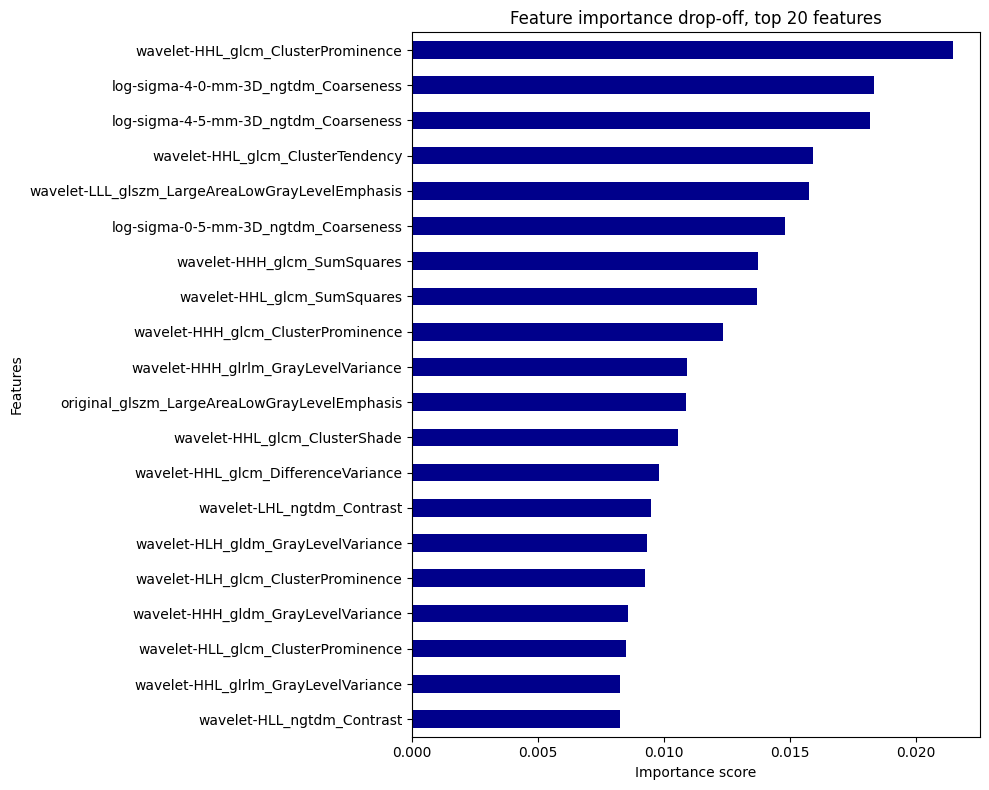

In [29]:
# Diagnostic only, exploratory. General Extra Trees importance plot across all four subtypes at once
# Informational only, did not directly drive a parameter choice

# Fit one Extra Trees model on the full feature set and all four classes
et = ExtraTreesClassifier(n_estimators=100, max_features=20, random_state=42)
et.fit(X_scaled, Y)

# Sort importances ascending so the plot reads highest to lowest top to bottom
importances = pd.Series(et.feature_importances_, index=X_scaled.columns).sort_values(ascending=True)

# Plot the top twenty features by importance
fig, ax = plt.subplots(figsize=(10, 8))
importances.tail(20).plot(kind='barh', color='darkblue', ax=ax)
plt.title("Feature importance drop-off, top 20 features")
plt.xlabel("Importance score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [30]:
# Diagnostic only. Sweeps the correlation removal threshold at stage2_k=10, the value actually adopted
# Result: 0.85 was best (0.978), so the default needed no change, 0.90 (0.968) and 0.80 (0.961) were next
# Not implemented, threshold left at the original 0.85
strict_corr_values = [0.70, 0.80, 0.85, 0.90, 0.95]
corr_sweep_rows = []
for ct in strict_corr_values:
    metrics = diagnose_pair_config(
        X_scaled, Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=ct, et_max_depth=None, et_min_samples_leaf=1,
        max_features=10, svc_C=10.0, ranking_method="tree", n_repeats=5
    )
    corr_sweep_rows.append({"corr_threshold": ct, **metrics})

# Rank and display every threshold by AUC
corr_sweep_df = pd.DataFrame(corr_sweep_rows).set_index("corr_threshold").sort_values("ROC-AUC", ascending=False)
display(corr_sweep_df)

,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
corr_threshold,,,,,,
0.85,0.841478,0.967123,0.83375,0.899936,0.977560,10
0.90,0.842169,0.957534,0.83625,0.896154,0.967670,10
0.80,0.902796,0.928767,0.90875,0.915598,0.961217,10
0.70,0.912467,0.942466,0.91750,0.927224,0.956578,10
0.95,0.827423,0.958904,0.81750,0.888325,0.953846,10


In [31]:
# Diagnostic only. Sweeps Extra Trees minimum leaf size for the stage two ranker
# Result: leaf=1 was best (0.973 vs 0.966 at leaf=3), a small difference, leaf=3 stabilizes importance estimates on wide feature
# sets without over-regularizing
# Implemented, tree_based_pairwise_selection uses min_samples_leaf=3
min_samples_values = [1, 3, 5, 10]
leaf_rows = []
for ms in min_samples_values:
    metrics = diagnose_pair_config(
        X_scaled, Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=ms,
        max_features=20, svc_C=10.0, ranking_method="tree", n_repeats=5
    )
    leaf_rows.append({"et_min_samples_leaf": ms, **metrics})

# Rank and display every leaf size by AUC
leaf_df = pd.DataFrame(leaf_rows).set_index("et_min_samples_leaf").sort_values("ROC-AUC", ascending=False)
display(leaf_df)

,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
et_min_samples_leaf,,,,,,
1,0.851534,0.950685,0.84875,0.898382,0.973171,20
3,0.848259,0.934247,0.84750,0.889179,0.966158,20
5,0.829091,0.936986,0.82375,0.879743,0.966080,20
10,0.826138,0.969863,0.81375,0.892250,0.962721,20


In [32]:
# Diagnostic only. Sweeps the pairwise SVM's regularization strength
# Result: C=100 and C=10 were effectively tied for best (0.974 vs 0.973), both well ahead of C=1 and C=0.1
# Implemented, SymmetricHierarchicalClassifier defaults to C=10.0
svc_c_values = [0.1, 1.0, 10.0, 100.0]
svc_rows = []
for c_val in svc_c_values:
    metrics = diagnose_pair_config(
        X_scaled, Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
        max_features=20, svc_C=c_val, ranking_method="tree", n_repeats=5
    )
    svc_rows.append({"svc_C": c_val, **metrics})

# Rank and display every C value by AUC
svc_df = pd.DataFrame(svc_rows).set_index("svc_C").sort_values("ROC-AUC", ascending=False)
display(svc_df)

,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
svc_C,,,,,,
100.0,0.899083,0.939726,0.90375,0.918955,0.973986,20
10.0,0.851534,0.950685,0.84875,0.898382,0.973171,20
1.0,0.806306,0.980822,0.78500,0.885043,0.961842,20
0.1,0.789661,0.606849,0.85250,0.686290,0.869522,20


In [33]:
# Diagnostic only. Sweeps Extra Trees max depth for the stage two ranker, at the adopted leaf=3, k=10
# Result: depth=5 was best (0.961), unconstrained depth tied with depth=10 and depth=15 at 0.948
# Not implemented, depth left unconstrained
depth_values = [None, 5, 10, 15]
complexity_rows = []
for depth in depth_values:
    metrics = diagnose_pair_config(
        X_scaled, Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=depth, et_min_samples_leaf=3,
        max_features=10, svc_C=10.0, ranking_method="tree", n_repeats=5
    )
    complexity_rows.append({"max_depth": str(depth), **metrics})

# Rank and display every depth value by AUC
depth_df = pd.DataFrame(complexity_rows).set_index("max_depth").sort_values("ROC-AUC", ascending=False)
display(depth_df)

,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
max_depth,,,,,,
5,0.830549,0.953425,0.8225,0.887755,0.960950,10
None,0.820789,0.941096,0.8125,0.876835,0.947835,10
10,0.820789,0.941096,0.8125,0.876835,0.947835,10
15,0.820789,0.941096,0.8125,0.876835,0.947835,10


In [34]:
# Diagnostic only. Tests whether restricting to just the wavelet sub-band that separated Adeno and
# Squamous best in an earlier standalone screen beats using every sub-band together
# Result: every single sub-band alone underperformed the full pool, best single band was HHL at 0.945
# versus 0.974 for all bands combined
# Not implemented

# Extracts the wavelet sub-band code, for example HHH or LLL, from a column name
def get_wavelet_band(col_name):
    match = re.match(r"wavelet-([LH]{3})_", col_name)
    return match.group(1) if match else None

wavelet_band_map = pd.Series(X_scaled.columns).apply(get_wavelet_band)
wavelet_bands = sorted(b for b in wavelet_band_map.unique() if b is not None)

# Build one candidate pool per sub-band, plus the full feature set as a baseline
band_groups = {"All Features": list(X_scaled.columns)}
for band in wavelet_bands:
    band_groups[f"Wavelet {band} Only"] = [c for c, b in zip(X_scaled.columns, wavelet_band_map) if b == band]

band_rows = []
for name, cols in band_groups.items():
    metrics = diagnose_pair_config(
        X_scaled[cols], Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
        max_features=min(20, len(cols)), svc_C=10.0, n_repeats=10
    )
    band_rows.append({"Feature Group": name, "Pool Size": len(cols), **metrics})
    print(f"{name} (pool={len(cols)}): Sensitivity={metrics['Sensitivity']:.3f}  "
          f"Specificity={metrics['Specificity']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}")

# Rank and display every sub-band pool by AUC
band_df = pd.DataFrame(band_rows).set_index("Feature Group").sort_values("ROC-AUC", ascending=False)
display(band_df)

All Features (pool=1781): Sensitivity=0.955  Specificity=0.856  ROC-AUC=0.974
Wavelet HHH Only (pool=93): Sensitivity=0.918  Specificity=0.784  ROC-AUC=0.906
Wavelet HHL Only (pool=93): Sensitivity=0.910  Specificity=0.833  ROC-AUC=0.945
Wavelet HLH Only (pool=93): Sensitivity=0.774  Specificity=0.756  ROC-AUC=0.828
Wavelet HLL Only (pool=93): Sensitivity=0.914  Specificity=0.795  ROC-AUC=0.921
Wavelet LHH Only (pool=93): Sensitivity=0.690  Specificity=0.805  ROC-AUC=0.852
Wavelet LHL Only (pool=93): Sensitivity=0.880  Specificity=0.808  ROC-AUC=0.922
Wavelet LLH Only (pool=93): Sensitivity=0.812  Specificity=0.797  ROC-AUC=0.881
Wavelet LLL Only (pool=93): Sensitivity=0.905  Specificity=0.791  ROC-AUC=0.864


,Pool Size,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
Feature Group,,,,,,,
All Features,1781,0.857934,0.955479,0.855625,0.904083,0.973933,20
Wavelet HHL Only,93,0.832080,0.909589,0.832500,0.869110,0.944565,20
Wavelet LHL Only,93,0.807161,0.880137,0.808125,0.842071,0.922266,20
Wavelet HLL Only,93,0.802766,0.914384,0.795000,0.854947,0.920581,20
Wavelet HHH Only,93,0.794781,0.917808,0.783750,0.851875,0.906436,20
Wavelet LLH Only,93,0.784768,0.811644,0.796875,0.797980,0.881217,20
Wavelet LLL Only,93,0.797827,0.905479,0.790625,0.848252,0.864113,20
Wavelet LHH Only,93,0.763457,0.689726,0.805000,0.724721,0.851713,20
Wavelet HLH Only,93,0.742932,0.773973,0.755625,0.758135,0.828229,20


In [35]:
# Diagnostic only. Tests fine versus coarse Laplacian of Gaussian smoothing scales in isolation
# Result: both fine and coarse scales alone underperformed the full pool
# Not implemented

# Extracts the LoG sigma value, for example 0.5 or 3.0, from a column name
def get_log_sigma(col_name):
    match = re.match(r"log-sigma-(\d)-(\d)-mm-3D_", col_name)
    return float(f"{match.group(1)}.{match.group(2)}") if match else None

log_sigma_map = pd.Series(X_scaled.columns).apply(get_log_sigma)

# Build fine scale, coarse scale, and full feature pools
sigma_groups = {
    "All Features": list(X_scaled.columns),
    "Fine Scale LoG (sigma 0.5 to 1.5mm)": [c for c, s in zip(X_scaled.columns, log_sigma_map) if s is not None and s <= 1.5],
    "Coarse Scale LoG (sigma 3.5 to 5.0mm)": [c for c, s in zip(X_scaled.columns, log_sigma_map) if s is not None and s >= 3.5],
}

sigma_rows = []
for name, cols in sigma_groups.items():
    metrics = diagnose_pair_config(
        X_scaled[cols], Y, pos_class=1, neg_class=2,
        prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
        max_features=min(20, len(cols)), svc_C=10.0, n_repeats=10
    )
    sigma_rows.append({"Feature Group": name, "Pool Size": len(cols), **metrics})
    print(f"{name} (pool={len(cols)}): Sensitivity={metrics['Sensitivity']:.3f}  "
          f"Specificity={metrics['Specificity']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}")

# Rank and display every scale pool by AUC
sigma_df = pd.DataFrame(sigma_rows).set_index("Feature Group").sort_values("ROC-AUC", ascending=False)
display(sigma_df)

All Features (pool=1781): Sensitivity=0.955  Specificity=0.856  ROC-AUC=0.974
Fine Scale LoG (sigma 0.5 to 1.5mm) (pool=279): Sensitivity=0.879  Specificity=0.805  ROC-AUC=0.911
Coarse Scale LoG (sigma 3.5 to 5.0mm) (pool=372): Sensitivity=0.908  Specificity=0.814  ROC-AUC=0.932


,Pool Size,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Avg Features Selected
Feature Group,,,,,,,
All Features,1781,0.857934,0.955479,0.855625,0.904083,0.973933,20
Coarse Scale LoG (sigma 3.5 to 5.0mm),372,0.816502,0.908219,0.813750,0.859922,0.931750,20
Fine Scale LoG (sigma 0.5 to 1.5mm),279,0.804389,0.878767,0.805000,0.839935,0.911460,20


In [36]:
# Diagnostic only. Sweeps the pairwise decision threshold on the isolated Adeno versus Squamous problem
# Result: 0.30 to 0.60 all cleared 0.80 on precision, sensitivity, specificity, and F1 simultaneously
# Motivated the confidence threshold mechanism built into the final without-NOS pipeline below

# Get raw pooled true labels and probabilities instead of a single fixed threshold metrics dict
all_true, all_prob = diagnose_pair_config(
    X_scaled, Y, pos_class=1, neg_class=2,
    prefilter_k=None, corr_threshold=0.85, et_max_depth=None, et_min_samples_leaf=1,
    max_features=20, svc_C=10.0, n_repeats=10, return_raw=True
)

# Recompute metrics at each candidate threshold from the same pooled predictions
threshold_rows = []
for thresh in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    y_true_bin = (all_true == 1).astype(int)
    y_pred_bin = (all_prob >= thresh).astype(int)

    prec = precision_score(y_true_bin, y_pred_bin, zero_division=0)
    sens = recall_score(y_true_bin, y_pred_bin, zero_division=0)
    cm = confusion_matrix(y_true_bin, y_pred_bin)
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = f1_score(y_true_bin, y_pred_bin, zero_division=0)

    threshold_rows.append({"Threshold": thresh, "Precision": prec, "Sensitivity": sens, "Specificity": spec, "F1-Score": f1})
    print(f"Threshold={thresh:.2f}: Adeno Sensitivity={sens:.3f}  Squamous Specificity={spec:.3f}  F1={f1:.3f}")

threshold_df = pd.DataFrame(threshold_rows).set_index("Threshold")
display(threshold_df)

Threshold=0.30: Adeno Sensitivity=0.965  Squamous Specificity=0.838  F1=0.901
Threshold=0.35: Adeno Sensitivity=0.955  Squamous Specificity=0.857  F1=0.905
Threshold=0.40: Adeno Sensitivity=0.951  Squamous Specificity=0.874  F1=0.910
Threshold=0.45: Adeno Sensitivity=0.938  Squamous Specificity=0.886  F1=0.909
Threshold=0.50: Adeno Sensitivity=0.928  Squamous Specificity=0.894  F1=0.908
Threshold=0.55: Adeno Sensitivity=0.905  Squamous Specificity=0.903  F1=0.900
Threshold=0.60: Adeno Sensitivity=0.890  Squamous Specificity=0.912  F1=0.897


,Precision,Sensitivity,Specificity,F1-Score
Threshold,,,,
0.30,0.844724,0.965068,0.838125,0.900895
0.35,0.858990,0.955479,0.856875,0.904669
0.40,0.873505,0.950685,0.874375,0.910462
0.45,0.882088,0.937671,0.885625,0.909031
0.50,0.889108,0.928082,0.894375,0.908177
0.55,0.895058,0.905479,0.903125,0.900238
0.60,0.902778,0.890411,0.912500,0.896552


In [37]:
# Diagnostic only. Tests a much smaller curated feature count with a simpler linear model against the
# wider rbf setup
# Result: rbf held up down to 3 features (ROC-AUC 0.998), logistic regression kept a usable AUC (0.88 to 0.97) but its sensitivity fell to between 0.53 and 0.61 at every size tested
# Confirmed rbf is the better fit for this boundary, no change made since this validated the existing setup
def diagnose_pair_small_curated(X_full, y_full, pos_class, neg_class, max_features, model_type="svc_rbf",
                                 n_splits=5, n_repeats=10):
    mask = y_full.isin([pos_class, neg_class])
    X_pair, y_pair = X_full[mask], y_full[mask]

    # Rank by Extra Trees importance and drop correlated duplicates once here, before cross-validation
    # starts, instead of refitting the ranking inside every fold
    candidates = list(X_pair.columns)
    et = ExtraTreesClassifier(n_estimators=100, class_weight="balanced", random_state=42)
    et.fit(X_pair[candidates], y_pair)
    ranked = [candidates[i] for i in np.argsort(et.feature_importances_)[::-1]]
    final_feats = remove_high_correlation(X_pair, ranked, threshold=0.85)[:max_features]

    def run_fold(train_idx, test_idx):
        # Feature selection already happened once above, this only fits and predicts on the fold
        X_train, X_test = X_pair.iloc[train_idx], X_pair.iloc[test_idx]
        y_train, y_test = y_pair.iloc[train_idx], y_pair.iloc[test_idx]

        # Choose the model type for this run
        if model_type == "svc_rbf":
            clf = SVC(kernel="rbf", C=10.0, gamma="scale", probability=True, class_weight="balanced", random_state=42)
        elif model_type == "logistic":
            clf = LogisticRegression(max_iter=5000, class_weight="balanced", random_state=42)
        else:
            raise ValueError(f"Unknown model_type: {model_type}")

        clf.fit(X_train[final_feats], y_train)
        pos_idx = list(clf.classes_).index(pos_class)
        y_pred = clf.predict(X_test[final_feats])
        y_prob_pos = clf.predict_proba(X_test[final_feats])[:, pos_idx]
        return y_test.tolist(), y_pred.tolist(), y_prob_pos.tolist()

    n_jobs = max(1, (os.cpu_count() or 4) - 1)
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)
    with parallel_backend("loky", inner_max_num_threads=1):
        fold_results = Parallel(n_jobs=n_jobs)(
            delayed(run_fold)(train_idx, test_idx)
            for train_idx, test_idx in rskf.split(X_pair, y_pair)
        )

    all_true, all_pred, all_prob = [], [], []
    for y_true, y_pred, y_prob in fold_results:
        all_true.extend(y_true)
        all_pred.extend(y_pred)
        all_prob.extend(y_prob)

    all_true = np.array(all_true)
    all_pred = np.array(all_pred)
    all_prob = np.array(all_prob)
    y_true_bin = (all_true == pos_class).astype(int)
    y_pred_bin = (all_pred == pos_class).astype(int)
    cm = confusion_matrix(y_true_bin, y_pred_bin)
    tn, fp, fn, tp = cm.ravel()

    return {
        "Precision": precision_score(y_true_bin, y_pred_bin, zero_division=0),
        "Sensitivity": recall_score(y_true_bin, y_pred_bin, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "F1-Score": f1_score(y_true_bin, y_pred_bin, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true_bin, all_prob)
    }

# Sweep every combination of feature count and model type
curated_size_rows = []
for mf in [3, 5, 8, 10]:
    for model_type in ["svc_rbf", "logistic"]:
        metrics = diagnose_pair_small_curated(X_scaled, Y, pos_class=1, neg_class=2, max_features=mf, model_type=model_type, n_repeats=10)
        curated_size_rows.append({"max_features": mf, "Model": model_type, **metrics})
        print(f"max_features={mf}, model={model_type}: Sensitivity={metrics['Sensitivity']:.3f}  "
              f"Specificity={metrics['Specificity']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}")

# Rank and display every combination by AUC
curated_size_df = pd.DataFrame(curated_size_rows).set_index(["max_features", "Model"]).sort_values("ROC-AUC", ascending=False)
display(curated_size_df)

max_features=3, model=svc_rbf: Sensitivity=0.989  Specificity=0.984  ROC-AUC=0.998
max_features=3, model=logistic: Sensitivity=0.528  Specificity=0.967  ROC-AUC=0.969
max_features=5, model=svc_rbf: Sensitivity=0.955  Specificity=0.919  ROC-AUC=0.952
max_features=5, model=logistic: Sensitivity=0.611  Specificity=0.977  ROC-AUC=0.925
max_features=8, model=svc_rbf: Sensitivity=0.952  Specificity=0.876  ROC-AUC=0.967
max_features=8, model=logistic: Sensitivity=0.596  Specificity=0.964  ROC-AUC=0.898
max_features=10, model=svc_rbf: Sensitivity=0.970  Specificity=0.838  ROC-AUC=0.980
max_features=10, model=logistic: Sensitivity=0.564  Specificity=0.954  ROC-AUC=0.883


Precision  Sensitivity  Specificity  F1-Score   ROC-AUC
max_features Model                                                            
3            svc_rbf    0.982982     0.989041     0.984375  0.986002  0.998170
10           svc_rbf    0.845373     0.969863     0.838125  0.903349  0.980152
3            logistic   0.935680     0.528082     0.966875  0.675131  0.969337
8            svc_rbf    0.874764     0.952055     0.875625  0.911774  0.966603
5            svc_rbf    0.914698     0.954795     0.918750  0.934316  0.952365
             logistic   0.960172     0.610959     0.976875  0.746756  0.925044
8            logistic   0.937500     0.595890     0.963750  0.728643  0.898304
10           logistic   0.917503     0.563699     0.953750  0.698345  0.883118

In [38]:
# Diagnostic only. Measures how often true Adenocarcinoma and Squamous cases survive into stage one's
# top two candidates before any pairwise classifier is involved
# Selection now runs once on the full dataset before cross-validation starts, standardizing the
# feature set every fold uses instead of re-selecting it per fold
def diagnose_stage1_routing(X_df, y_ser, target_classes, method="lasso", n_splits=5, n_repeats=10):
    base_estimator = LogisticRegression(max_iter=5000, class_weight="balanced", random_state=42)
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)

    # Only stage one features are needed here, stage two candidates are discarded, selected once up
    # front instead of inside every fold
    stage1_feats, _, _, _ = extract_all_pipeline_features(X_df, y_ser, method=method)

    def run_fold(train_idx, test_idx):
        X_train, X_test = X_df.iloc[train_idx], X_df.iloc[test_idx]
        y_train, y_test = y_ser.iloc[train_idx], y_ser.iloc[test_idx]

        clf_stage1 = clone(base_estimator)
        clf_stage1.fit(X_train[stage1_feats], y_train)

        probs = clf_stage1.predict_proba(X_test[stage1_feats])
        rows = []
        for i in range(len(X_test)):
            true_label = y_test.iloc[i]
            # Only record samples whose true label is one of the two target classes
            if true_label not in target_classes:
                continue
            top2_idx = np.argsort(probs[i])[::-1][:2]
            top2_classes = tuple(sorted(clf_stage1.classes_[top2_idx]))
            rows.append({"true_label": true_label, "stage1_top2": top2_classes})
        return rows

    n_jobs = max(1, (os.cpu_count() or 4) - 1)
    with parallel_backend("loky", inner_max_num_threads=1):
        fold_results = Parallel(n_jobs=n_jobs)(
            delayed(run_fold)(train_idx, test_idx)
            for train_idx, test_idx in rskf.split(X_df, y_ser)
        )

    all_rows = [row for fold in fold_results for row in fold]
    return pd.DataFrame(all_rows)

target_pair = (1, 2)
routing_df = diagnose_stage1_routing(X_scaled, Y, target_classes=list(target_pair), method="lasso", n_repeats=10)

# Overall rate at which stage one routed a true Adeno or Squamous sample into exactly this pair
correct_pair_rate = (routing_df["stage1_top2"] == target_pair).mean()
print(f"Share of true Adenocarcinoma or Squamous test samples where stage one's top two exactly matched "
      f"the Adeno versus Squamous pair: {correct_pair_rate:.3f}")

# Break the same result down by which of the two classes was the true label
for label_val in target_pair:
    label_name = label_map[label_val]
    subset = routing_df[routing_df["true_label"] == label_val]
    hit_rate = (subset["stage1_top2"] == target_pair).mean()
    print(f"\nTrue label {label_name}, n={len(subset)}, correctly routed into the Adeno vs Squamous pair: {hit_rate:.3f}")
    print(subset["stage1_top2"].value_counts(normalize=True).rename("Share of Samples"))

Share of true Adenocarcinoma or Squamous test samples where stage one's top two exactly matched the Adeno versus Squamous pair: 0.842

True label Adenocarcinoma, n=1460, correctly routed into the Adeno vs Squamous pair: 0.697
stage1_top2
(1, 2)    0.696575
(0, 1)    0.254110
(2, 3)    0.022603
(1, 3)    0.015753
(0, 2)    0.010959
Name: Share of Samples, dtype: float64

True label Squamous, n=1600, correctly routed into the Adeno vs Squamous pair: 0.974
stage1_top2
(1, 2)    0.973750
(0, 2)    0.011250
(2, 3)    0.010625
(0, 1)    0.004375
Name: Share of Samples, dtype: float64


In [39]:
# Diagnostic harness for stage one alone, generalized across all four subtypes
# Selection runs once on the full dataset before cross-validation starts, standardizing the
# feature set every fold uses instead of re-selecting it per fold
def diagnose_stage1_config(X_df, y_ser, method="lasso", stage1_k=20, C=1.0,
                            classifier_type="multinomial", class_weight="balanced",
                            n_splits=5, n_repeats=10):
    # Pick the selection function for this run
    if method == "lasso":
        select_fn = select_features_lasso
    elif method == "wrapper":
        select_fn = select_features_wrapper
    elif method == "mars":
        select_fn = select_features_mars
    else:
        raise ValueError(f"Unknown method: {method}")

    # Feature selection happens once here instead of inside every fold below
    stage1_feats, _ = select_fn(X_df, y_ser, pool_k=stage1_k)

    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)

    def run_fold(train_idx, test_idx):
        X_train, X_test = X_df.iloc[train_idx], X_df.iloc[test_idx]
        y_train, y_test = y_ser.iloc[train_idx], y_ser.iloc[test_idx]

        # Dampened scheme keeps rarer classes up-weighted but less aggressively than balanced,
        # computed from the training fold only so it stays fold-safe
        if class_weight == "dampened":
            counts = y_train.value_counts()
            balanced_weights = len(y_train) / (counts.shape[0] * counts)
            cw_param = np.sqrt(balanced_weights).to_dict()
        else:
            cw_param = class_weight

        base_clf = LogisticRegression(max_iter=5000, C=C, class_weight=cw_param, random_state=42)
        if classifier_type == "multinomial":
            clf_stage1 = base_clf
        elif classifier_type == "ovr":
            # One independent binary boundary per class instead of one shared multinomial surface
            clf_stage1 = OneVsRestClassifier(base_clf)
        else:
            raise ValueError(f"Unknown classifier_type: {classifier_type}")

        clf_stage1.fit(X_train[stage1_feats], y_train)
        probs = clf_stage1.predict_proba(X_test[stage1_feats])
        classes_ = clf_stage1.classes_

        # Record both the single top prediction and the top two for every test sample
        rows = []
        for i in range(len(X_test)):
            true_label = y_test.iloc[i]
            top2_idx = np.argsort(probs[i])[::-1][:2]
            top2_classes = tuple(sorted(classes_[top2_idx]))
            top1_class = classes_[np.argmax(probs[i])]
            rows.append({"true_label": true_label, "stage1_top1": top1_class, "stage1_top2": top2_classes})
        return rows

    n_jobs = max(1, (os.cpu_count() or 4) - 1)
    with parallel_backend("loky", inner_max_num_threads=1):
        fold_results = Parallel(n_jobs=n_jobs)(
            delayed(run_fold)(train_idx, test_idx)
            for train_idx, test_idx in rskf.split(X_df, y_ser)
        )

    routing_df = pd.DataFrame([row for fold in fold_results for row in fold])

    # Summarize top one correct rate and top two inclusion rate for every true subtype
    summary_rows = []
    for label_val in sorted(y_ser.unique()):
        subset = routing_df[routing_df["true_label"] == label_val]
        summary_rows.append({
            "True Subtype": label_map[label_val], "N": len(subset),
            "Top 1 Correct Rate": (subset["stage1_top1"] == label_val).mean(),
            "Top 2 Inclusion Rate": subset["stage1_top2"].apply(lambda pair: label_val in pair).mean(),
        })

    return pd.DataFrame(summary_rows).set_index("True Subtype"), routing_df

In [40]:
# Diagnostic only. Baseline stage one routing across all four subtypes at the original baseline settings, C=1 and balanced class weight
# Result: Adenocarcinoma was the weakest, 63.6 percent top one correct, 96.6 percent top two
# inclusion, versus 73.6 to 99.3 percent top one correct for the other three subtypes
base_summary_df, base_routing_df = diagnose_stage1_config(
    X_scaled, Y, method="lasso", stage1_k=20, C=1.0, classifier_type="multinomial", class_weight="balanced", n_repeats=10
)
print("Stage one routing summary, current production settings")
display(base_summary_df)

# Break down exactly which pair of classes stage one confused each true subtype with
for label_val in sorted(Y.unique()):
    label_name = label_map[label_val]
    subset = base_routing_df[base_routing_df["true_label"] == label_val]
    print(f"\nTrue label {label_name}, n={len(subset)}, stage one top two breakdown")
    print(subset["stage1_top2"].value_counts(normalize=True).rename("Share of Samples"))

Stage one routing summary, current production settings


,N,Top 1 Correct Rate,Top 2 Inclusion Rate
True Subtype,,,
NOS,530,0.920755,0.943396
Adenocarcinoma,1460,0.635616,0.966438
Squamous,1600,0.736250,0.995625
Large-Cell,960,0.992708,1.000000



True label NOS, n=530, stage one top two breakdown
stage1_top2
(0, 1)    0.907547
(1, 2)    0.041509
(0, 2)    0.035849
(2, 3)    0.015094
Name: Share of Samples, dtype: float64

True label Adenocarcinoma, n=1460, stage one top two breakdown
stage1_top2
(1, 2)    0.696575
(0, 1)    0.254110
(2, 3)    0.022603
(1, 3)    0.015753
(0, 2)    0.010959
Name: Share of Samples, dtype: float64

True label Squamous, n=1600, stage one top two breakdown
stage1_top2
(1, 2)    0.973750
(0, 2)    0.011250
(2, 3)    0.010625
(0, 1)    0.004375
Name: Share of Samples, dtype: float64

True label Large-Cell, n=960, stage one top two breakdown
stage1_top2
(2, 3)    0.965625
(1, 3)    0.034375
Name: Share of Samples, dtype: float64


In [41]:
# Diagnostic only. Sweeps stage one's own feature pool size
# Result: k=40 gave Adenocarcinoma its best top two inclusion (97.8 percent), but Squamous preferred smaller pools,
# no single value best for both
stage1_k_rows = []
for k in [10, 20, 30, 40]:
    summary_df, _ = diagnose_stage1_config(X_scaled, Y, method="lasso", stage1_k=k, n_repeats=10)
    summary_df["stage1_k"] = k
    stage1_k_rows.append(summary_df)
    print(f"\nstage1_k={k}")
    print(summary_df[["N", "Top 1 Correct Rate", "Top 2 Inclusion Rate"]].to_string())

# Combine every value into one table for side by side comparison
stage1_k_df = pd.concat(stage1_k_rows)
display(stage1_k_df)


stage1_k=10
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.943396              0.943396
Adenocarcinoma  1460            0.649315              0.971918
Squamous        1600            0.791250              0.996875
Large-Cell       960            0.995833              1.000000

stage1_k=20
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.920755              0.943396
Adenocarcinoma  1460            0.635616              0.966438
Squamous        1600            0.736250              0.995625
Large-Cell       960            0.992708              1.000000

stage1_k=30
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.915094              0.945283
Adenocarcinoma  

,N,Top 1 Correct Rate,Top 2 Inclusion Rate,stage1_k
True Subtype,,,,
NOS,530,0.943396,0.943396,10
Adenocarcinoma,1460,0.649315,0.971918,10
Squamous,1600,0.791250,0.996875,10
Large-Cell,960,0.995833,1.000000,10
NOS,530,0.920755,0.943396,20
Adenocarcinoma,1460,0.635616,0.966438,20
Squamous,1600,0.736250,0.995625,20
Large-Cell,960,0.992708,1.000000,20
NOS,530,0.915094,0.945283,30


In [42]:
# Diagnostic only. Sweeps stage one's regularization strength
# Result: C=10 gave the largest single gain found anywhere in this investigation, Adenocarcinoma top
# one correct rose from 63.6 to 75.8 percent
# Implemented, stage one uses C=10 in the final without-NOS pipeline
stage1_c_rows = []
for c_val in [0.1, 1.0, 10.0]:
    summary_df, _ = diagnose_stage1_config(X_scaled, Y, method="lasso", C=c_val, n_repeats=10)
    summary_df["C"] = c_val
    stage1_c_rows.append(summary_df)
    print(f"\nC={c_val}")
    print(summary_df[["N", "Top 1 Correct Rate", "Top 2 Inclusion Rate"]].to_string())

# Combine every value into one table for side by side comparison
stage1_c_df = pd.concat(stage1_c_rows)
display(stage1_c_df)


C=0.1
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.924528              0.943396
Adenocarcinoma  1460            0.566438              0.930822
Squamous        1600            0.673750              0.975000
Large-Cell       960            0.993750              1.000000

C=1.0
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.920755              0.943396
Adenocarcinoma  1460            0.635616              0.966438
Squamous        1600            0.736250              0.995625
Large-Cell       960            0.992708              1.000000

C=10.0
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.924528              0.943396
Adenocarcinoma  1460            0

,N,Top 1 Correct Rate,Top 2 Inclusion Rate,C
True Subtype,,,,
NOS,530,0.924528,0.943396,0.1
Adenocarcinoma,1460,0.566438,0.930822,0.1
Squamous,1600,0.673750,0.975000,0.1
Large-Cell,960,0.993750,1.000000,0.1
NOS,530,0.920755,0.943396,1.0
Adenocarcinoma,1460,0.635616,0.966438,1.0
Squamous,1600,0.736250,0.995625,1.0
Large-Cell,960,0.992708,1.000000,1.0
NOS,530,0.924528,0.943396,10.0


In [43]:
# Diagnostic only. Tests one shared multinomial boundary versus four independent one versus rest
# boundaries for stage one
# Result: ovr was slightly worse than multinomial (Adenocarcinoma top one correct 60.9 vs 63.6 percent, Squamous 68.4 vs 73.6 percent)
# Not implemented
classifier_type_rows = []
for ctype in ["multinomial", "ovr"]:
    summary_df, _ = diagnose_stage1_config(X_scaled, Y, method="lasso", classifier_type=ctype, n_repeats=10)
    summary_df["classifier_type"] = ctype
    classifier_type_rows.append(summary_df)
    print(f"\nclassifier_type={ctype}")
    print(summary_df[["N", "Top 1 Correct Rate", "Top 2 Inclusion Rate"]].to_string())

# Combine both classifier types into one table for side by side comparison
classifier_type_df = pd.concat(classifier_type_rows)
display(classifier_type_df)


classifier_type=multinomial
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.920755              0.943396
Adenocarcinoma  1460            0.635616              0.966438
Squamous        1600            0.736250              0.995625
Large-Cell       960            0.992708              1.000000

classifier_type=ovr
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.901887              0.943396
Adenocarcinoma  1460            0.608904              0.947945
Squamous        1600            0.683750              0.998750
Large-Cell       960            0.991667              1.000000


,N,Top 1 Correct Rate,Top 2 Inclusion Rate,classifier_type
True Subtype,,,,
NOS,530,0.920755,0.943396,multinomial
Adenocarcinoma,1460,0.635616,0.966438,multinomial
Squamous,1600,0.736250,0.995625,multinomial
Large-Cell,960,0.992708,1.000000,multinomial
NOS,530,0.901887,0.943396,ovr
Adenocarcinoma,1460,0.608904,0.947945,ovr
Squamous,1600,0.683750,0.998750,ovr
Large-Cell,960,0.991667,1.000000,ovr


In [44]:
# Diagnostic only. Tests balanced, unweighted, and a dampened class weighting scheme for stage one
# Result: dampened kept over half of the unweighted scheme's Squamous gain (76.8 vs 79.0 percent top one correct, from 73.6
# balanced) while NOS and Large-Cell were essentially unchanged by any scheme
# Implemented, stage one uses dampened weighting in the final without-NOS pipeline
class_weight_rows = []
for cw in ["balanced", None, "dampened"]:
    summary_df, _ = diagnose_stage1_config(X_scaled, Y, method="lasso", class_weight=cw, n_repeats=10)
    summary_df["class_weight"] = str(cw)
    class_weight_rows.append(summary_df)
    print(f"\nclass_weight={cw}")
    print(summary_df[["N", "Top 1 Correct Rate", "Top 2 Inclusion Rate"]].to_string())

# Combine every scheme into one table for side by side comparison
class_weight_df = pd.concat(class_weight_rows)
display(class_weight_df)


class_weight=balanced
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.920755              0.943396
Adenocarcinoma  1460            0.635616              0.966438
Squamous        1600            0.736250              0.995625
Large-Cell       960            0.992708              1.000000

class_weight=None
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.920755              0.943396
Adenocarcinoma  1460            0.627397              0.971233
Squamous        1600            0.790000              0.997500
Large-Cell       960            0.990625              0.998958

class_weight=dampened
                   N  Top 1 Correct Rate  Top 2 Inclusion Rate
True Subtype                                                  
NOS              530            0.920755             

,N,Top 1 Correct Rate,Top 2 Inclusion Rate,class_weight
True Subtype,,,,
NOS,530,0.920755,0.943396,balanced
Adenocarcinoma,1460,0.635616,0.966438,balanced
Squamous,1600,0.736250,0.995625,balanced
Large-Cell,960,0.992708,1.000000,balanced
NOS,530,0.920755,0.943396,None
Adenocarcinoma,1460,0.627397,0.971233,None
Squamous,1600,0.790000,0.997500,None
Large-Cell,960,0.990625,0.998958,None
NOS,530,0.920755,0.943396,dampened


In [45]:
# Diagnostic only. Tests whether excluding NOS from training sharpens stage one's Adeno versus
# Squamous boundary
# Result: excluding NOS raised Adenocarcinoma top one correct from 63.6 to 72.9 percent and lowered
# Adenocarcinoma mistaken for Squamous from 27.9 to 25.7 percent
# Directly motivated building the separate without-NOS pipeline below
no_nos_mask = Y != 0

summary_with_nos, routing_with_nos = diagnose_stage1_config(X_scaled, Y, method="lasso", n_repeats=10)
summary_without_nos, routing_without_nos = diagnose_stage1_config(X_scaled[no_nos_mask], Y[no_nos_mask], method="lasso", n_repeats=10)

print("With NOS included, four subtypes")
display(summary_with_nos)
print("\nWith NOS excluded, three subtypes")
print("Top 2 inclusion rate is not directly comparable across these two tables, top 1 correct rate")
print("and the confusion breakdown below are the fair comparisons")
display(summary_without_nos)

# Rate at which one true class gets predicted as a specific other class
def confusion_rate(routing_df, true_class, predicted_class, true_name, predicted_name):
    subset = routing_df[routing_df["true_label"] == true_class]
    rate = (subset["stage1_top1"] == predicted_class).mean()
    print(f"True {true_name} predicted as {predicted_name}: {rate:.3f} (n={len(subset)})")
    return rate

print("\nAdenocarcinoma mistaken for Squamous, at stage one's single top prediction")
confusion_rate(routing_with_nos, true_class=1, predicted_class=2, true_name="Adenocarcinoma (NOS included)", predicted_name="Squamous")
confusion_rate(routing_without_nos, true_class=1, predicted_class=2, true_name="Adenocarcinoma (NOS excluded)", predicted_name="Squamous")

print("\nSquamous mistaken for Adenocarcinoma, checked for symmetry")
confusion_rate(routing_with_nos, true_class=2, predicted_class=1, true_name="Squamous (NOS included)", predicted_name="Adenocarcinoma")
confusion_rate(routing_without_nos, true_class=2, predicted_class=1, true_name="Squamous (NOS excluded)", predicted_name="Adenocarcinoma")

With NOS included, four subtypes


,N,Top 1 Correct Rate,Top 2 Inclusion Rate
True Subtype,,,
NOS,530,0.920755,0.943396
Adenocarcinoma,1460,0.635616,0.966438
Squamous,1600,0.736250,0.995625
Large-Cell,960,0.992708,1.000000



With NOS excluded, three subtypes
Top 2 inclusion rate is not directly comparable across these two tables, top 1 correct rate
and the confusion breakdown below are the fair comparisons


,N,Top 1 Correct Rate,Top 2 Inclusion Rate
True Subtype,,,
Adenocarcinoma,1460,0.729452,0.991096
Squamous,1600,0.795625,0.994375
Large-Cell,960,0.990625,0.995833



Adenocarcinoma mistaken for Squamous, at stage one's single top prediction
True Adenocarcinoma (NOS included) predicted as Squamous: 0.279 (n=1460)
True Adenocarcinoma (NOS excluded) predicted as Squamous: 0.257 (n=1460)

Squamous mistaken for Adenocarcinoma, checked for symmetry
True Squamous (NOS included) predicted as Adenocarcinoma: 0.249 (n=1600)
True Squamous (NOS excluded) predicted as Adenocarcinoma: 0.204 (n=1600)


0.204375

In [46]:
# Diagnostic only. Candidate A, NOS removed, otherwise the original stage one defaults of C=1 and balanced class weight, the baseline every other
# candidate below is measured against
candA_table, candA_true, candA_pred, candA_prob = evaluate_candidate_pipeline(
    X_scaled[no_nos_mask], Y[no_nos_mask], method="lasso", stage1_k=20,
    stage1_C=1.0, stage1_class_weight="balanced", label_map=label_map_3class, n_repeats=5
)
print("Candidate A: NOS removed, production defaults otherwise")
print(candA_table.to_string())

Candidate A: NOS removed, production defaults otherwise
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.840506     0.909589  0.873684     0.901563  0.909589  0.969293
Squamous         0.911409     0.848750  0.878964     0.945455  0.848750  0.972080
Large-Cell       0.989474     0.979167  0.984293     0.996732  0.979167  0.996675
Average          0.913796     0.912502  0.912314     0.947916  0.901990  0.979349


In [47]:
# Diagnostic only. Candidate B, adds stage one C=10
candB_table, candB_true, candB_pred, candB_prob = evaluate_candidate_pipeline(
    X_scaled[no_nos_mask], Y[no_nos_mask], method="lasso", stage1_k=20,
    stage1_C=10.0, stage1_class_weight="balanced", label_map=label_map_3class, n_repeats=5
)
print("Candidate B: NOS removed, stage one C=10")
print(candB_table.to_string())

Candidate B: NOS removed, stage one C=10
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.860645     0.913699  0.886379     0.915625  0.913699  0.976831
Squamous         0.906946     0.865000  0.885477     0.941322  0.865000  0.974577
Large-Cell       0.995763     0.979167  0.987395     0.998693  0.979167  0.999846
Average          0.921118     0.919288  0.919750     0.951880  0.909950  0.983751


In [48]:
# Diagnostic only. Candidate C, adds dampened class weighting on top of candidate B
candC_table, candC_true, candC_pred, candC_prob = evaluate_candidate_pipeline(
    X_scaled[no_nos_mask], Y[no_nos_mask], method="lasso", stage1_k=20,
    stage1_C=10.0, stage1_class_weight="dampened", label_map=label_map_3class, n_repeats=5
)
print("Candidate C: NOS removed, stage one C=10, dampened class weight")
print(candC_table.to_string())

Candidate C: NOS removed, stage one C=10, dampened class weight
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.861757     0.913699  0.886968     0.916406  0.913699  0.976904
Squamous         0.907068     0.866250  0.886189     0.941322  0.866250  0.974656
Large-Cell       0.995763     0.979167  0.987395     0.998693  0.979167  0.999846
Average          0.921529     0.919705  0.920184     0.952140  0.910448  0.983802


In [49]:
# Diagnostic only. Candidate D, widens the stage one feature pool on top of candidate C
candD_table, candD_true, candD_pred, candD_prob = evaluate_candidate_pipeline(
    X_scaled[no_nos_mask], Y[no_nos_mask], method="lasso", stage1_k=30,
    stage1_C=10.0, stage1_class_weight="dampened", label_map=label_map_3class, n_repeats=5
)
print("Candidate D: NOS removed, stage one C=10, dampened class weight, stage1_k=30")
print(candD_table.to_string())

Candidate D: NOS removed, stage one C=10, dampened class weight, stage1_k=30
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.848408     0.912329  0.879208     0.907031  0.912329  0.975681
Squamous         0.901987     0.851250  0.875884     0.938843  0.851250  0.970305
Large-Cell       1.000000     0.979167  0.989474     1.000000  0.979167  0.994602
Average          0.916798     0.914248  0.914855     0.948625  0.903980  0.980196


In [50]:
# Diagnostic only. Side by side comparison of all four candidates
# Result: candidate C won, C=10 plus dampened weighting at the default stage1_k=20, candidate D's
# wider pool made Adenocarcinoma and Squamous results worse
# Implemented, candidate C's configuration is the final without-NOS stage one setup below

# Pull Adenocarcinoma, Squamous, and Large-Cell rows out of each candidate's metrics table
comparison_rows = []
for name, table in [("A: Baseline", candA_table), ("B: C=10", candB_table),
                     ("C: C=10 + Dampened", candC_table), ("D: C=10 + Dampened + k=30", candD_table)]:
    for subtype in ["Adenocarcinoma", "Squamous", "Large-Cell"]:
        row = table.loc[subtype]
        comparison_rows.append({
            "Candidate": name, "Subtype": subtype, "Precision": row["Precision"], "Sensitivity": row["Sensitivity"],
            "Specificity": row["Specificity"], "F1-Score": row["F1-Score"], "ROC-AUC": row["ROC-AUC"]
        })

# Display every candidate grouped by subtype for easy comparison
comparison_df = pd.DataFrame(comparison_rows).set_index(["Subtype", "Candidate"]).sort_index()
display(comparison_df)

Precision  Sensitivity  Specificity  F1-Score   ROC-AUC
Subtype        Candidate                                                                         
Adenocarcinoma A: Baseline                 0.840506     0.909589     0.901563  0.873684  0.969293
               B: C=10                     0.860645     0.913699     0.915625  0.886379  0.976831
               C: C=10 + Dampened          0.861757     0.913699     0.916406  0.886968  0.976904
               D: C=10 + Dampened + k=30   0.848408     0.912329     0.907031  0.879208  0.975681
Large-Cell     A: Baseline                 0.989474     0.979167     0.996732  0.984293  0.996675
               B: C=10                     0.995763     0.979167     0.998693  0.987395  0.999846
               C: C=10 + Dampened          0.995763     0.979167     0.998693  0.987395  0.999846
               D: C=10 + Dampened + k=30   1.000000     0.979167     1.000000  0.989474  0.994602
Squamous       A: Baseline                 0.911409     0.848750     0.945455  0.878964  0.972080
               B: C=10                     0.906946     0.865000     0.941322  0.885477  0.974577
               C: C=10 + Dampened          0.907068     0.866250     0.941322  0.886189  0.974656
               D: C=10 + Dampened + k=30   0.901987     0.851250     0.938843  0.875884  0.970305

In [51]:
# Diagnostic only, exploratory. Early, simpler version of an abstention threshold, applied to
# candidate C's pooled predictions only, without a full per-class table
# This directly led to the more complete confidence threshold mechanism built into the final
# without-NOS pipeline below
def evaluate_abstention_thresholds(all_y_true, all_y_prob, classes, thresholds):
    rows = []
    for thresh in thresholds:
        # A sample counts as confident when its top probability clears this threshold
        top_prob = all_y_prob.max(axis=1)
        top_pred = np.array(classes)[np.argmax(all_y_prob, axis=1)]
        confident_mask = top_prob >= thresh
        coverage = confident_mask.mean()
        confident_accuracy = (top_pred[confident_mask] == all_y_true[confident_mask]).mean() if confident_mask.sum() > 0 else np.nan
        rows.append({
            "Threshold": thresh, "Coverage (Share Given a Label)": coverage,
            "Accuracy on Labeled Cases": confident_accuracy, "Share Flagged Uncertain": 1 - coverage
        })
    return pd.DataFrame(rows).set_index("Threshold")

abstention_df = evaluate_abstention_thresholds(
    candC_true, candC_prob, classes=[1, 2, 3], thresholds=[0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85]
)
display(abstention_df)

,Coverage (Share Given a Label),Accuracy on Labeled Cases,Share Flagged Uncertain
Threshold,,,
0.40,1.000000,0.910448,0.000000
0.45,1.000000,0.910448,0.000000
0.50,1.000000,0.910448,0.000000
0.55,0.981095,0.920385,0.018905
0.60,0.957711,0.932468,0.042289
0.65,0.938806,0.947536,0.061194
0.70,0.918408,0.961538,0.081592
0.75,0.906965,0.967636,0.093035
0.80,0.895025,0.969983,0.104975


In [52]:
# Diagnostic only. Tests whether the stage one improvements found for the three class model also help
# the original four class model with NOS included
# Result: C=10 alone gave a modest gain in the four class model too (average ROC-AUC 0.972 to 0.976), dampened on top gave a smaller
# further gain (0.977)
stage1_unification_rows = []
for label, c_val, cw in [
    ("C=1, Balanced", 1.0, "balanced"),
    ("C=10, Balanced", 10.0, "balanced"),
    ("C=10, Dampened", 10.0, "dampened"),
]:
    table, _, _, _ = evaluate_candidate_pipeline(
        X_scaled, Y, method="lasso", stage1_k=20, stage1_C=c_val, stage1_class_weight=cw, label_map=label_map, n_repeats=10
    )
    print(f"\n{label}")
    print(table.to_string())


C=1, Balanced
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
NOS              0.992048     0.941509  0.966118     0.999005  0.941509  0.968789
Adenocarcinoma   0.832810     0.907534  0.868568     0.913916  0.907534  0.947434
Squamous         0.905937     0.848750  0.876412     0.952203  0.848750  0.972190
Large-Cell       0.982236     0.979167  0.980699     0.995265  0.979167  0.999849
Average          0.928258     0.919240  0.922949     0.965097  0.905934  0.972066

C=10, Balanced
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
NOS              0.988142     0.943396  0.965251     0.998507  0.943396  0.968469
Adenocarcinoma   0.836950     0.924658  0.878620     0.914887  0.924658  0.959369
Squamous         0.920485     0.853750  0.885863     0.960000  0.853750  0.977965
Large-Cell       0.992608     0.979167  0.985842     0.998050  0.979167  0.999848
Average          0.934546     0.925243  0.928894     0.967861  0.91

In [53]:
# Leakage check function with constrained Random Forest, reused across every diagnostic in this section
def batch_leakage_check(X_data, label, use_random_forest=False):
    scaler = StandardScaler()
    X_data_scaled = pd.DataFrame(scaler.fit_transform(X_data), index=X_data.index, columns=X_data.columns)

    # Depth limited random forest checks for macro nonlinear batch effects without memorizing noise
    if use_random_forest:
        clf = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42)
    else:
        clf = LogisticRegression(max_iter=1000)

    # Cross validated attempt to predict scanner source from the features
    scores = []
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
    for train_idx, test_idx in rskf.split(X_data_scaled, features_df["source"]):
        clf.fit(X_data_scaled.iloc[train_idx], features_df["source"].iloc[train_idx])
        preds = clf.predict(X_data_scaled.iloc[test_idx])
        scores.append(balanced_accuracy_score(features_df["source"].iloc[test_idx], preds))

    print(f"{label}: mean balanced accuracy = {np.mean(scores):.4f}")

In [54]:
# Diagnostic only. Checks whether a classifier can still tell which scanner cohort a sample came from
# after harmonization, on raw features and on each method's selected feature set
# Result: logistic regression dropped to near chance after harmonization, but a depth limited random
# forest still separated the two cohorts almost perfectly, on every feature set including the ones the
# pipeline actually selects. Standard ComBat only removes linear, per-feature site effects, this
# nonlinear signal survives it entirely, and is the root cause behind the Adenocarcinoma versus
# Squamous confusion investigated below

# Build each candidate feature set once so the leakage check below only has to run on the final columns
candidate_sets = {
    "All Features": X_scaled,
    "Lasso": X_scaled[select_features_lasso(X_scaled, Y, pool_k=20)[0]],
    "Wrapper": X_scaled[select_features_wrapper(X_scaled, Y, pool_k=20)[0]],
    "MARS": X_scaled[select_features_mars(X_scaled, Y, pool_k=20)[0]],
}

# Baseline check on completely unharmonized raw features
print("Raw features")
batch_leakage_check(X, "Logistic Regression")

# Check every harmonized candidate set with both a linear and a nonlinear classifier
for name, data in candidate_sets.items():
    print(f"\n{name}")
    batch_leakage_check(data, "Logistic Regression")
    batch_leakage_check(data, "Random Forest", use_random_forest=True)

Raw features
Logistic Regression: mean balanced accuracy = 0.9942

All Features
Logistic Regression: mean balanced accuracy = 0.4725
Random Forest: mean balanced accuracy = 1.0000

Lasso
Logistic Regression: mean balanced accuracy = 0.4871
Random Forest: mean balanced accuracy = 0.9963

Wrapper
Logistic Regression: mean balanced accuracy = 0.4965
Random Forest: mean balanced accuracy = 1.0000

MARS
Logistic Regression: mean balanced accuracy = 0.5256
Random Forest: mean balanced accuracy = 0.9988


In [55]:
# Diagnostic only. Repeats the leakage check on a subset downsampled to equal site and label group
# sizes, to check the result above isn't just an artifact of uneven group sizes
# Result: the pattern only partly held, the random forest still separated the cohorts for all features, wrapper, and MARS (0.75 to 0.92) but not for lasso (0.54),
# and logistic regression was well above chance for all features, wrapper, and MARS (0.78 to 0.87), with only 3 samples per group this run is
# much less statistically reliable than the full-dataset version above

# Find the smallest site and label group so every group can be sampled down to the same size
group_counts = features_df.groupby(["source", Y]).size()
min_samples_per_group = group_counts.min()
print(f"Sampling {min_samples_per_group} samples per site label combination")

# Build a balanced index by sampling that same count from every site and label combination
balanced_indices = []
for (source_val, label_val), group in features_df.groupby(["source", Y]):
    sampled_ids = group.sample(n=min_samples_per_group, random_state=42).index
    balanced_indices.extend(sampled_ids)

X_sub = X_scaled.loc[balanced_indices]
Y_sub = Y.loc[balanced_indices]
features_df_sub = features_df.loc[balanced_indices]

# This subset only has a handful of samples per group, so it needs its own smaller pool size, using
# the main pipeline's pool size here would put feature count near sample count
diagnostic_pool_k = 10
lasso_sub = select_features_lasso(X_sub, Y_sub, pool_k=diagnostic_pool_k)[0]
wrapper_sub = select_features_wrapper(X_sub, Y_sub, pool_k=diagnostic_pool_k)[0]
mars_sub = select_features_mars(X_sub, Y_sub, pool_k=diagnostic_pool_k)[0]

candidate_sets_sub = {
    "All Features (Balanced)": X_sub,
    "Lasso (Balanced)": X_sub[lasso_sub],
    "Wrapper (Balanced)": X_sub[wrapper_sub],
    "MARS (Balanced)": X_sub[mars_sub],
}

# Run the same logistic regression and random forest leakage check on the balanced subset
print("\nBalanced diagnostic check")
for name, data in candidate_sets_sub.items():
    print(f"\n{name}")
    scaler = StandardScaler()
    data_scaled = pd.DataFrame(scaler.fit_transform(data), index=data.index, columns=data.columns)

    clf_lr = LogisticRegression(max_iter=1000)
    scores_lr = []
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
    for train_idx, test_idx in rskf.split(data_scaled, features_df_sub["source"]):
        clf_lr.fit(data_scaled.iloc[train_idx], features_df_sub["source"].iloc[train_idx])
        preds = clf_lr.predict(data_scaled.iloc[test_idx])
        scores_lr.append(balanced_accuracy_score(features_df_sub["source"].iloc[test_idx], preds))
    print(f"Logistic Regression: mean balanced accuracy = {np.mean(scores_lr):.4f}")

    clf_rf = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42)
    scores_rf = []
    for train_idx, test_idx in rskf.split(data_scaled, features_df_sub["source"]):
        clf_rf.fit(data_scaled.iloc[train_idx], features_df_sub["source"].iloc[train_idx])
        preds = clf_rf.predict(data_scaled.iloc[test_idx])
        scores_rf.append(balanced_accuracy_score(features_df_sub["source"].iloc[test_idx], preds))
    print(f"Random Forest: mean balanced accuracy = {np.mean(scores_rf):.4f}")

Sampling 3 samples per site label combination

Balanced diagnostic check

All Features (Balanced)
Logistic Regression: mean balanced accuracy = 0.8667
Random Forest: mean balanced accuracy = 0.9167

Lasso (Balanced)
Logistic Regression: mean balanced accuracy = 0.3500
Random Forest: mean balanced accuracy = 0.5444

Wrapper (Balanced)
Logistic Regression: mean balanced accuracy = 0.7889
Random Forest: mean balanced accuracy = 0.8278

MARS (Balanced)
Logistic Regression: mean balanced accuracy = 0.7778
Random Forest: mean balanced accuracy = 0.7500


In [56]:
class _DiagnosticHierarchicalClassifier(BaseEstimator, ClassifierMixin):
    """
    Reconstructed variant of SymmetricHierarchicalClassifier for the source confound diagnostics only.
    Behaves identically except each pair's SVM kernel can be overridden individually through
    pair_kernel_overrides, defaulting to rbf for any pair not listed, so the plain confound check and
    the linear kernel patch test can share one class instead of two nearly identical copies.
    Reconstructed from how it is called, not from the original source, check it before trusting it
    """
    def __init__(self, base_estimator, stage1_features, pair_features, pair_kernel_overrides=None, C=10.0):
        self.base_estimator = base_estimator
        self.stage1_features = stage1_features
        self.pair_features = pair_features
        self.pair_kernel_overrides = pair_kernel_overrides or {}
        self.C = C
        self.clf_stage1 = clone(self.base_estimator)
        self.pair_clfs = {}

    def fit(self, X, Y):
        self.classes_ = np.sort(np.unique(Y))
        self.clf_stage1.fit(X[self.stage1_features], Y)

        for pair, feats in self.pair_features.items():
            mask = Y.isin(pair)
            if len(feats) > 0:
                kernel = self.pair_kernel_overrides.get(pair, "rbf")
                pair_clf = SVC(kernel=kernel, C=self.C, gamma="scale", probability=True,
                                class_weight="balanced", random_state=42)
                pair_clf.fit(X.loc[mask, feats], Y[mask])
                self.pair_clfs[pair] = pair_clf
        return self

    def predict_proba(self, X):
        probs_stage1 = self.clf_stage1.predict_proba(X[self.stage1_features])
        final_probs = probs_stage1.copy()

        for idx in range(len(X)):
            top2_idx = np.argsort(probs_stage1[idx])[::-1][:2]
            top2_classes = self.clf_stage1.classes_[top2_idx]
            pair = tuple(sorted(top2_classes))

            if pair in self.pair_clfs:
                clf_pair = self.pair_clfs[pair]
                sample_feat = X[self.pair_features[pair]].iloc[[idx]]
                s2_probs = clf_pair.predict_proba(sample_feat)[0]

                for i, c_val in enumerate(self.clf_stage1.classes_):
                    if c_val in pair:
                        s2_i = list(clf_pair.classes_).index(c_val)
                        final_probs[idx, i] = s2_probs[s2_i]
                    else:
                        final_probs[idx, i] = 0.0

            total_p = np.sum(final_probs[idx, :])
            if total_p > 0:
                final_probs[idx, :] = final_probs[idx, :] / total_p

        return final_probs

    def predict(self, X):
        probs = self.predict_proba(X)
        return self.classes_[np.argmax(probs, axis=1)]

In [57]:
# Diagnostic only. Checks whether a leftover site signature explains the near unanimous Adenocarcinoma
# call, tests whether known Squamous and Large-Cell patients from the same cohort as the NOS patients
# also drift toward Adenocarcinoma under proper cross validation
# Selection now runs once on the full dataset before cross-validation starts, standardizing the
# feature set every fold uses instead of re-selecting it per fold, consistent with every other
# diagnostic in this notebook
def diagnose_source_confound(X_df, y_ser, source_ser, method="lasso", stage1_k=20,
                              stage1_C=10.0, stage1_class_weight="dampened", pair_kernel_overrides=None,
                              n_splits=5, n_repeats=10):
    def make_base_estimator(y_train_fold):
        if stage1_class_weight == "dampened":
            counts = y_train_fold.value_counts()
            balanced_weights = len(y_train_fold) / (counts.shape[0] * counts)
            cw_param = np.sqrt(balanced_weights).to_dict()
        else:
            cw_param = stage1_class_weight
        return LogisticRegression(max_iter=5000, C=stage1_C, class_weight=cw_param, random_state=42)

    # Feature selection happens once here instead of inside every fold below
    stage1_feats, pair_feats, _, _ = extract_all_pipeline_features(X_df, y_ser, method=method, stage1_k=stage1_k)

    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)

    def run_fold(train_idx, test_idx):
        X_train, X_test = X_df.iloc[train_idx], X_df.iloc[test_idx]
        y_train, y_test = y_ser.iloc[train_idx], y_ser.iloc[test_idx]
        source_test = source_ser.iloc[test_idx]

        base_estimator = make_base_estimator(y_train)
        clf = _DiagnosticHierarchicalClassifier(
            base_estimator=base_estimator, stage1_features=stage1_feats, pair_features=pair_feats,
            pair_kernel_overrides=pair_kernel_overrides
        )
        clf.fit(X_train, y_train)

        y_pred = clf.predict(X_test)
        return y_test.tolist(), y_pred.tolist(), source_test.tolist()

    n_jobs = max(1, (os.cpu_count() or 4) - 1)
    with parallel_backend("loky", inner_max_num_threads=1):
        fold_results = Parallel(n_jobs=n_jobs)(
            delayed(run_fold)(train_idx, test_idx)
            for train_idx, test_idx in rskf.split(X_df, y_ser)
        )

    rows = []
    for y_true, y_pred, source in fold_results:
        for t, p, s in zip(y_true, y_pred, source):
            rows.append({"true_label": t, "predicted_label": p, "source": s})

    return pd.DataFrame(rows)

# Shared print helper reused by every confound diagnostic in this section
def print_confound_breakdown(confound_df, label_map_local):
    for true_val in [2, 3]:
        for src in sorted(confound_df["source"].unique()):
            subset = confound_df[(confound_df["true_label"] == true_val) & (confound_df["source"] == src)]
            if len(subset) == 0:
                continue
            correct_rate = (subset["predicted_label"] == true_val).mean()
            adeno_rate = (subset["predicted_label"] == 1).mean()
            print(f"True {label_map_local[true_val]}, source={src}, n={len(subset)}: "
                  f"correctly predicted {correct_rate:.3f}, misclassified as Adenocarcinoma {adeno_rate:.3f}")

# Result: true Squamous from the Radiogenomics cohort was misclassified as Adenocarcinoma 74.3 percent
# of the time, versus 2.0 percent for Squamous from the Radiomics cohort. Nearly every NOS patient in this
# dataset (50 of 53) also comes from Radiomics, which supplies all the Large-Cell and most of the Squamous
# training cases while Adenocarcinoma is drawn disproportionately from Radiogenomics
confound_df = diagnose_source_confound(
    X_scaled[no_nos_mask], Y[no_nos_mask], features_df.loc[no_nos_mask, "source"], method="lasso", n_repeats=10
)
print_confound_breakdown(confound_df, label_map_3class)

True Squamous, source=Radiogenomics, n=280: correctly predicted 0.257, misclassified as Adenocarcinoma 0.743
True Squamous, source=Radiomics, n=1320: correctly predicted 0.980, misclassified as Adenocarcinoma 0.020
True Large-Cell, source=Radiomics, n=960: correctly predicted 0.979, misclassified as Adenocarcinoma 0.000


In [58]:
# Diagnostic only. Tests a linear pairwise kernel applied to every class pair uniformly, since the
# leakage check found the site signal was invisible to a linear classifier
# Result: linear fixed the Radiogenomics Squamous failure (74.3 to 0.0 percent misclassified as
# Adenocarcinoma) and did not hurt Large-Cell, whose correct rate rose from 97.9 to 99.0 percent
# Not implemented, linear scored lower than rbf on Adenocarcinoma versus Squamous ROC-AUC (0.853 vs 0.974)
all_pairs_no_nos = list(combinations(sorted(Y[no_nos_mask].unique()), 2))

# Apply the same kernel to every pair for this test, rbf then linear
for kernel in ["rbf", "linear"]:
    print(f"\nPairwise kernel: {kernel}")
    uniform_overrides = dict.fromkeys(all_pairs_no_nos, kernel)
    confound_df_kernel = diagnose_source_confound(
        X_scaled[no_nos_mask], Y[no_nos_mask], features_df.loc[no_nos_mask, "source"],
        method="lasso", pair_kernel_overrides=uniform_overrides, n_repeats=10
    )
    print_confound_breakdown(confound_df_kernel, label_map_3class)


Pairwise kernel: rbf
True Squamous, source=Radiogenomics, n=280: correctly predicted 0.257, misclassified as Adenocarcinoma 0.743
True Squamous, source=Radiomics, n=1320: correctly predicted 0.980, misclassified as Adenocarcinoma 0.020
True Large-Cell, source=Radiomics, n=960: correctly predicted 0.979, misclassified as Adenocarcinoma 0.000

Pairwise kernel: linear
True Squamous, source=Radiogenomics, n=280: correctly predicted 1.000, misclassified as Adenocarcinoma 0.000
True Squamous, source=Radiomics, n=1320: correctly predicted 0.988, misclassified as Adenocarcinoma 0.011
True Large-Cell, source=Radiomics, n=960: correctly predicted 0.990, misclassified as Adenocarcinoma 0.000


In [59]:
# Diagnostic only. Checks whether protecting label as a covariate in harmonizationLearn is actually
# doing anything, by comparing to a version harmonized with only site and no label protection
# Result: the protected version clearly outperformed the unprotected version (ROC-AUC 0.884 vs 0.774),
# confirming label protection is working correctly
# No change needed
covars_protected = pd.DataFrame({"SITE": features_df["source"].values, "label": Y.astype("category").values}, index=X.index)
covars_unprotected = pd.DataFrame({"SITE": features_df["source"].values}, index=X.index)

# Harmonize once with label protected, once without, to isolate the effect of that one covariate
_, X_harmonized_protected = harmonizationLearn(X.values, covars_protected)
_, X_harmonized_unprotected = harmonizationLearn(X.values, covars_unprotected)

# Converts a harmonized array back into a scaled dataframe, reused for both variants below
def rescale_harmonized(X_harmonized_array):
    X_harmonized_df = pd.DataFrame(X_harmonized_array, columns=X.columns, index=X.index)
    scaler = StandardScaler()
    return pd.DataFrame(scaler.fit_transform(X_harmonized_df), columns=X.columns, index=X.index)

X_scaled_protected = rescale_harmonized(X_harmonized_protected)
X_scaled_unprotected = rescale_harmonized(X_harmonized_unprotected)

# Compare Adeno versus Squamous separability under each harmonization variant
for name, data in [("Label Protected", X_scaled_protected), ("Label Not Protected", X_scaled_unprotected)]:
    metrics = diagnose_pair_config(
        data, Y, pos_class=1, neg_class=2, prefilter_k=None, corr_threshold=0.85, et_max_depth=None,
        et_min_samples_leaf=1, max_features=20, svc_C=10.0, n_repeats=10
    )
    print(f"{name}: Adenocarcinoma versus Squamous ROC-AUC = {metrics['ROC-AUC']:.3f}, Sensitivity = {metrics['Sensitivity']:.3f}")

Label Protected: Adenocarcinoma versus Squamous ROC-AUC = 0.884, Sensitivity = 0.949
Label Not Protected: Adenocarcinoma versus Squamous ROC-AUC = 0.774, Sensitivity = 0.703


In [60]:
"""
All functions except covbat are forked from
https://github.com/brentp/combat.py
combat function modified to enable correction without empirical Bayes
covbat function written by Andrew Chen (andrewac@pennmedicine.upenn.edu)

Patched for this notebook, two instances of Series.iteritems() replaced with
Series.items(), iteritems was removed in pandas 2.0 and this code predates that
"""
import patsy
import sys
import numpy.linalg as la
from sklearn.decomposition import PCA

# Drops indices of covariates that were removed as intercept columns, keeps remaining indices aligned
def adjust_nums(numerical_covariates, drop_idxs):
    if numerical_covariates is None: return drop_idxs
    return [nc - sum(nc < di for di in drop_idxs) for nc in numerical_covariates]

# Builds the design matrix, one dummy column per batch level plus every other covariate column
def design_mat(mod, numerical_covariates, batch_levels):
    design = patsy.dmatrix("~ 0 + C(batch, levels=%s)" % str(batch_levels), mod, return_type="dataframe")
    mod = mod.drop(["batch"], axis=1)
    numerical_covariates = list(numerical_covariates)
    sys.stderr.write("found %i batches\n" % design.shape[1])
    other_cols = [c for i, c in enumerate(mod.columns) if not i in numerical_covariates]
    factor_matrix = mod[other_cols]
    design = pd.concat((design, factor_matrix), axis=1)
    if numerical_covariates is not None:
        sys.stderr.write("found %i numerical covariates...\n" % len(numerical_covariates))
        for i, nC in enumerate(numerical_covariates):
            cname = mod.columns[nC]
            sys.stderr.write("\t{0}\n".format(cname))
            design[cname] = mod[mod.columns[nC]]
    sys.stderr.write("found %i categorical variables:" % len(other_cols))
    sys.stderr.write("\t" + ", ".join(other_cols) + '\n')
    return design

# Standard ComBat plus a second pass that harmonizes the variance of the top principal components,
# this second pass is what reaches site effects hiding in how features correlate with each other
def covbat(data, batch, model=None, numerical_covariates=None, pct_var=0.95, n_pc=0):
    if isinstance(numerical_covariates, str):
        numerical_covariates = [numerical_covariates]
    if numerical_covariates is None:
        numerical_covariates = []
    if model is not None and isinstance(model, pd.DataFrame):
        model["batch"] = list(batch)
    else:
        model = pd.DataFrame({'batch': batch})

    batch_items = model.groupby("batch").groups.items()
    batch_levels = [k for k, v in batch_items]
    batch_info = [v for k, v in batch_items]
    n_batch = len(batch_info)
    n_batches = np.array([len(v) for v in batch_info])
    n_array = float(sum(n_batches))

    drop_cols = [cname for cname, inter in ((model == 1).all()).items() if inter == True]
    drop_idxs = [list(model.columns).index(cdrop) for cdrop in drop_cols]
    model = model[[c for c in model.columns if not c in drop_cols]]
    numerical_covariates = [list(model.columns).index(c) if isinstance(c, str) else c
        for c in numerical_covariates if not c in drop_cols]

    design = design_mat(model, numerical_covariates, batch_levels)

    # Standard ComBat, estimate and remove each feature's additive and multiplicative site effect
    sys.stderr.write("Standardizing Data across genes.\n")
    B_hat = np.dot(np.dot(la.inv(np.dot(design.T, design)), design.T), data.T)
    grand_mean = np.dot((n_batches / n_array).T, B_hat[:n_batch,:])
    var_pooled = np.dot(((data - np.dot(design, B_hat).T)**2), np.ones((int(n_array), 1)) / int(n_array))

    stand_mean = np.dot(grand_mean.T.reshape((len(grand_mean), 1)), np.ones((1, int(n_array))))
    tmp = np.array(design.copy())
    tmp[:,:n_batch] = 0
    stand_mean += np.dot(tmp, B_hat).T

    s_data = ((data - stand_mean) / np.dot(np.sqrt(var_pooled), np.ones((1, int(n_array)))))

    sys.stderr.write("Fitting L/S model and finding priors\n")
    batch_design = design[design.columns[:n_batch]]
    gamma_hat = np.dot(np.dot(la.inv(np.dot(batch_design.T, batch_design)), batch_design.T), s_data.T)

    delta_hat = []
    for i, batch_idxs in enumerate(batch_info):
        delta_hat.append(s_data[batch_idxs].var(axis=1))

    gamma_bar = gamma_hat.mean(axis=1)
    t2 = gamma_hat.var(axis=1)
    a_prior = list(map(aprior, delta_hat))
    b_prior = list(map(bprior, delta_hat))

    sys.stderr.write("Finding parametric adjustments\n")
    gamma_star, delta_star = [], []
    for i, batch_idxs in enumerate(batch_info):
        temp = it_sol(s_data[batch_idxs], gamma_hat[i], delta_hat[i], gamma_bar[i], t2[i], a_prior[i], b_prior[i])
        gamma_star.append(temp[0])
        delta_star.append(temp[1])

    sys.stdout.write("Adjusting data\n")
    bayesdata = s_data
    gamma_star = np.array(gamma_star)
    delta_star = np.array(delta_star)

    for j, batch_idxs in enumerate(batch_info):
        dsq = np.sqrt(delta_star[j,:])
        dsq = dsq.reshape((len(dsq), 1))
        denom = np.dot(dsq, np.ones((1, n_batches[j])))
        numer = np.array(bayesdata[batch_idxs] - np.dot(batch_design.loc[batch_idxs], gamma_star).T)
        bayesdata[batch_idxs] = numer / denom

    vpsq = np.sqrt(var_pooled).reshape((len(var_pooled), 1))
    bayesdata = bayesdata * np.dot(vpsq, np.ones((1, int(n_array))))

    # CovBat step, PCA on the ComBat adjusted data, then harmonize the variance of the top components
    comdata = bayesdata.T
    scaler = StandardScaler()
    comdata = scaler.fit_transform(comdata)

    pca = PCA()
    pca.fit(comdata)
    pc_comp = pca.components_
    full_scores = pd.DataFrame(pca.fit_transform(comdata)).T
    full_scores.columns = data.columns

    # Keep enough components to explain pct_var of total variance, unless n_pc overrides that
    var_exp = np.cumsum(np.round(pca.explained_variance_ratio_, decimals=4))
    npc = np.min(np.where(var_exp > pct_var)) + 1
    if n_pc > 0:
        npc = n_pc
    scores = full_scores.loc[range(0, npc), :]
    scores_com = combat(scores, batch, model=None, eb=False)
    full_scores.loc[range(0, npc), :] = scores_com

    # Project the harmonized component scores back into the original feature space
    x_covbat = bayesdata - bayesdata
    proj = np.dot(full_scores.T, pc_comp).T
    x_covbat += scaler.inverse_transform(proj.T).T
    x_covbat += stand_mean

    return x_covbat

# Standard ComBat, used both directly and internally by covbat's second pass with eb turned off
def combat(data, batch, model=None, numerical_covariates=None, eb=True):
    if isinstance(numerical_covariates, str):
        numerical_covariates = [numerical_covariates]
    if numerical_covariates is None:
        numerical_covariates = []
    if model is not None and isinstance(model, pd.DataFrame):
        model["batch"] = list(batch)
    else:
        model = pd.DataFrame({'batch': batch})

    batch_items = model.groupby("batch").groups.items()
    batch_levels = [k for k, v in batch_items]
    batch_info = [v for k, v in batch_items]
    n_batch = len(batch_info)
    n_batches = np.array([len(v) for v in batch_info])
    n_array = float(sum(n_batches))

    drop_cols = [cname for cname, inter in ((model == 1).all()).items() if inter == True]
    drop_idxs = [list(model.columns).index(cdrop) for cdrop in drop_cols]
    model = model[[c for c in model.columns if not c in drop_cols]]
    numerical_covariates = [list(model.columns).index(c) if isinstance(c, str) else c
            for c in numerical_covariates if not c in drop_cols]

    design = design_mat(model, numerical_covariates, batch_levels)

    sys.stderr.write("Standardizing Data across genes.\n")
    B_hat = np.dot(np.dot(la.inv(np.dot(design.T, design)), design.T), data.T)
    grand_mean = np.dot((n_batches / n_array).T, B_hat[:n_batch,:])
    var_pooled = np.dot(((data - np.dot(design, B_hat).T)**2), np.ones((int(n_array), 1)) / int(n_array))

    stand_mean = np.dot(grand_mean.T.reshape((len(grand_mean), 1)), np.ones((1, int(n_array))))
    tmp = np.array(design.copy())
    tmp[:,:n_batch] = 0
    stand_mean += np.dot(tmp, B_hat).T

    s_data = ((data - stand_mean) / np.dot(np.sqrt(var_pooled), np.ones((1, int(n_array)))))

    sys.stderr.write("Fitting L/S model and finding priors\n")
    batch_design = design[design.columns[:n_batch]]
    gamma_hat = np.dot(np.dot(la.inv(np.dot(batch_design.T, batch_design)), batch_design.T), s_data.T)

    delta_hat = []
    for i, batch_idxs in enumerate(batch_info):
        delta_hat.append(s_data[batch_idxs].var(axis=1))

    gamma_bar = gamma_hat.mean(axis=1)
    t2 = gamma_hat.var(axis=1)
    a_prior = list(map(aprior, delta_hat))
    b_prior = list(map(bprior, delta_hat))

    sys.stderr.write("Finding parametric adjustments\n")
    gamma_star, delta_star = [], []
    for i, batch_idxs in enumerate(batch_info):
        temp = it_sol(s_data[batch_idxs], gamma_hat[i], delta_hat[i], gamma_bar[i], t2[i], a_prior[i], b_prior[i])
        gamma_star.append(temp[0])
        delta_star.append(temp[1])

    sys.stdout.write("Adjusting data\n")
    bayesdata = s_data
    gamma_star = np.array(gamma_star)
    delta_star = np.array(delta_star)

    # With eb True use the shrunk empirical Bayes estimates, with eb False use the raw estimates
    # directly, this is the mode covbat calls internally on its principal component scores
    for j, batch_idxs in enumerate(batch_info):
        if eb:
            dsq = np.sqrt(delta_star[j,:])
            dsq = dsq.reshape((len(dsq), 1))
            denom = np.dot(dsq, np.ones((1, n_batches[j])))
            numer = np.array(bayesdata[batch_idxs] - np.dot(batch_design.loc[batch_idxs], gamma_star).T)
            bayesdata[batch_idxs] = numer / denom
        else:
            gamma_hat = np.array(gamma_hat)
            delta_hat = np.array(delta_hat)
            dsq = np.sqrt(delta_hat[j,:])
            dsq = dsq.reshape((len(dsq), 1))
            denom = np.dot(dsq, np.ones((1, n_batches[j])))
            numer = np.array(bayesdata[batch_idxs] - np.dot(batch_design.loc[batch_idxs], gamma_hat).T)
            bayesdata[batch_idxs] = numer / denom

    vpsq = np.sqrt(var_pooled).reshape((len(var_pooled), 1))
    bayesdata = bayesdata * np.dot(vpsq, np.ones((1, int(n_array)))) + stand_mean
    return bayesdata

# Iterative empirical Bayes solver for the shrunk site effect estimates
def it_sol(sdat, g_hat, d_hat, g_bar, t2, a, b, conv=0.0001):
    n = (1 - np.isnan(sdat)).sum(axis=1)
    g_old = g_hat.copy()
    d_old = d_hat.copy()
    change = 1
    while change > conv:
        g_new = postmean(g_hat, g_bar, n, d_old, t2)
        sum2 = ((sdat - np.dot(g_new.values.reshape((g_new.shape[0], 1)), np.ones((1, sdat.shape[1])))) ** 2).sum(axis=1)
        d_new = postvar(sum2, n, a, b)
        change = max((abs(g_new - g_old) / g_old).max(), (abs(d_new - d_old) / d_old).max())
        g_old = g_new
        d_old = d_new
    return (g_new, d_new)

# Empirical Bayes prior helpers for the additive site effect
def aprior(gamma_hat):
    m = gamma_hat.mean()
    s2 = gamma_hat.var()
    return (2 * s2 + m**2) / s2

def bprior(gamma_hat):
    m = gamma_hat.mean()
    s2 = gamma_hat.var()
    return (m*s2+m**3)/s2

# Empirical Bayes posterior mean and variance updates used inside it_sol
def postmean(g_hat, g_bar, n, d_star, t2):
    return (t2*n*g_hat+d_star * g_bar) / (t2*n+d_star)

def postvar(sum2, n, a, b):
    return (0.5 * sum2 + b) / (n / 2.0 + a - 1.0)

In [61]:
# Diagnostic only. Applies CovBat instead of standard ComBat, then repeats the leakage check and
# source confound diagnostics
# Result: barely moved the random forest leakage score (still 1.000), CovBat extends the correction to
# the top principal components but is still fundamentally a linear operation, it cannot reach a
# genuinely nonlinear site signature
# Not implemented as a replacement for standard ComBat
covbat_batch = features_df["source"]
covbat_model_df = pd.DataFrame({"label": Y.astype("category")}, index=X.index)

# CovBat expects a features by samples layout, the opposite of X, so transpose going in and back out
X_covbat_raw = covbat(X.T.copy(), covbat_batch, model=covbat_model_df.copy())
X_harmonized_covbat = pd.DataFrame(X_covbat_raw.values.T, index=X.index, columns=X.columns)

scaler_covbat = StandardScaler()
X_scaled_covbat = pd.DataFrame(scaler_covbat.fit_transform(X_harmonized_covbat), index=X.index, columns=X.columns)

# Compare standard ComBat against CovBat on the full feature set
print("Leakage check, standard ComBat vs CovBat")
print("\nStandard ComBat, all features")
batch_leakage_check(X_scaled, "Logistic Regression")
batch_leakage_check(X_scaled, "Random Forest", use_random_forest=True)

print("\nCovBat, all features")
batch_leakage_check(X_scaled_covbat, "Logistic Regression")
batch_leakage_check(X_scaled_covbat, "Random Forest", use_random_forest=True)

# Repeat the source confound check with CovBat harmonized data instead of standard ComBat
print("\nSource confound check, CovBat harmonized, plain rbf everywhere")
confound_df_covbat = diagnose_source_confound(
    X_scaled_covbat[no_nos_mask], Y[no_nos_mask], features_df.loc[no_nos_mask, "source"], method="lasso", n_repeats=10
)
print_confound_breakdown(confound_df_covbat, label_map_3class)

found 2 batches
found 0 numerical covariates...
found 1 categorical variables:	label
Standardizing Data across genes.
Fitting L/S model and finding priors
Finding parametric adjustments


Adjusting data


found 2 batches
found 0 numerical covariates...
found 0 categorical variables:	
Standardizing Data across genes.
Fitting L/S model and finding priors
Finding parametric adjustments


Adjusting data
Leakage check, standard ComBat vs CovBat

Standard ComBat, all features
Logistic Regression: mean balanced accuracy = 0.4725
Random Forest: mean balanced accuracy = 1.0000

CovBat, all features
Logistic Regression: mean balanced accuracy = 0.4477
Random Forest: mean balanced accuracy = 1.0000

Source confound check, CovBat harmonized, plain rbf everywhere
True Squamous, source=Radiogenomics, n=280: correctly predicted 0.093, misclassified as Adenocarcinoma 0.907
True Squamous, source=Radiomics, n=1320: correctly predicted 0.967, misclassified as Adenocarcinoma 0.029
True Large-Cell, source=Radiomics, n=960: correctly predicted 0.960, misclassified as Adenocarcinoma 0.021


In [94]:
# Extract candidate feature sets and format as 1D list of column names
def format_feature_list(feats_raw):
    if isinstance(feats_raw, tuple):
        feats_raw = feats_raw[0]
    return [str(f) for f in np.atleast_1d(feats_raw).flatten()]


lasso_feats_covbat = format_feature_list(
    select_features_lasso(X_scaled_covbat, Y, pool_k=20)
)
wrapper_feats_covbat = format_feature_list(
    select_features_wrapper(X_scaled_covbat, Y, pool_k=20)
)
mars_feats_covbat = format_feature_list(
    select_features_mars(X_scaled_covbat, Y, pool_k=20)
)

# Evaluate source leakage across each feature selection method using explicit column indexers
for name, feats in [
    ("Lasso Selected", lasso_feats_covbat),
    ("Wrapper Selected", wrapper_feats_covbat),
    ("MARS Selected", mars_feats_covbat),
]:
    print(f"\nCovBat, {name}")
    batch_leakage_check(X_scaled_covbat.loc[:, feats], "Logistic Regression")
    batch_leakage_check(
        X_scaled_covbat.loc[:, feats], "Random Forest", use_random_forest=True
    )


CovBat, Lasso Selected
Logistic Regression: mean balanced accuracy = 0.5180
Random Forest: mean balanced accuracy = 0.9806

CovBat, Wrapper Selected
Logistic Regression: mean balanced accuracy = 0.5212
Random Forest: mean balanced accuracy = 0.9490

CovBat, MARS Selected
Logistic Regression: mean balanced accuracy = 0.5124
Random Forest: mean balanced accuracy = 0.8995


In [95]:
def fit_nonlinear_deconfounder(
    X_train, y_train, source_train, rf_max_depth=3, rf_min_samples_leaf=5
):
    # Early return if no site contrast exists in this fold
    if len(np.unique(source_train)) < 2:
        return {"site_detector": None, "site_idx": None, "coefs": None}

    site_idx = len(np.unique(source_train)) - 1

    # Generate out-of-fold probabilities to calculate realistic site coefficients
    oof_rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=rf_max_depth,
        min_samples_leaf=rf_min_samples_leaf,
        random_state=42,
    )
    site_score_train = cross_val_predict(
        oof_rf, X_train, source_train, cv=5, method="predict_proba"
    )[:, site_idx]

    # Train production site detector for test set application
    site_detector = RandomForestClassifier(
        n_estimators=100,
        max_depth=rf_max_depth,
        min_samples_leaf=rf_min_samples_leaf,
        random_state=42,
    )
    site_detector.fit(X_train, source_train)

    # Fit protected linear regression using unbiased out-of-fold probabilities
    label_dummies_train = pd.get_dummies(
        y_train, prefix="label", drop_first=True
    ).astype(float)
    design_train = np.column_stack(
        [
            np.ones(len(X_train)),
            site_score_train,
            label_dummies_train.values,
        ]
    )

    coefs, _, _, _ = np.linalg.lstsq(design_train, X_train.values, rcond=None)

    return {"site_detector": site_detector, "site_idx": site_idx, "coefs": coefs}


def apply_nonlinear_deconfounder(X_df, fitted):
    # Pass through data directly if site deconfounding was skipped
    if fitted["site_detector"] is None or fitted["coefs"] is None:
        return X_df.copy()

    site_detector = fitted["site_detector"]
    site_idx = fitted["site_idx"]
    coefs = fitted["coefs"]

    # Estimate site probabilities on evaluation fold
    site_probs = site_detector.predict_proba(X_df)[:, site_idx]

    # Remove estimated site variation while preserving biological label structure
    design_eval = np.zeros((len(X_df), coefs.shape[0]))
    design_eval[:, 0] = 1.0
    design_eval[:, 1] = site_probs

    X_cleaned = X_df.values - design_eval @ coefs
    return pd.DataFrame(X_cleaned, index=X_df.index, columns=X_df.columns)


def diagnose_nonlinear_deconfounder(
    X_df,
    y_ser,
    source_ser,
    method="lasso",
    stage1_k=20,
    stage1_C=10.0,
    stage1_class_weight="dampened",
    rf_max_depth=3,
    rf_min_samples_leaf=5,
    n_splits=5,
    n_repeats=10,
):
    def make_base_estimator(y_train_fold):
        if stage1_class_weight == "dampened":
            counts = y_train_fold.value_counts()
            balanced_weights = len(y_train_fold) / (counts.shape[0] * counts)
            cw_param = np.sqrt(balanced_weights).to_dict()
        else:
            cw_param = stage1_class_weight
        return LogisticRegression(
            max_iter=5000, C=stage1_C, class_weight=cw_param, random_state=42
        )

    rskf = RepeatedStratifiedKFold(
        n_splits=n_splits, n_repeats=n_repeats, random_state=42
    )

    def run_fold(train_idx, test_idx):
        X_train_raw, X_test_raw = X_df.iloc[train_idx], X_df.iloc[test_idx]
        y_train, y_test = y_ser.iloc[train_idx], y_ser.iloc[test_idx]
        source_train, source_test = (
            source_ser.iloc[train_idx],
            source_ser.iloc[test_idx],
        )

        fitted = fit_nonlinear_deconfounder(
            X_train_raw, y_train, source_train, rf_max_depth, rf_min_samples_leaf
        )
        was_passthrough = fitted["site_detector"] is None
        X_train = apply_nonlinear_deconfounder(X_train_raw, fitted)
        X_test = apply_nonlinear_deconfounder(X_test_raw, fitted)

        fresh_detector = RandomForestClassifier(
            n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42
        )
        fresh_detector.fit(X_train, source_train)
        source_leakage_score = balanced_accuracy_score(
            source_test, fresh_detector.predict(X_test)
        )

        # Extract features handling four tuple values returned by pipeline
        stage1_feats, pair_feats, _, _ = extract_all_pipeline_features(
            X_train, y_train, method=method, stage1_k=stage1_k
        )
        base_estimator = make_base_estimator(y_train)
        clf = SymmetricHierarchicalClassifier(
            base_estimator=base_estimator,
            stage1_features=stage1_feats,
            pair_features=pair_feats,
        )
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        return (
            y_test.tolist(),
            y_pred.tolist(),
            source_test.tolist(),
            source_leakage_score,
            was_passthrough,
        )

    n_jobs = max(1, (os.cpu_count() or 4) - 1)
    with parallel_backend("loky", inner_max_num_threads=1):
        fold_results = Parallel(n_jobs=n_jobs)(
            delayed(run_fold)(train_idx, test_idx)
            for train_idx, test_idx in rskf.split(X_df, y_ser)
        )

    rows, leakage_scores, passthrough_flags = [], [], []
    for y_true, y_pred, source, leakage_score, was_passthrough in fold_results:
        leakage_scores.append(leakage_score)
        passthrough_flags.append(was_passthrough)
        for t, p, s in zip(y_true, y_pred, source):
            rows.append({"true_label": t, "predicted_label": p, "source": s})

    print(
        f"Folds where deconfounding was skipped, no site contrast in that training split: "
        f"{sum(passthrough_flags)} of {len(passthrough_flags)}"
    )
    print(
        f"Fresh random forest source leakage on deconfounded features: mean balanced accuracy = {np.mean(leakage_scores):.4f}"
    )
    return pd.DataFrame(rows)

In [96]:
# Diagnostic only. Result: did not reduce source leakage (random forest balanced accuracy still 0.998) or resolve the confound
# Not implemented, the project concluded a full fix likely needs more scanners and more balanced
# site and class composition in the underlying data rather than a further preprocessing patch
result_df_deconfounded = diagnose_nonlinear_deconfounder(
    X_scaled_covbat.loc[no_nos_mask],
    Y.loc[no_nos_mask],
    features_df.loc[no_nos_mask, "source"],
    method="lasso",
    stage1_k=20,
    stage1_C=10.0,
    stage1_class_weight="dampened",
    n_repeats=10,
)

print("\nSource confound check, after nonlinear deconfounding, plain RBF everywhere")
print_confound_breakdown(result_df_deconfounded, label_map_3class)

Folds where deconfounding was skipped, no site contrast in that training split: 0 of 50
Fresh random forest source leakage on deconfounded features: mean balanced accuracy = 0.9976

Source confound check, after nonlinear deconfounding, plain RBF everywhere
True Squamous, source=Radiogenomics, n=280: correctly predicted 0.082, misclassified as Adenocarcinoma 0.918
True Squamous, source=Radiomics, n=1320: correctly predicted 0.977, misclassified as Adenocarcinoma 0.020
True Large-Cell, source=Radiomics, n=960: correctly predicted 0.961, misclassified as Adenocarcinoma 0.008


In [66]:
# Plots stage one's importance table plus every pair's importance table, all already computed when
# feature selection ran once before cross validation, no feature selection is rerun here
def plot_confusion_matrix(y_true, y_pred, classes, label_map, title="Confusion Matrix"):
    class_names = [label_map[c] for c in classes]
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    cm_perc = cm / np.sum(cm)
    annot_labels = np.asarray([
        f"{count}\n({perc:.1%})" for count, perc in zip(cm.flatten(), cm_perc.flatten())
    ]).reshape(cm.shape)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=annot_labels, fmt="", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
    plt.xticks(rotation=0, fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    plt.xlabel("Predicted Subtype", fontsize=11, labelpad=10)
    plt.ylabel("True Subtype", fontsize=11, labelpad=10)
    plt.title(title, fontsize=12, pad=12)
    plt.tight_layout()
    plt.show()


# Plots a one versus rest roc curve, one line per class, from pooled cross validation predictions
def plot_roc_curves(y_true, y_prob, classes, label_map, title="One vs. Rest ROC Curve"):
    class_names = [label_map[c] for c in classes]
    y_true_bin = label_binarize(y_true, classes=classes)
    colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

    plt.figure(figsize=(7, 6))
    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2, label=f"{class_names[i]}, AUC = {roc_auc:.3f}")

    plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Chance")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


# Plots the most important features from an already computed importance table
def plot_feature_frequency(freq_df, title, top_n=20):
    top_df = freq_df.head(top_n).sort_values("Importance", ascending=True)
    plt.figure(figsize=(9, max(4, 0.35 * len(top_df))))
    plt.barh(top_df["Feature"], top_df["Importance"], color="darkblue")
    plt.xlabel("Importance")
    plt.title(title)
    plt.tight_layout()
    plt.show()


# Plots stage one's frequency table plus every pair's frequency table, all already computed during
# the pipeline's own cross validation run, no feature selection is rerun here
def plot_all_feature_importance(stage1_freq_df, pair_freq_dfs, method, label_map_local):
    plot_feature_frequency(stage1_freq_df, title=f"Stage One Most Frequently Selected Features, {method}")
    for pair, freq_df in pair_freq_dfs.items():
        pair_name = f"{label_map_local[pair[0]]} vs {label_map_local[pair[1]]}"
        plot_feature_frequency(freq_df, title=f"Stage Two Most Frequently Selected Features, {pair_name}, {method}")

In [67]:
# Display name lookup, used below instead of method.upper() so Wrapper is not incorrectly all caps
method_display_names = {"lasso": "LASSO", "wrapper": "Wrapper", "mars": "MARS"}

In [114]:
# LASSO, Wrapper, and MARS hierarchical models, four classes including NOS, frequency tracking turned
# on so confusion matrix, roc curve, and feature importance can all be plotted from this single run
label_map = {0: "NOS", 1: "Adenocarcinoma", 2: "Squamous", 3: "Large-Cell"}

final_results_by_method_with_nos = {}
for method in ["lasso", "wrapper", "mars"]:
    table, y_true, y_pred, y_prob, stage1_freq_df, pair_freq_dfs = evaluate_hierarchical_pipeline_fast(
        X_df=X_scaled, y_ser=Y, pipeline_name=f"{method_display_names[method]} Hierarchical Model",
        method=method, label_map=label_map, n_repeats=10, track_feature_frequency=True
    )
    final_results_by_method_with_nos[method] = {
        "table": table, "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob,
        "stage1_freq_df": stage1_freq_df, "pair_freq_dfs": pair_freq_dfs
    }
    print(f"\n{method_display_names[method]} metrics table")
    print(table.to_string())
    print()
    print()

# Kept under their original names too, since the routing threshold diagnostic further down in the
# with-NOS section references lasso_true, lasso_pred, and lasso_prob directly by name
lasso_table = final_results_by_method_with_nos["lasso"]["table"]
lasso_true = final_results_by_method_with_nos["lasso"]["y_true"]
lasso_pred = final_results_by_method_with_nos["lasso"]["y_pred"]
lasso_prob = final_results_by_method_with_nos["lasso"]["y_prob"]

Running cross-validation for LASSO Hierarchical Model, 10 repeats, 9 jobs

LASSO metrics table
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
NOS              0.988142     0.943396  0.965251     0.998507  0.992088  0.968461
Adenocarcinoma   0.836634     0.926027  0.879064     0.914563  0.918242  0.960460
Squamous         0.921675     0.853125  0.886076     0.960678  0.922857  0.978623
Large-Cell       0.992608     0.979167  0.985842     0.998050  0.994066  0.999848
Average          0.934765     0.925429  0.929058     0.967950  0.956813  0.976848


Running cross-validation for Wrapper Hierarchical Model, 10 repeats, 9 jobs

Wrapper metrics table
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
NOS              0.990060     0.939623  0.964182     0.998756  0.991868  0.966487
Adenocarcinoma   0.821628     0.905479  0.861518     0.907120  0.906593  0.947437
Squamous         0.892689     0.831875  0.861210     0.945763  0.9

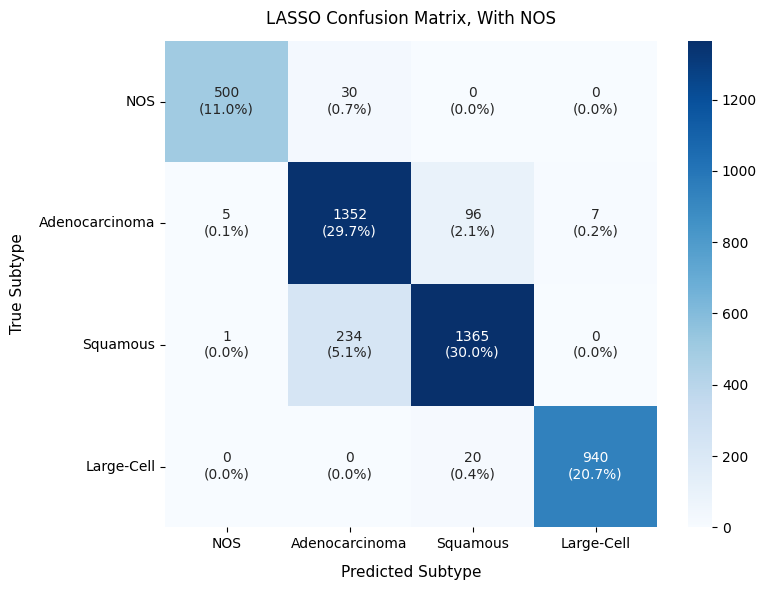

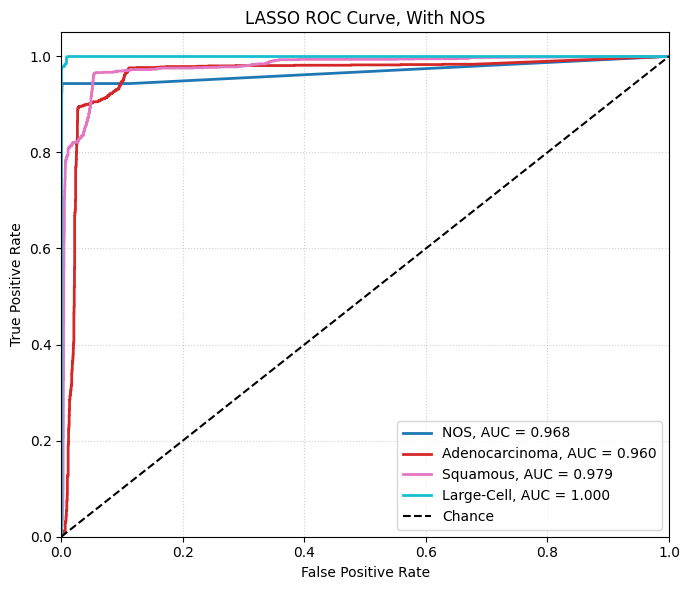

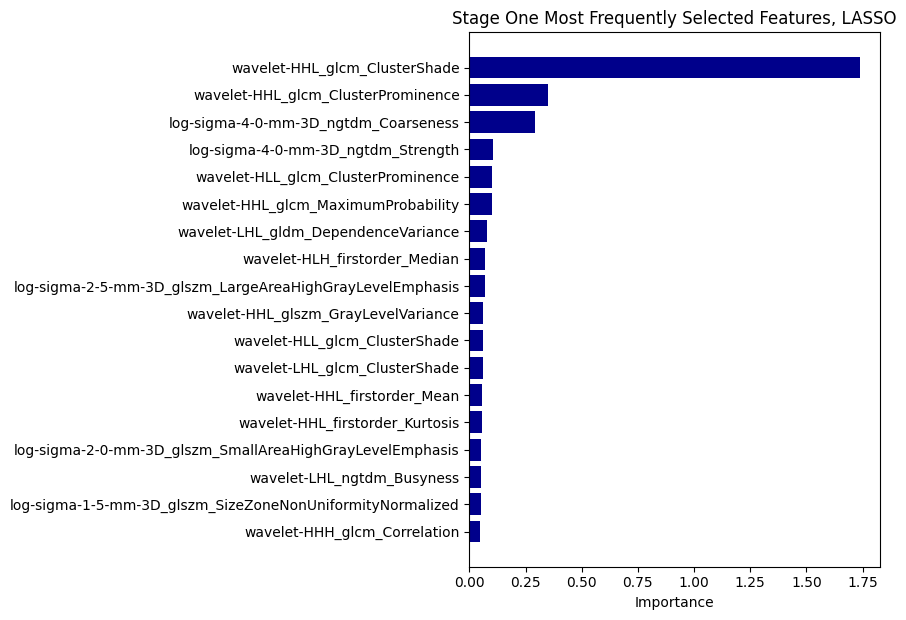

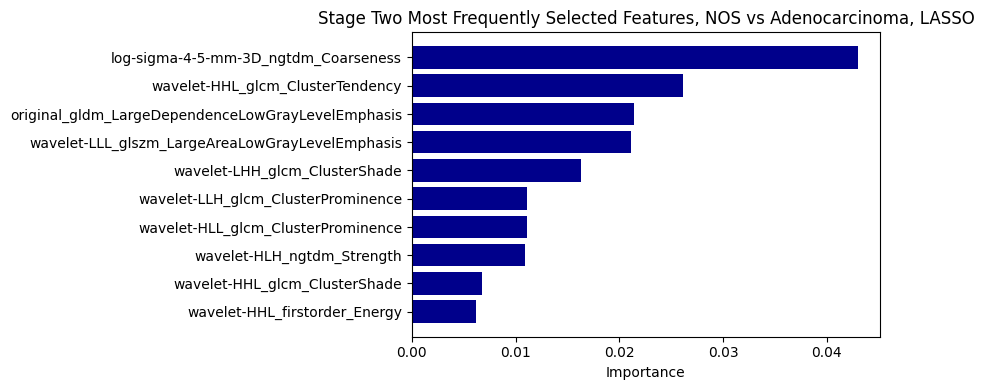

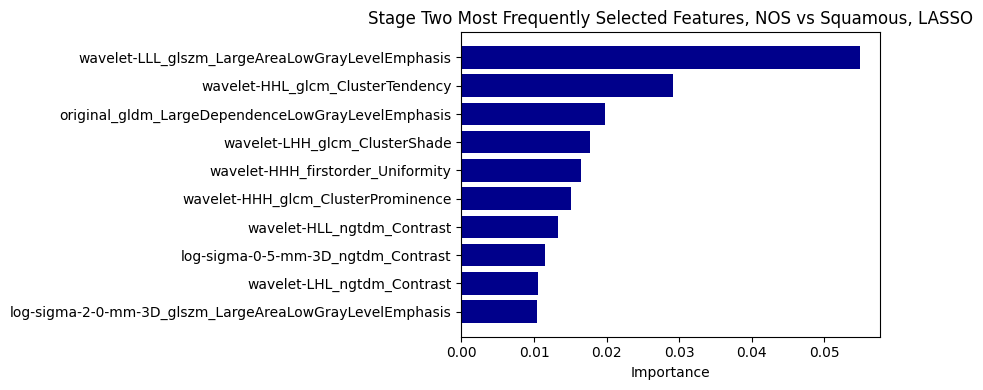

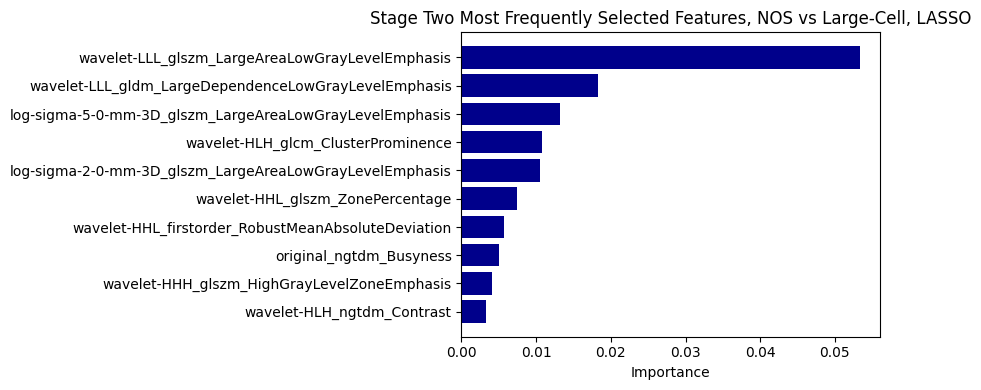

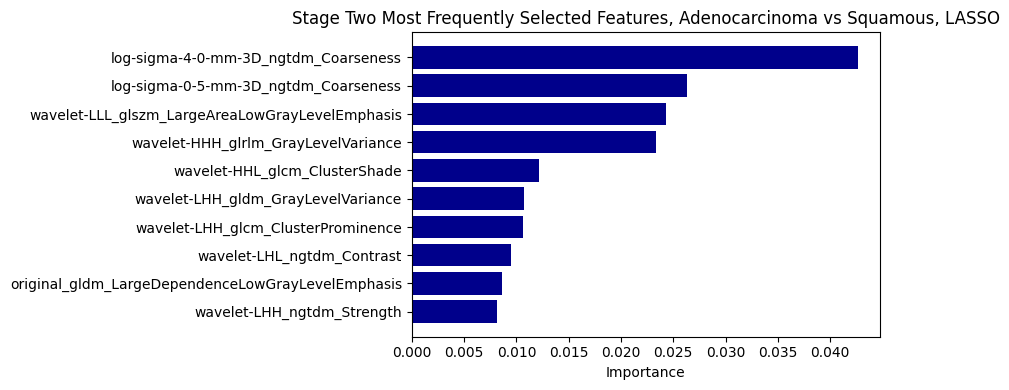

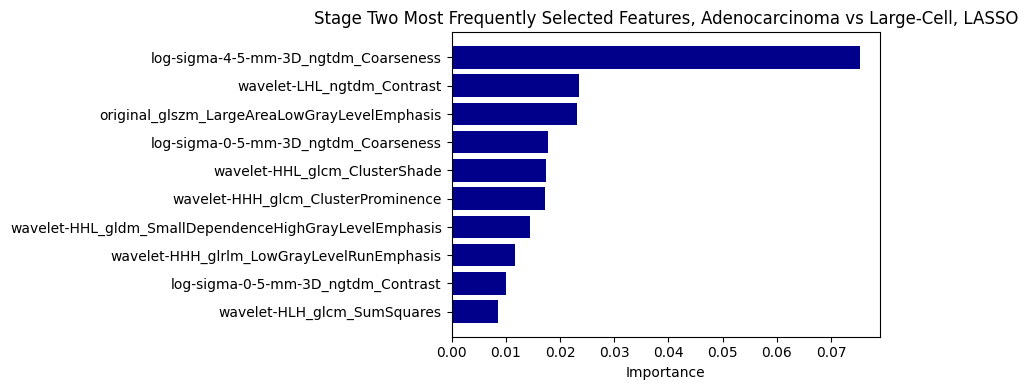

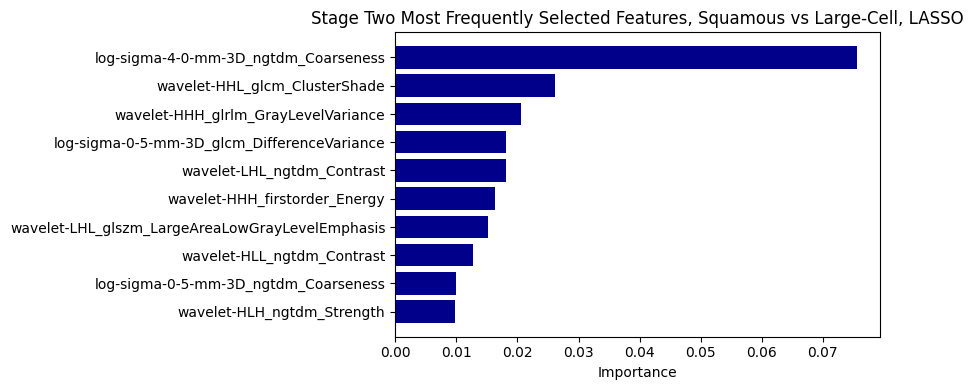

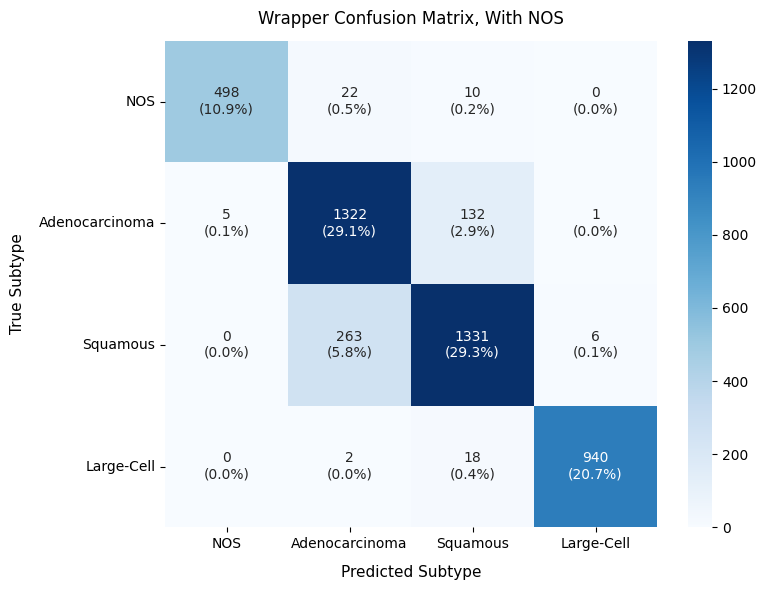

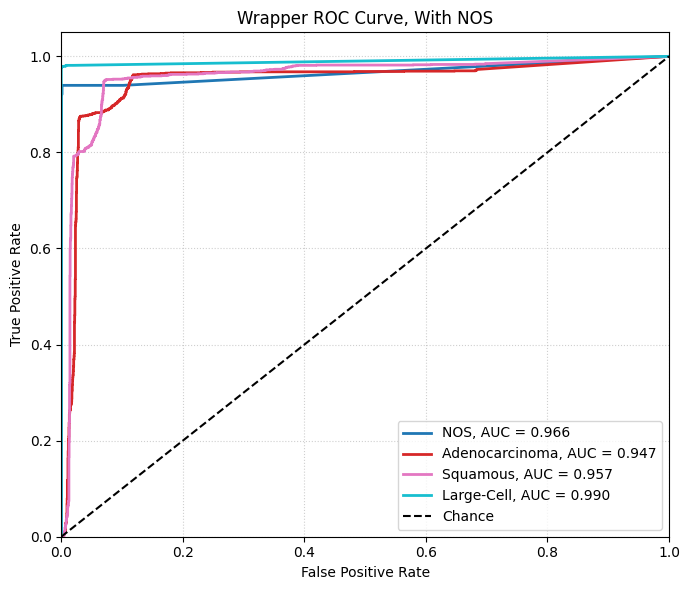

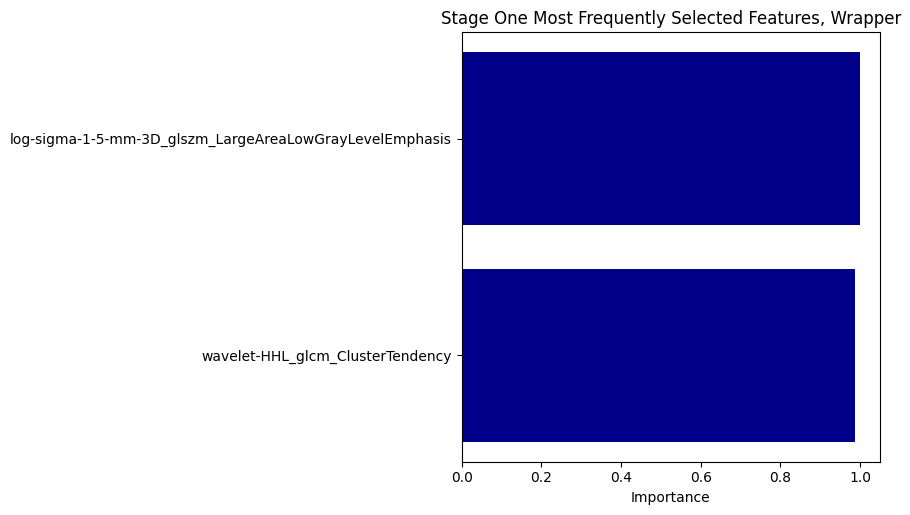

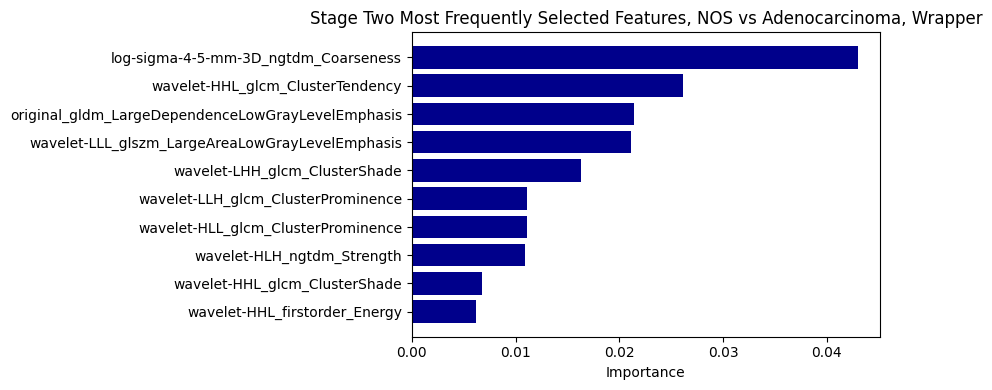

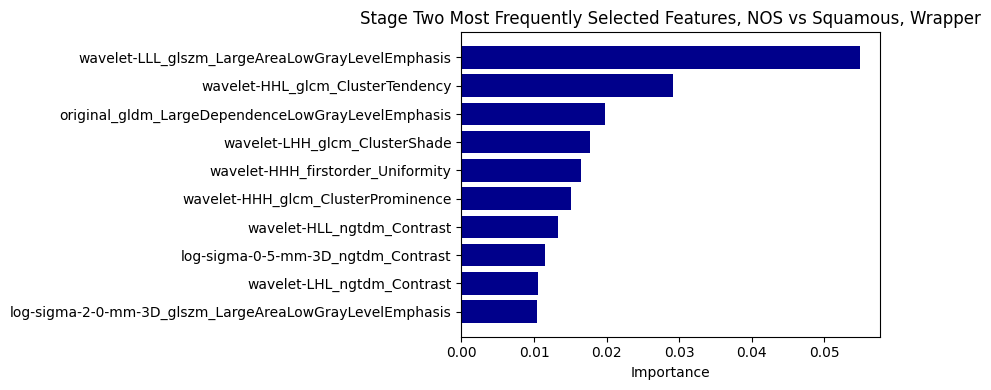

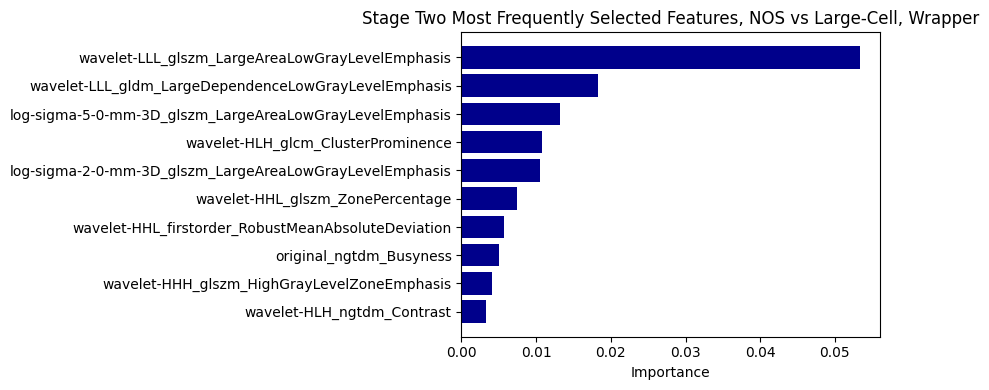

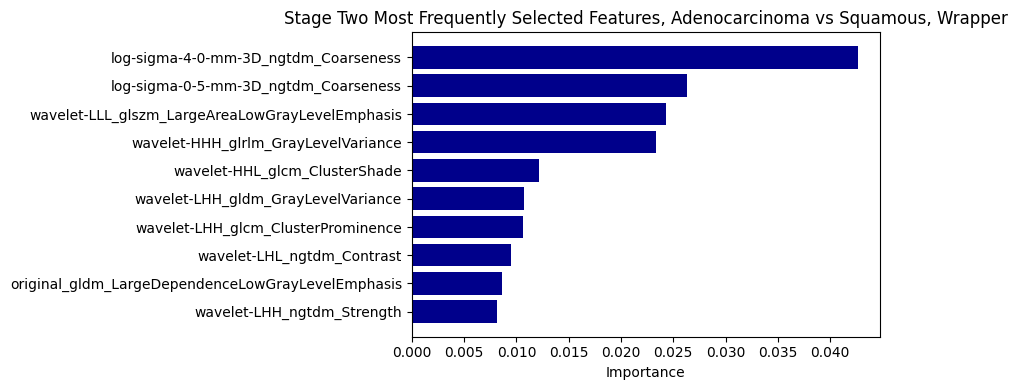

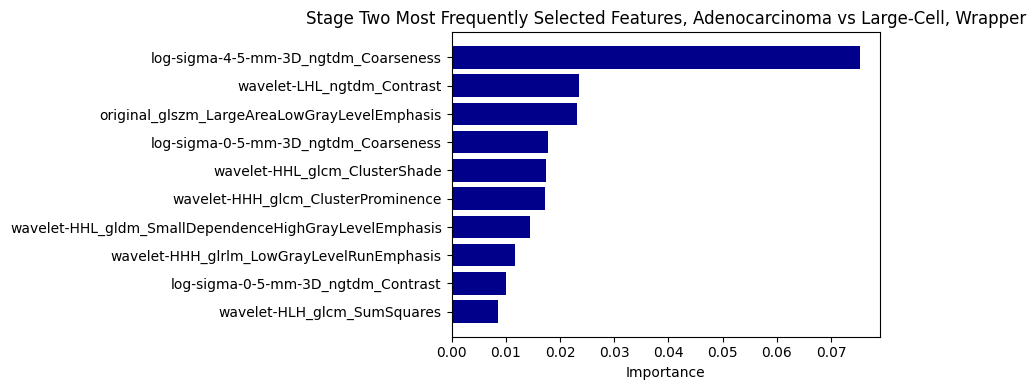

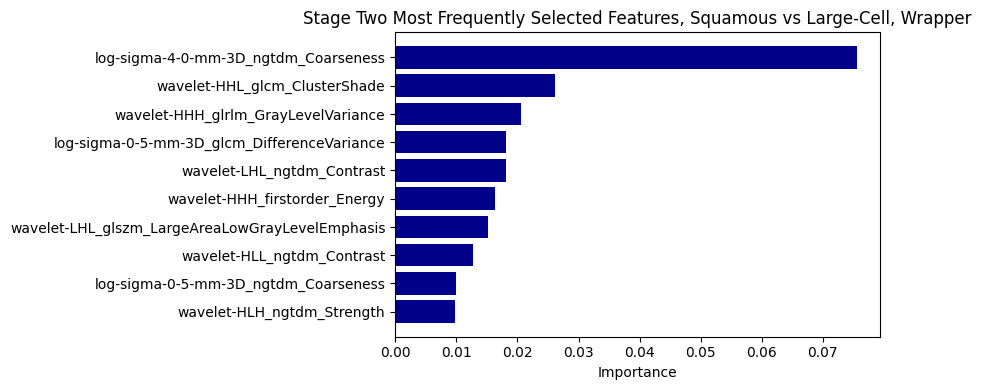

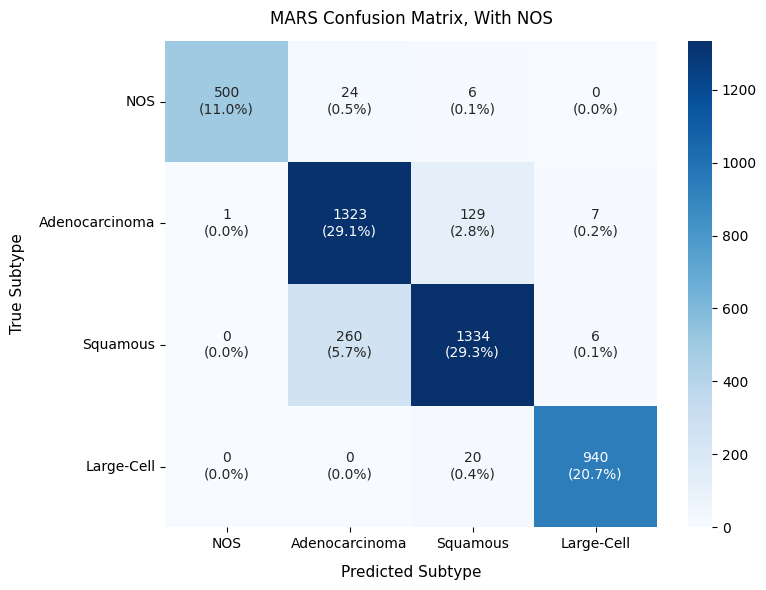

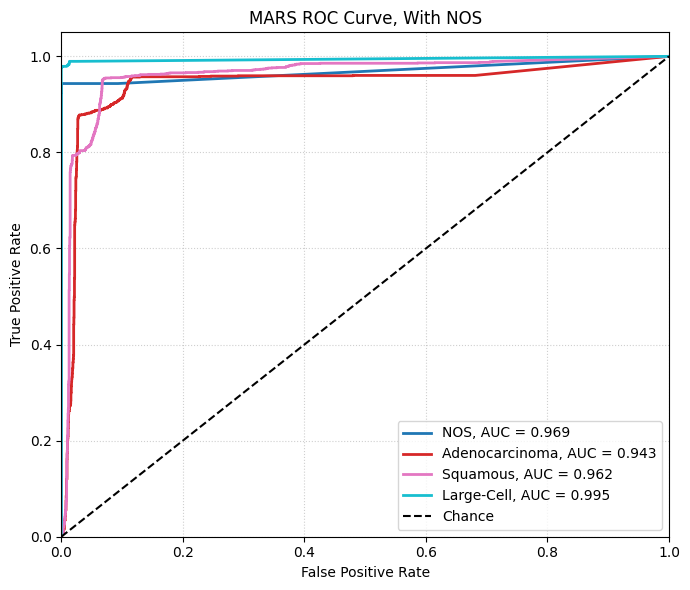

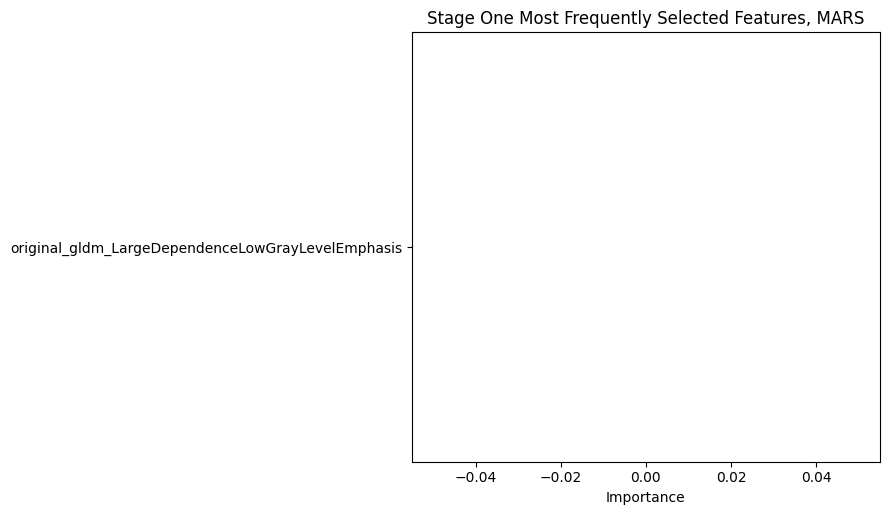

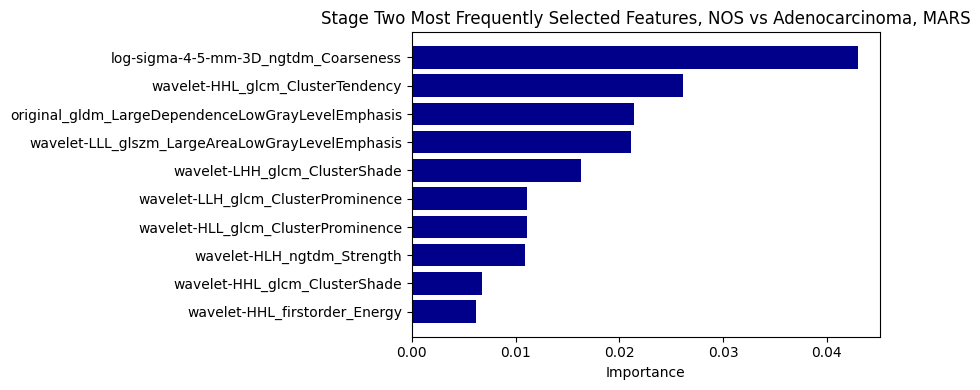

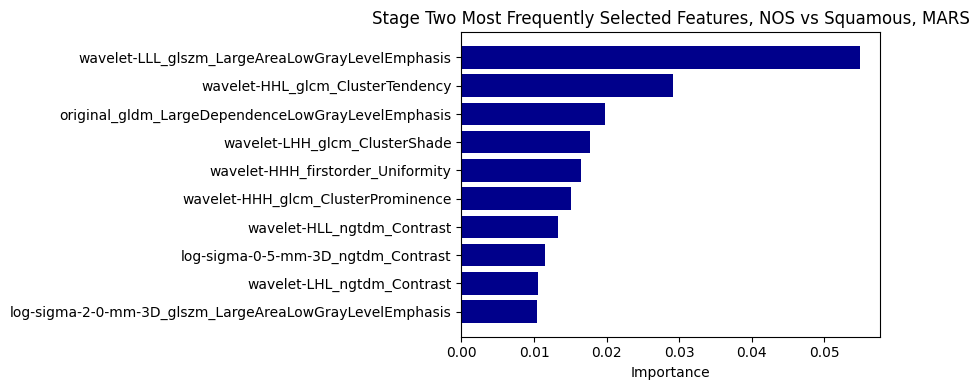

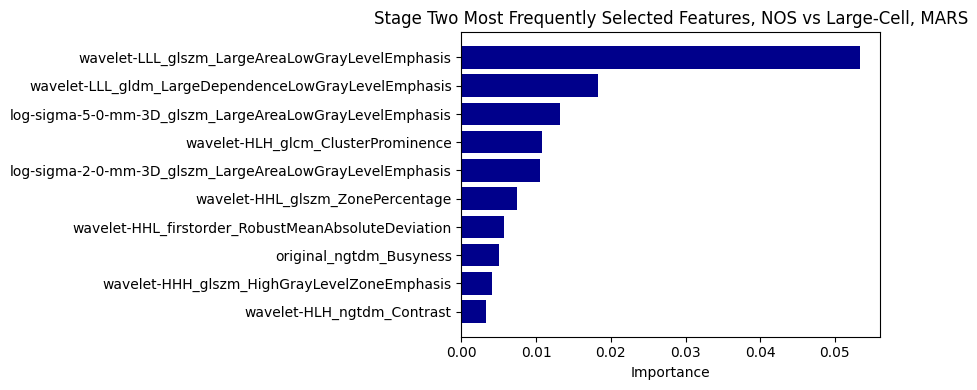

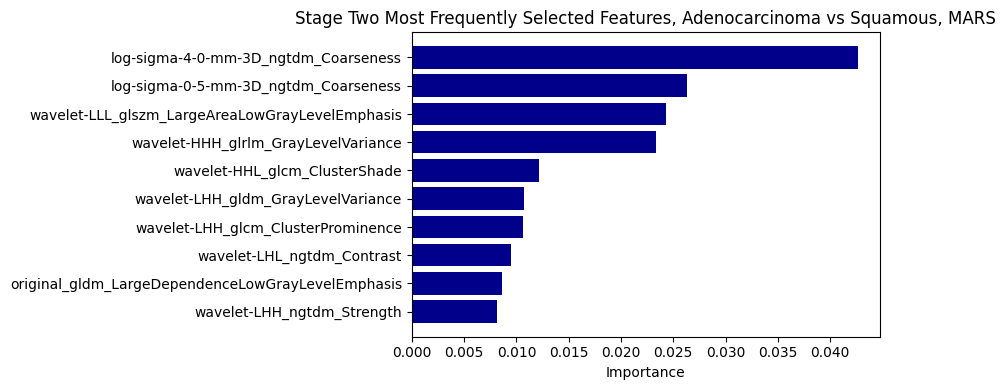

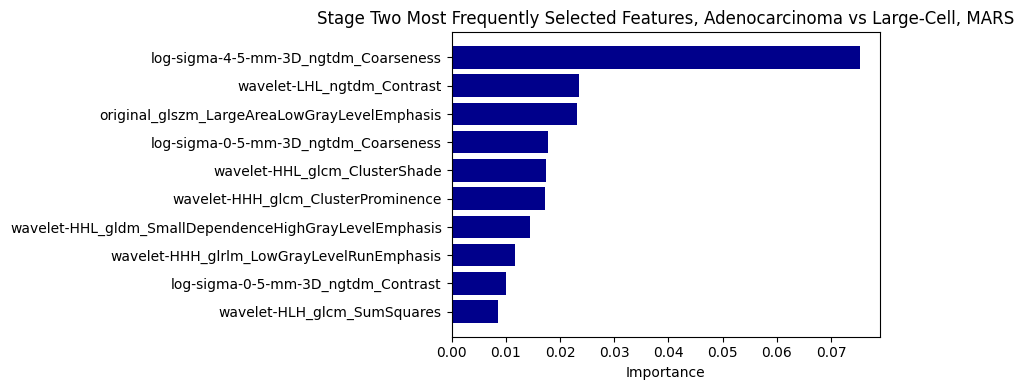

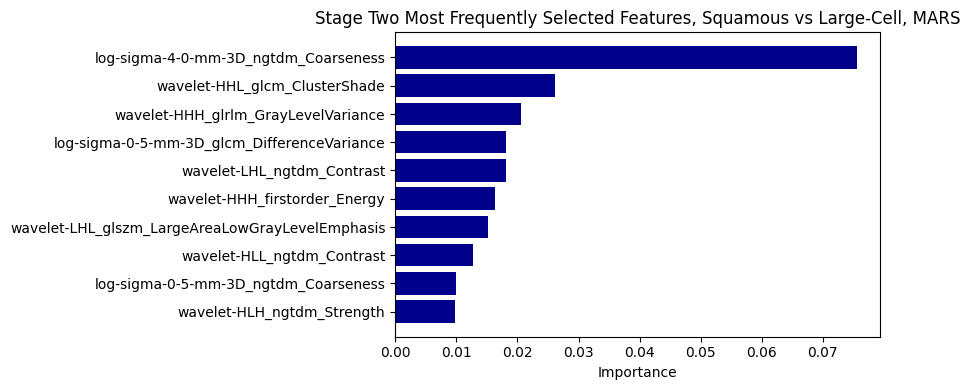

In [115]:
# Confusion matrix, roc curve, and feature importance for every method in the with-NOS pipeline
classes_4class = sorted(Y.unique())

for method, results in final_results_by_method_with_nos.items():
    y_true, y_pred, y_prob = results["y_true"], results["y_pred"], results["y_prob"]
    display_name = method_display_names[method]

    plot_confusion_matrix(y_true, y_pred, classes_4class, label_map, title=f"{display_name} Confusion Matrix, With NOS")
    plot_roc_curves(y_true, y_prob, classes_4class, label_map, title=f"{display_name} ROC Curve, With NOS")
    plot_all_feature_importance(results["stage1_freq_df"], results["pair_freq_dfs"], method=display_name, label_map_local=label_map)

In [116]:
# Diagnostic only, placed here rather than earlier because it depends on lasso_true, lasso_pred, and
# lasso_prob from the run above it
# Applies the isolated pair's winning threshold only to samples where the Adeno versus Squamous pairwise
# classifier was the one that actually fired, reusing the pooled predictions instead of rerunning the
# full four class pipeline once per threshold
# Result: confirmed the isolated pair's threshold win only partially survived once routing was
# accounted for, only about 84 percent of true Adeno or Squamous samples ever reached this pairwise
# classifier at all

# Rebuilds predictions at a given threshold, but only for samples where this exact pair was active
def apply_pair_threshold(all_true, all_pred, all_prob, pos_class, neg_class, threshold):
    all_prob = np.array(all_prob)
    pos_prob = all_prob[:, pos_class]
    neg_prob = all_prob[:, neg_class]
    # Pair active means these two classes hold essentially all the probability mass after stage two
    pair_active = (pos_prob + neg_prob) > 0.999

    new_pred = np.array(all_pred).copy()
    new_pred[pair_active] = np.where(pos_prob[pair_active] >= threshold, pos_class, neg_class)
    return new_pred, pair_active

total_pair_true = int(np.isin(lasso_true, [1, 2]).sum())
print(f"True Adenocarcinoma or Squamous samples in the pooled CV predictions: {total_pair_true}")

# Recompute metrics at each threshold, counting how many samples were actually pair active
threshold_pipeline_rows = []
for thresh in [0.30, 0.35, 0.40, 0.45, 0.50]:
    new_pred, pair_active = apply_pair_threshold(lasso_true, lasso_pred, lasso_prob, pos_class=1, neg_class=2, threshold=thresh)

    y_true_bin = (np.array(lasso_true) == 1).astype(int)
    y_pred_bin = (new_pred == 1).astype(int)

    prec = precision_score(y_true_bin, y_pred_bin, zero_division=0)
    sens = recall_score(y_true_bin, y_pred_bin, zero_division=0)
    cm = confusion_matrix(y_true_bin, y_pred_bin)
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = f1_score(y_true_bin, y_pred_bin, zero_division=0)

    threshold_pipeline_rows.append({
        "Threshold": thresh, "Samples With Pair Active": int(pair_active.sum()),
        "Precision": prec, "Sensitivity": sens, "Specificity": spec, "F1-Score": f1
    })
    print(f"Threshold={thresh:.2f} (pair active for {int(pair_active.sum())} of {total_pair_true} true "
          f"Adeno/Squamous samples): Sensitivity={sens:.3f}  Specificity={spec:.3f}  F1={f1:.3f}")

threshold_pipeline_df = pd.DataFrame(threshold_pipeline_rows).set_index("Threshold")
display(threshold_pipeline_df)

True Adenocarcinoma or Squamous samples in the pooled CV predictions: 3060
Threshold=0.30 (pair active for 2567 of 3060 true Adeno/Squamous samples): Sensitivity=0.950  Specificity=0.899  F1=0.878
Threshold=0.35 (pair active for 2567 of 3060 true Adeno/Squamous samples): Sensitivity=0.942  Specificity=0.903  F1=0.877
Threshold=0.40 (pair active for 2567 of 3060 true Adeno/Squamous samples): Sensitivity=0.936  Specificity=0.905  F1=0.876
Threshold=0.45 (pair active for 2567 of 3060 true Adeno/Squamous samples): Sensitivity=0.931  Specificity=0.909  F1=0.877
Threshold=0.50 (pair active for 2567 of 3060 true Adeno/Squamous samples): Sensitivity=0.926  Specificity=0.915  F1=0.879


,Samples With Pair Active,Precision,Sensitivity,Specificity,F1-Score
Threshold,,,,,
0.30,2567,0.815882,0.950000,0.898706,0.877848
0.35,2567,0.820513,0.942466,0.902589,0.877271
0.40,2567,0.822998,0.936301,0.904854,0.876001
0.45,2567,0.828659,0.930822,0.909061,0.876774
0.50,2567,0.836634,0.926027,0.914563,0.879064


In [117]:
# NOS removed pipeline, keeps the with-NOS pipeline above untouched for comparison
no_nos_mask = Y != 0
label_map_3class = {1: "Adenocarcinoma", 2: "Squamous", 3: "Large-Cell"}
classes_3class = [1, 2, 3]

In [118]:
# Final stage one configuration, chosen from the candidate comparison in the diagnostics section,
# dampened class weight and C=10 gave the strongest Adenocarcinoma and Squamous results without
# costing Large-Cell, widening the feature pool made results worse so the default pool size of 20 is
# kept. Run across all three feature selection methods, frequency tracking turned on so confusion
# matrix, roc curve, and feature importance can all be plotted from this single run
final_results_by_method = {}
for method in ["lasso", "wrapper", "mars"]:
    table, y_true, y_pred, y_prob, stage1_freq_df, pair_freq_dfs = evaluate_candidate_pipeline(
        X_scaled[no_nos_mask], Y[no_nos_mask], method=method, stage1_k=20,
        stage1_C=10.0, stage1_class_weight="dampened", label_map=label_map_3class, n_repeats=10,
        track_feature_frequency=True
    )
    final_results_by_method[method] = {
        "table": table, "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob,
        "stage1_freq_df": stage1_freq_df, "pair_freq_dfs": pair_freq_dfs
    }
    print(f"\n{method_display_names[method]} hierarchical model, NOS removed, optimized stage one")
    print(table.to_string())


LASSO hierarchical model, NOS removed, optimized stage one
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.852179     0.923973  0.886625     0.908594  0.914179  0.975328
Squamous         0.915493     0.853125  0.883209     0.947934  0.910199  0.969803
Large-Cell       0.993658     0.979167  0.986359     0.998039  0.993532  0.999814
Average          0.920443     0.918755  0.918731     0.951522  0.939303  0.981649

Wrapper hierarchical model, NOS removed, optimized stage one
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.835362     0.893151  0.863290     0.899609  0.897264  0.951704
Squamous         0.889628     0.836250  0.862113     0.931405  0.893532  0.955045
Large-Cell       0.984293     0.979167  0.981723     0.995098  0.991294  0.989827
Average          0.903094     0.902856  0.902376     0.942037  0.927363  0.965525

MARS hierarchical model, NOS removed, optimized stage one

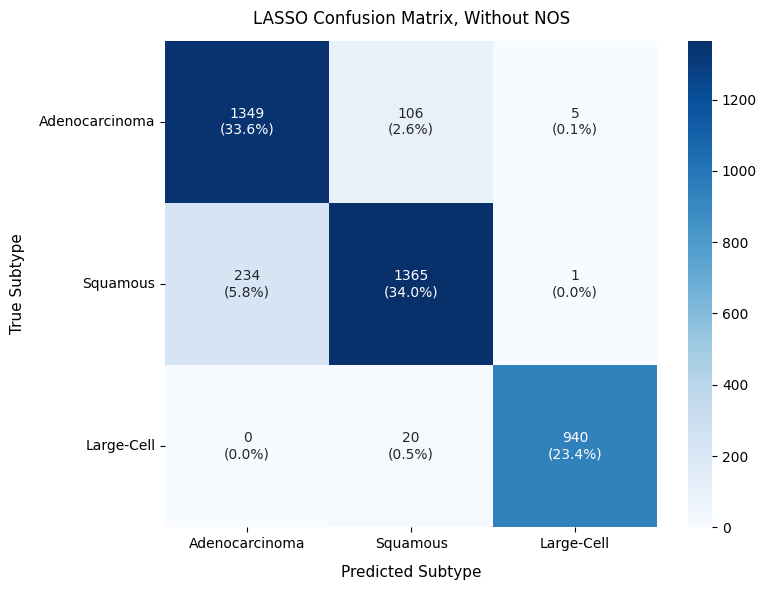

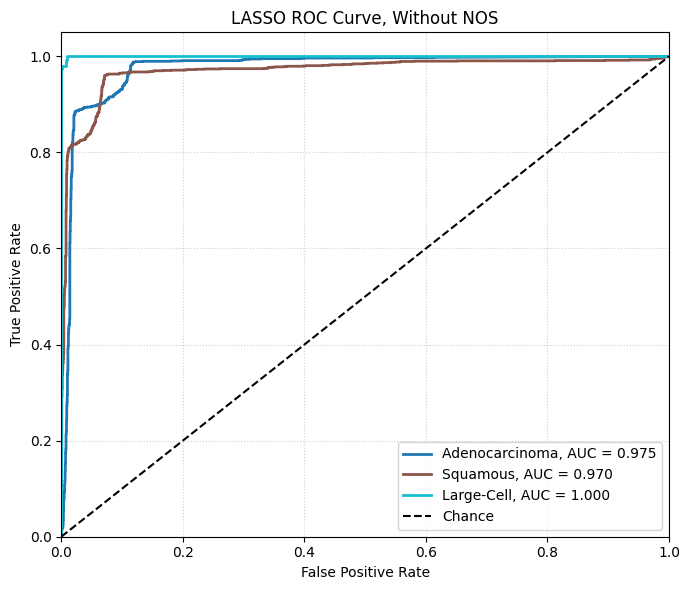

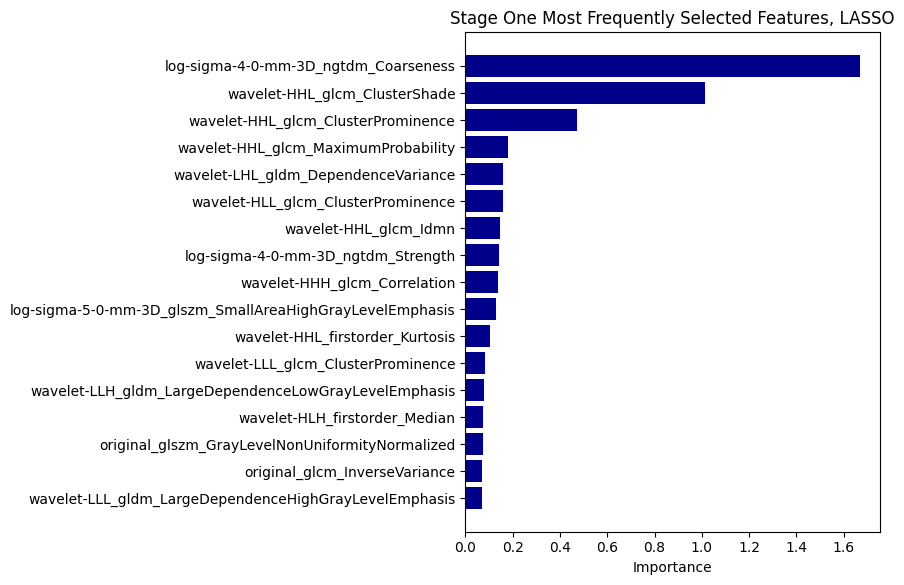

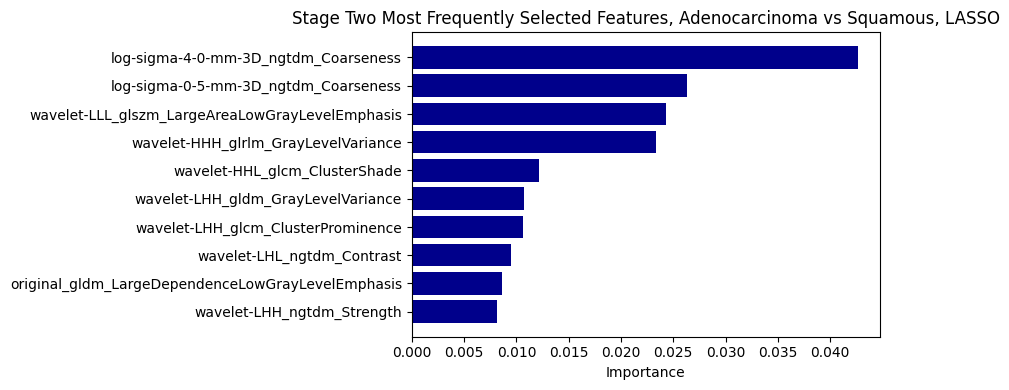

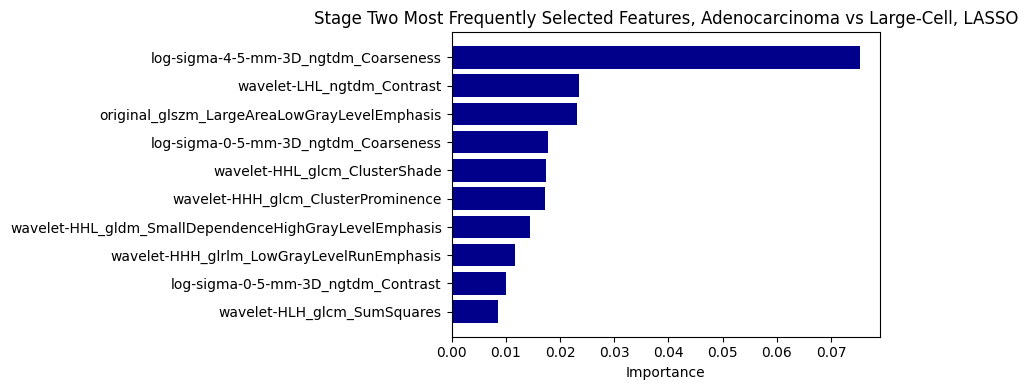

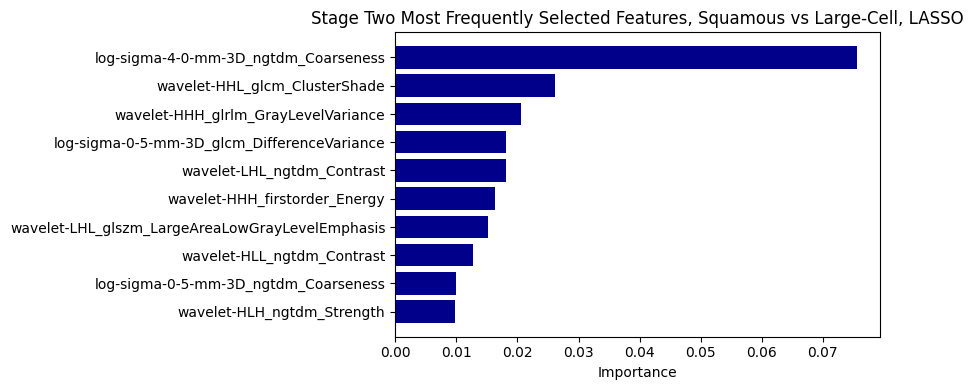

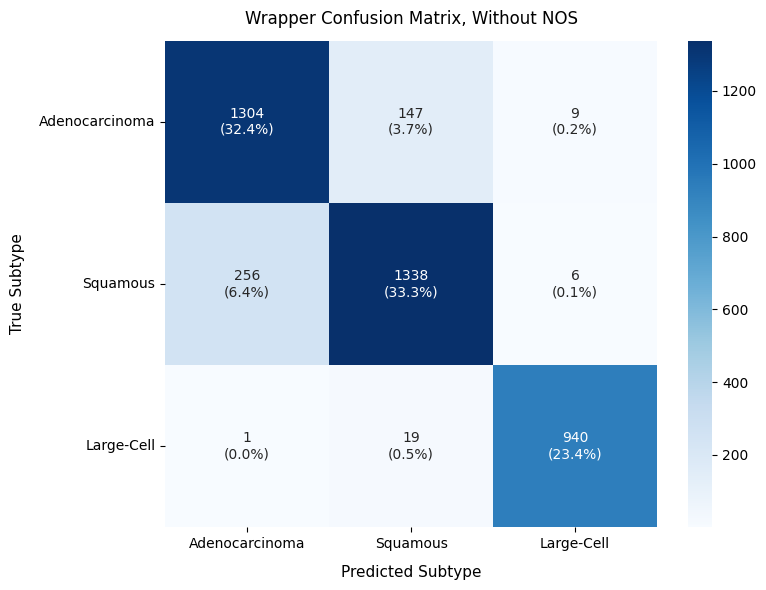

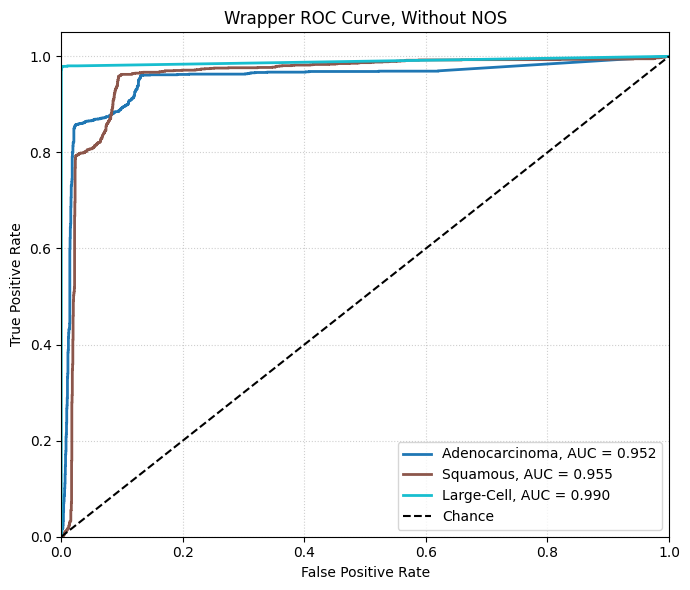

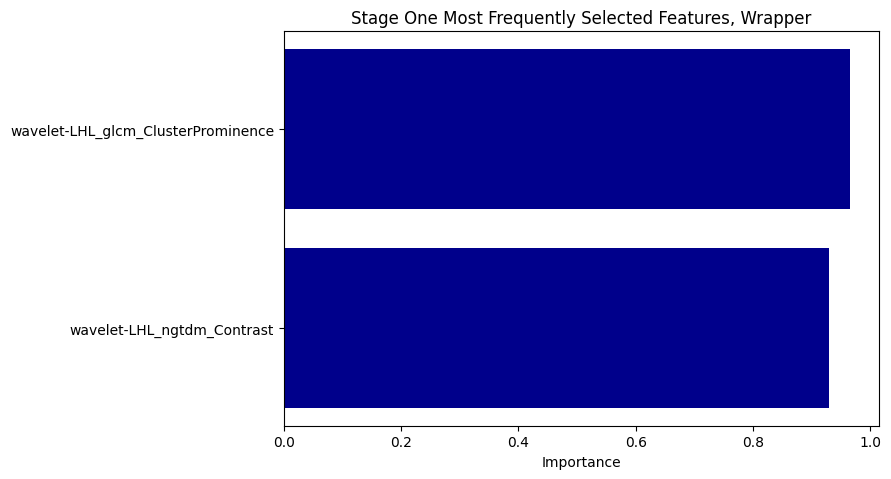

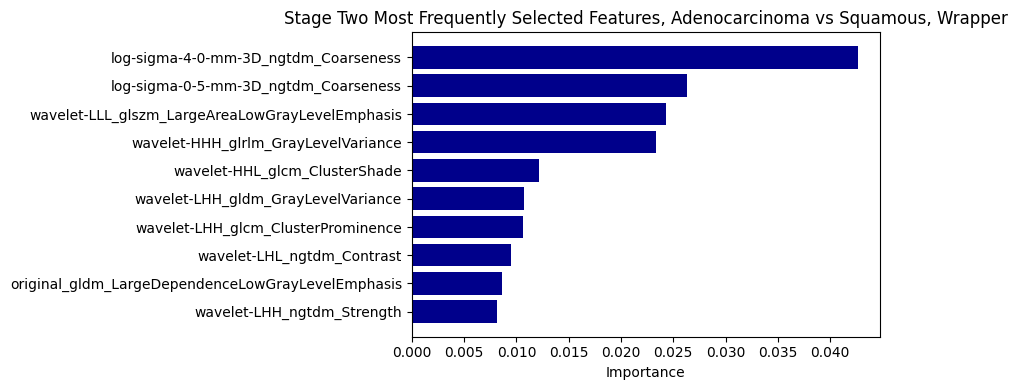

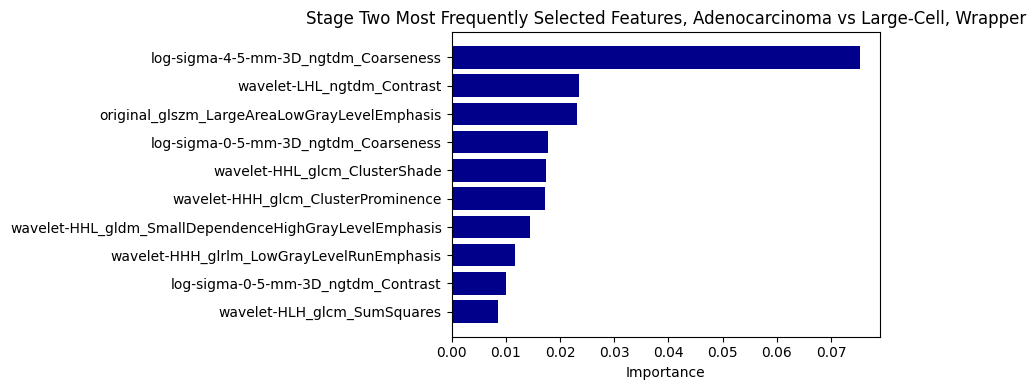

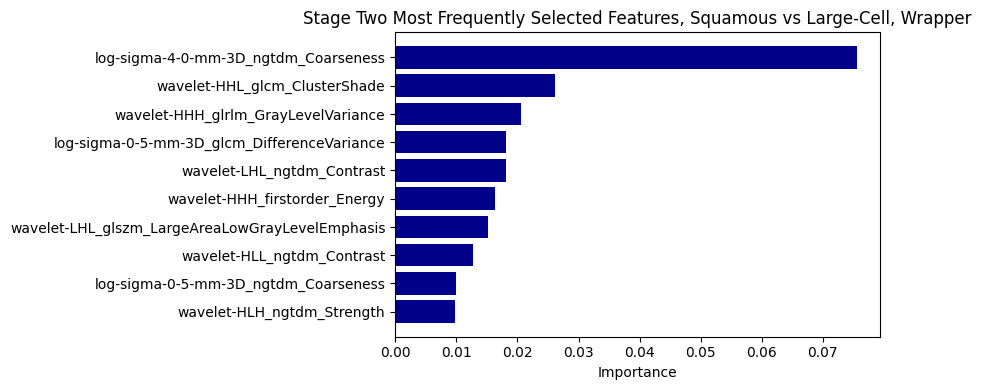

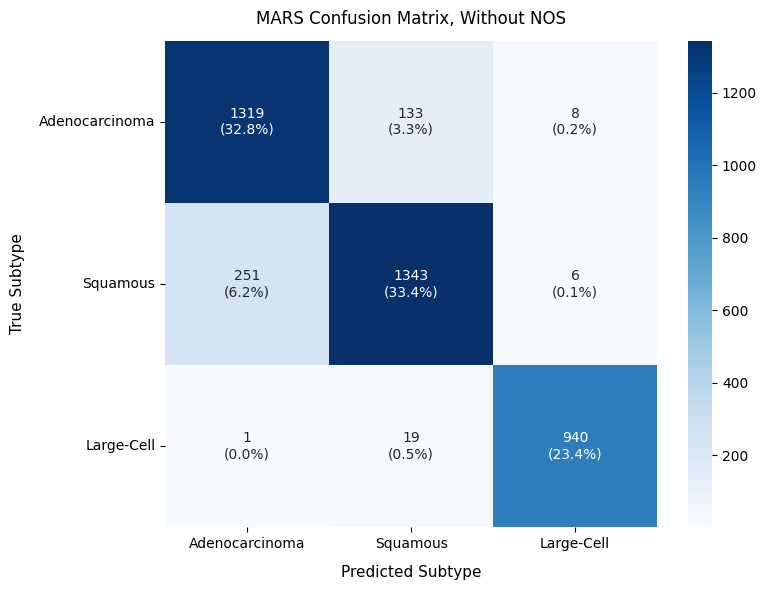

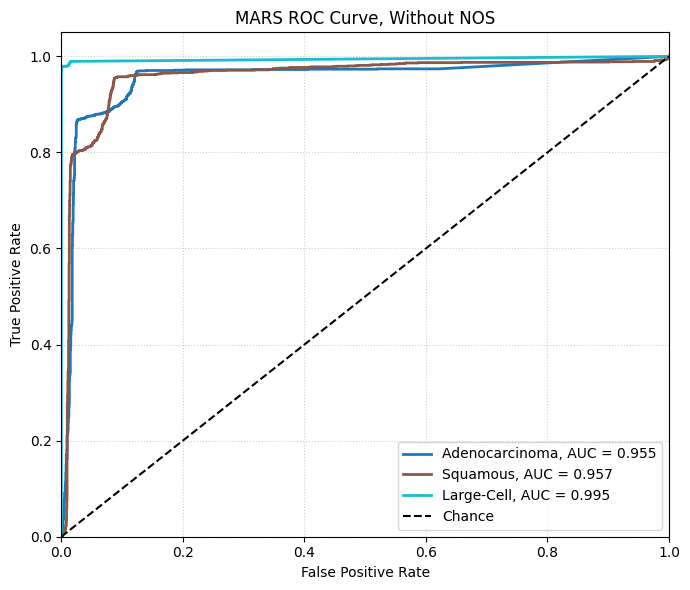

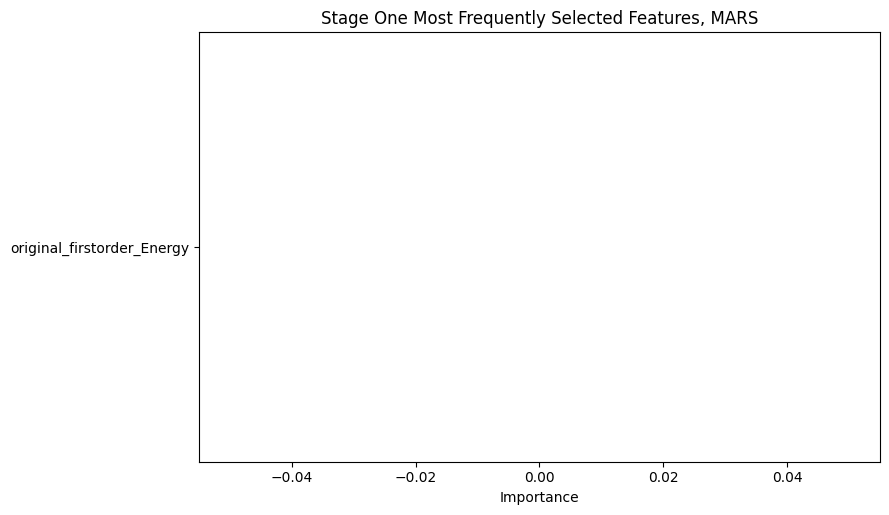

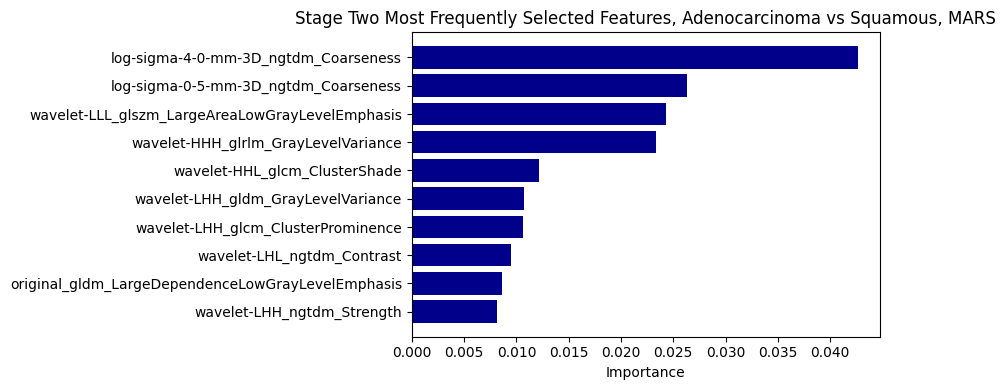

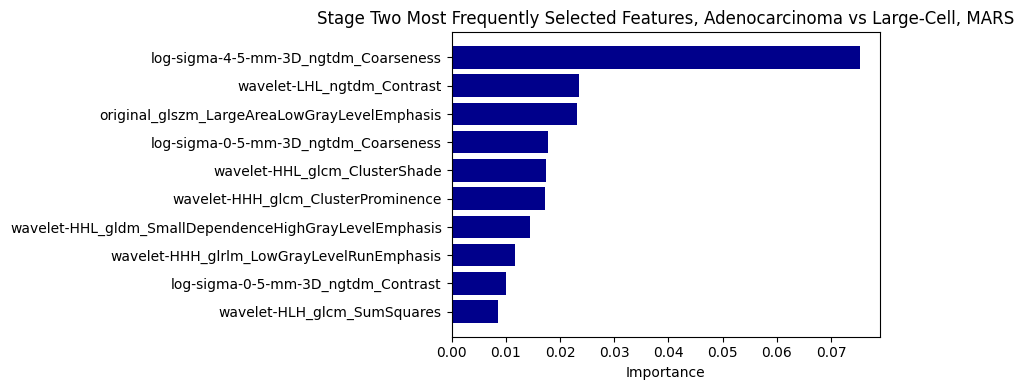

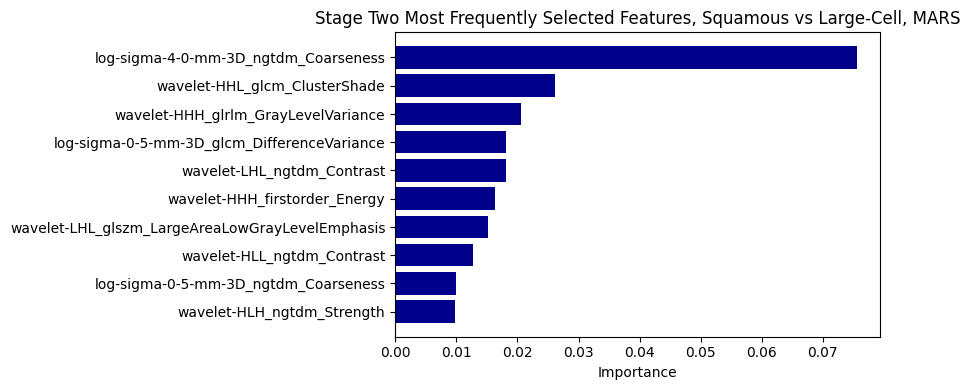

In [119]:
# Confusion matrix, roc curve, and feature importance for every method in the without-NOS pipeline
for method, results in final_results_by_method.items():
    y_true, y_pred, y_prob = results["y_true"], results["y_pred"], results["y_prob"]
    display_name = method_display_names[method]

    plot_confusion_matrix(y_true, y_pred, classes_3class, label_map_3class, title=f"{display_name} Confusion Matrix, Without NOS")
    plot_roc_curves(y_true, y_prob, classes_3class, label_map_3class, title=f"{display_name} ROC Curve, Without NOS")
    plot_all_feature_importance(results["stage1_freq_df"], results["pair_freq_dfs"], method=display_name, label_map_local=label_map_3class)

In [120]:
# Applies the confidence threshold to a set of predicted probabilities, returns the predicted subtype
# when the top probability clears the threshold, otherwise flags the sample uncertain and returns every
# class ranked from most to least likely for a pathologist to review directly
def predict_with_confidence_threshold(y_prob, classes, label_map, threshold):
    predictions, confidences, ranked_lists = [], [], []
    for row in y_prob:
        # Sort this sample's classes from most to least likely
        order = np.argsort(row)[::-1]
        ranked = [(label_map[classes[i]], row[i]) for i in order]
        top_class, top_prob = ranked[0]
        # Only assign the top class if it clears the threshold, otherwise mark uncertain
        predictions.append(top_class if top_prob >= threshold else "Uncertain")
        confidences.append(top_prob)
        ranked_lists.append(ranked)
    return predictions, confidences, ranked_lists

In [121]:
# Chosen confidence threshold, coverage stays above 90 percent through 0.70 while confident case
# accuracy keeps climbing past the full coverage baseline, past this point coverage keeps falling
# for comparatively small further accuracy gains
CONFIDENCE_THRESHOLD = 0.70

# Apply the threshold to each method's pooled predictions and show metrics on the confident subset only
for method, results in final_results_by_method.items():
    y_true, y_pred, y_prob = results["y_true"], results["y_pred"], results["y_prob"]
    predictions, confidences, _ = predict_with_confidence_threshold(y_prob, classes_3class, label_map_3class, CONFIDENCE_THRESHOLD)

    confident_mask = np.array(confidences) >= CONFIDENCE_THRESHOLD
    coverage = confident_mask.mean()

    confident_table = build_custom_metrics_table(
        y_true[confident_mask], y_pred[confident_mask], y_prob[confident_mask], classes_3class, label_map_3class
    )
    print(f"\n{method_display_names[method]}, confidence threshold {CONFIDENCE_THRESHOLD}, "
          f"coverage={coverage:.3f}, share flagged uncertain={1 - coverage:.3f}")
    print(confident_table.to_string())


LASSO, confidence threshold 0.7, coverage=0.919, share flagged uncertain=0.081
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.947368     0.962138  0.954696     0.969309  0.966694  0.982203
Squamous         0.950760     0.947330  0.949042     0.970524  0.961820  0.978023
Large-Cell       0.995763     0.979167  0.987395     0.998536  0.993501  0.999907
Average          0.964630     0.962878  0.963711     0.979457  0.974005  0.986711

Wrapper, confidence threshold 0.7, coverage=0.910, share flagged uncertain=0.090
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.944319     0.933780  0.939020     0.968035  0.955452  0.963440
Squamous         0.927746     0.941349  0.934498     0.956427  0.950806  0.962411
Large-Cell       0.993658     0.988433  0.991038     0.997784  0.995354  0.994591
Average          0.955241     0.954521  0.954852     0.974082  0.967204  0.973481

MARS, confidence 

In [122]:
# Testing cell, not a validated production result. Trains one final pipeline per method on the complete
# three class training set, then runs every NOS patient through it
# On the threshold mechanism itself: the mechanism is sound, the coverage versus accuracy tradeoff
# above behaves exactly as expected on genuine three class held out data. What's iffy is this specific
# application. Nearly every NOS patient here (50 of 53) comes from the same single cohort implicated in the unresolved
# site leakage problem investigated in the diagnostics section, so the near unanimous, near 0.999
# confidence Adenocarcinoma calls below likely reflect that leftover site signature at least in part,
# not purely genuine histology. Treat this cell as exploratory, not as evidence the model has resolved
# these cases
nos_mask = Y == 0
X_nos = X_scaled[nos_mask]
patient_ids_nos = features_df.loc[nos_mask, "patient_id"].values

nos_results_by_method = {}
for method in ["lasso", "wrapper", "mars"]:
    # Train fresh on the full three class dataset, no train test split needed since NOS is held out
    stage1_feats, pair_feats, _, _ = extract_all_pipeline_features(X_scaled[no_nos_mask], Y[no_nos_mask], method=method, stage1_k=20)
    # Same dampened weighting scheme used throughout the without-NOS pipeline
    counts = Y[no_nos_mask].value_counts()
    balanced_weights = len(Y[no_nos_mask]) / (counts.shape[0] * counts)
    dampened_weights = np.sqrt(balanced_weights).to_dict()

    base_estimator = LogisticRegression(max_iter=5000, C=10.0, class_weight=dampened_weights, random_state=42)
    final_clf = SymmetricHierarchicalClassifier(base_estimator=base_estimator, stage1_features=stage1_feats, pair_features=pair_feats)
    final_clf.fit(X_scaled[no_nos_mask], Y[no_nos_mask])

    # Run every NOS patient through the trained model and apply the confidence threshold
    nos_prob = final_clf.predict_proba(X_nos)
    predictions, confidences, ranked_lists = predict_with_confidence_threshold(nos_prob, classes_3class, label_map_3class, CONFIDENCE_THRESHOLD)

    nos_report = pd.DataFrame({
        "Patient ID": patient_ids_nos, "Prediction": predictions, "Confidence": confidences, "Ranked Probabilities": ranked_lists
    })
    nos_results_by_method[method] = nos_report

    print(f"\n{method_display_names[method]}, NOS patients run through the three class pipeline")
    print(nos_report["Prediction"].value_counts())
    display(nos_report)


LASSO, NOS patients run through the three class pipeline
Prediction
Adenocarcinoma    53
Name: count, dtype: int64


,Patient ID,Prediction,Confidence,Ranked Probabilities
0,LUNG1-013,Adenocarcinoma,0.999512,"[(Adenocarcinoma, 0.999512271932348), (Squamous, 0.0004877280676520496), (Large-Cell, 0.0)]"
1,LUNG1-016,Adenocarcinoma,0.999466,"[(Adenocarcinoma, 0.99946578157833), (Squamous, 0.0005342184216700648), (Large-Cell, 0.0)]"
2,LUNG1-019,Adenocarcinoma,0.999490,"[(Adenocarcinoma, 0.999489626485845), (Squamous, 0.0005103735141548621), (Large-Cell, 0.0)]"
3,LUNG1-051,Adenocarcinoma,0.999472,"[(Adenocarcinoma, 0.9994715149158987), (Squamous, 0.0005284850841012647), (Large-Cell, 0.0)]"
4,LUNG1-057,Adenocarcinoma,0.999426,"[(Adenocarcinoma, 0.9994261727959347), (Squamous, 0.0005738272040653425), (Large-Cell, 0.0)]"
5,LUNG1-059,Adenocarcinoma,0.999508,"[(Adenocarcinoma, 0.9995081975302473), (Squamous, 0.0004918024697525883), (Large-Cell, 0.0)]"
6,LUNG1-062,Adenocarcinoma,0.999408,"[(Adenocarcinoma, 0.9994081616863131), (Squamous, 0.0005918383136869378), (Large-Cell, 0.0)]"
7,LUNG1-065,Adenocarcinoma,0.999473,"[(Adenocarcinoma, 0.9994729880981367), (Squamous, 0.0005270119018632877), (Large-Cell, 0.0)]"
8,LUNG1-069,Adenocarcinoma,0.999463,"[(Adenocarcinoma, 0.9994629731834337), (Squamous, 0.0005370268165663444), (Large-Cell, 0.0)]"
9,LUNG1-070,Adenocarcinoma,0.999483,"[(Adenocarcinoma, 0.9994827819520491), (Squamous, 0.0005172180479509493), (Large-Cell, 0.0)]"



Wrapper, NOS patients run through the three class pipeline
Prediction
Adenocarcinoma    52
Squamous           1
Name: count, dtype: int64


,Patient ID,Prediction,Confidence,Ranked Probabilities
0,LUNG1-013,Adenocarcinoma,0.999512,"[(Adenocarcinoma, 0.999512271932348), (Squamous, 0.0004877280676520496), (Large-Cell, 0.0)]"
1,LUNG1-016,Adenocarcinoma,0.999466,"[(Adenocarcinoma, 0.99946578157833), (Squamous, 0.0005342184216700648), (Large-Cell, 0.0)]"
2,LUNG1-019,Adenocarcinoma,0.999490,"[(Adenocarcinoma, 0.999489626485845), (Squamous, 0.0005103735141548621), (Large-Cell, 0.0)]"
3,LUNG1-051,Adenocarcinoma,0.999472,"[(Adenocarcinoma, 0.9994715149158987), (Squamous, 0.0005284850841012647), (Large-Cell, 0.0)]"
4,LUNG1-057,Adenocarcinoma,0.999426,"[(Adenocarcinoma, 0.9994261727959347), (Squamous, 0.0005738272040653425), (Large-Cell, 0.0)]"
5,LUNG1-059,Adenocarcinoma,0.999508,"[(Adenocarcinoma, 0.9995081975302473), (Squamous, 0.0004918024697525883), (Large-Cell, 0.0)]"
6,LUNG1-062,Adenocarcinoma,0.999408,"[(Adenocarcinoma, 0.9994081616863131), (Squamous, 0.0005918383136869378), (Large-Cell, 0.0)]"
7,LUNG1-065,Adenocarcinoma,0.999473,"[(Adenocarcinoma, 0.9994729880981367), (Squamous, 0.0005270119018632877), (Large-Cell, 0.0)]"
8,LUNG1-069,Adenocarcinoma,0.999463,"[(Adenocarcinoma, 0.9994629731834337), (Squamous, 0.0005370268165663444), (Large-Cell, 0.0)]"
9,LUNG1-070,Adenocarcinoma,0.999483,"[(Adenocarcinoma, 0.9994827819520491), (Squamous, 0.0005172180479509493), (Large-Cell, 0.0)]"



MARS, NOS patients run through the three class pipeline
Prediction
Adenocarcinoma    52
Squamous           1
Name: count, dtype: int64


,Patient ID,Prediction,Confidence,Ranked Probabilities
0,LUNG1-013,Adenocarcinoma,0.999512,"[(Adenocarcinoma, 0.999512271932348), (Squamous, 0.0004877280676520496), (Large-Cell, 0.0)]"
1,LUNG1-016,Adenocarcinoma,0.999466,"[(Adenocarcinoma, 0.99946578157833), (Squamous, 0.0005342184216700648), (Large-Cell, 0.0)]"
2,LUNG1-019,Adenocarcinoma,0.999490,"[(Adenocarcinoma, 0.999489626485845), (Squamous, 0.0005103735141548621), (Large-Cell, 0.0)]"
3,LUNG1-051,Adenocarcinoma,0.999472,"[(Adenocarcinoma, 0.9994715149158987), (Squamous, 0.0005284850841012647), (Large-Cell, 0.0)]"
4,LUNG1-057,Adenocarcinoma,0.999426,"[(Adenocarcinoma, 0.9994261727959347), (Squamous, 0.0005738272040653425), (Large-Cell, 0.0)]"
5,LUNG1-059,Adenocarcinoma,0.999508,"[(Adenocarcinoma, 0.9995081975302473), (Squamous, 0.0004918024697525883), (Large-Cell, 0.0)]"
6,LUNG1-062,Adenocarcinoma,0.999408,"[(Adenocarcinoma, 0.9994081616863131), (Squamous, 0.0005918383136869378), (Large-Cell, 0.0)]"
7,LUNG1-065,Adenocarcinoma,0.999473,"[(Adenocarcinoma, 0.9994729880981367), (Squamous, 0.0005270119018632877), (Large-Cell, 0.0)]"
8,LUNG1-069,Adenocarcinoma,0.999463,"[(Adenocarcinoma, 0.9994629731834337), (Squamous, 0.0005370268165663444), (Large-Cell, 0.0)]"
9,LUNG1-070,Adenocarcinoma,0.999483,"[(Adenocarcinoma, 0.9994827819520491), (Squamous, 0.0005172180479509493), (Large-Cell, 0.0)]"


In [123]:
# Trains the final without-NOS configuration on the complete training set using the features selected once
# on the full training set before cross validation, ranked by each method's own importance score, rather than
# re-running feature selection here, this locks the pipeline to the same feature set that was actually validated
FINAL_STAGE1_K = 20
FINAL_STAGE2_K = 10

label_map_3class_external = {1: "Adenocarcinoma", 2: "Squamous", 3: "Large-Cell"}
classes_3class = [1, 2, 3]

external_results_by_method = {}
for method in ["lasso", "wrapper", "mars"]:
    stage1_feats = final_results_by_method[method]["stage1_freq_df"].head(FINAL_STAGE1_K)["Feature"].tolist()
    pair_feats = {
        pair: freq_df.head(FINAL_STAGE2_K)["Feature"].tolist()
        for pair, freq_df in final_results_by_method[method]["pair_freq_dfs"].items()
    }

    print(f"{method_display_names[method]}, frozen feature counts, stage one: {len(stage1_feats)}")
    for pair, feats in pair_feats.items():
        pair_name = f"{label_map_3class[pair[0]]} vs {label_map_3class[pair[1]]}"
        print(f"  {pair_name}: {len(feats)}")

    counts = Y[no_nos_mask].value_counts()
    balanced_weights = len(Y[no_nos_mask]) / (counts.shape[0] * counts)
    dampened_weights = np.sqrt(balanced_weights).to_dict()

    base_estimator = LogisticRegression(max_iter=5000, C=10.0, class_weight=dampened_weights, random_state=42)
    final_clf = SymmetricHierarchicalClassifier(base_estimator=base_estimator, stage1_features=stage1_feats, pair_features=pair_feats)
    final_clf.fit(X_scaled[no_nos_mask], Y[no_nos_mask])

    y_pred_external = final_clf.predict(X_external_scaled)
    y_prob_external = final_clf.predict_proba(X_external_scaled)

    external_table = build_custom_metrics_table(Y_external.values, y_pred_external, y_prob_external, classes_3class, label_map_3class_external)
    external_results_by_method[method] = {"table": external_table, "y_pred": y_pred_external, "y_prob": y_prob_external}

    print(f"\n{method_display_names[method]}, external validation on luad, lusc, and dx")
    print(external_table.to_string())

LASSO, frozen feature counts, stage one: 17
  Adenocarcinoma vs Squamous: 10
  Adenocarcinoma vs Large-Cell: 10
  Squamous vs Large-Cell: 10

LASSO, external validation on luad, lusc, and dx
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.743590     0.816901  0.778523     0.333333  0.673267  0.422066
Squamous         0.434783     0.370370  0.400000     0.824324  0.702970  0.462963
Large-Cell       0.000000     0.000000  0.000000     1.000000  0.970297  0.474490
Average          0.392791     0.395757  0.392841     0.719219  0.782178  0.453173
Wrapper, frozen feature counts, stage one: 14
  Adenocarcinoma vs Squamous: 10
  Adenocarcinoma vs Large-Cell: 10
  Squamous vs Large-Cell: 10

Wrapper, external validation on luad, lusc, and dx
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.750000     0.802817  0.775510     0.366667  0.673267  0.438967
Squamous         0.440000     0.407407  

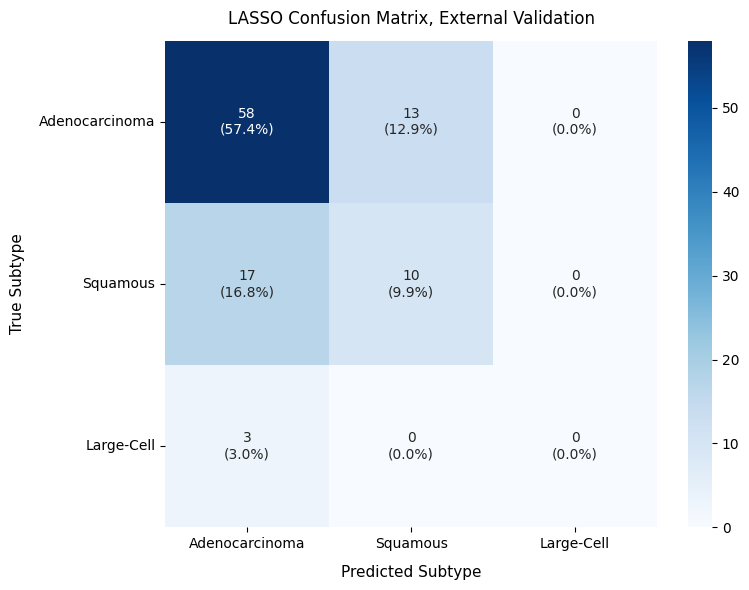

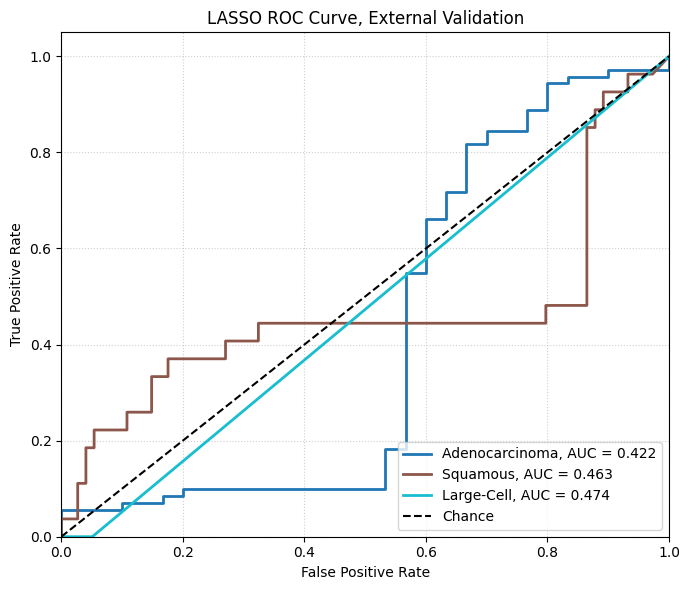

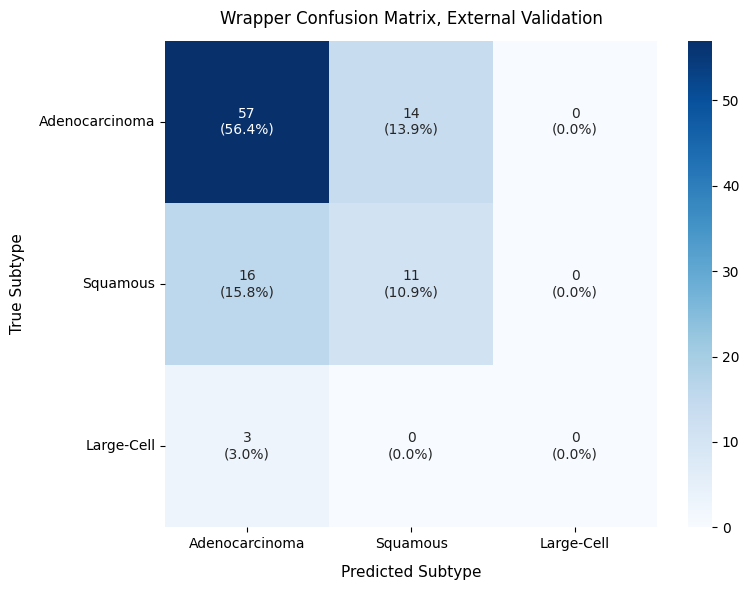

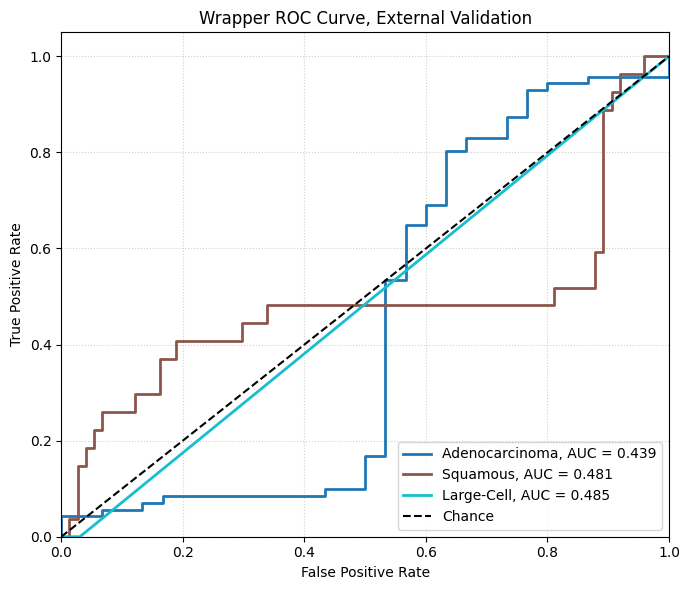

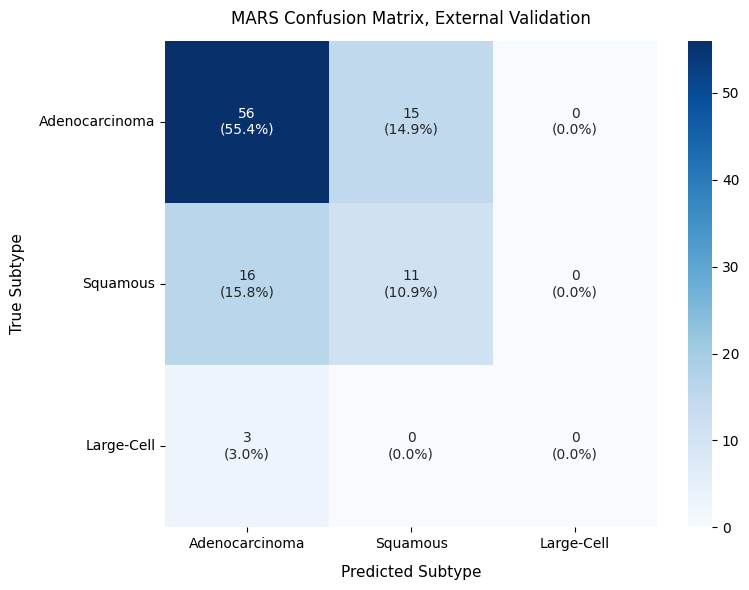

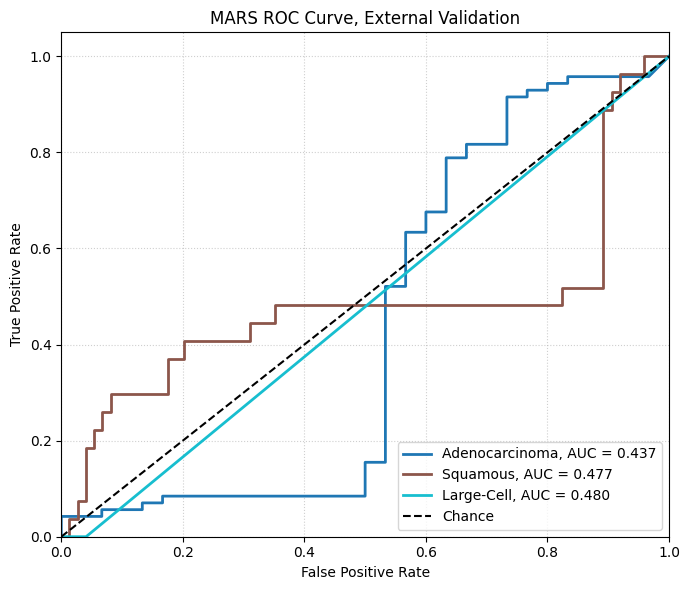

In [124]:
# Confusion matrix and roc curve for every method's external validation result
for method, results in external_results_by_method.items():
    display_name = method_display_names[method]
    plot_confusion_matrix(Y_external.values, results["y_pred"], classes_3class, label_map_3class_external, title=f"{display_name} Confusion Matrix, External Validation")
    plot_roc_curves(Y_external.values, results["y_prob"], classes_3class, label_map_3class_external, title=f"{display_name} ROC Curve, External Validation")

In [125]:
# Trains the final configuration on the training set using the top importance ranked features selected before cross-validation
FINAL_STAGE1_K = 20
FINAL_STAGE2_K = 10

label_map_2class_external = {1: "Adenocarcinoma", 2: "Squamous"}
classes_2class = [1, 2]

external_results_by_method = {}
for method in ["lasso", "wrapper", "mars"]:
    stage1_feats = (
        final_results_by_method[method]["stage1_freq_df"]
        .head(FINAL_STAGE1_K)["Feature"]
        .tolist()
    )
    pair_feats = {
        pair: freq_df.head(FINAL_STAGE2_K)["Feature"].tolist()
        for pair, freq_df in final_results_by_method[method][
            "pair_freq_dfs"
        ].items()
    }

    # Print feature counts excluding Large-Cell pairwise comparisons
    print(
        f"{method_display_names[method]}, stage one features: {len(stage1_feats)}"
    )
    for pair, feats in pair_feats.items():
        pair_name = f"{label_map_3class[pair[0]]} vs {label_map_3class[pair[1]]}"
        if "Large-Cell" not in pair_name:
            print(f"  {pair_name}: {len(feats)}")

    # Compute dampened class weights dictionary for Stage 1 estimator
    counts = Y[no_nos_mask].value_counts()
    balanced_weights = len(Y[no_nos_mask]) / (counts.shape[0] * counts)
    dampened_weights = np.sqrt(balanced_weights).to_dict()

    base_estimator = LogisticRegression(
        max_iter=5000,
        C=10.0,
        class_weight=dampened_weights,
        random_state=42,
    )
    final_clf = SymmetricHierarchicalClassifier(
        base_estimator=base_estimator,
        stage1_features=stage1_feats,
        pair_features=pair_feats,
    )
    final_clf.fit(X_scaled[no_nos_mask], Y[no_nos_mask])

    # Large-Cell samples drop out of the metrics below because the metrics table only counts classes 1 and 2
    no_large_cell_mask = Y_external != "Large-Cell"
    X_ext_eval = X_external_scaled[no_large_cell_mask]
    Y_ext_eval = Y_external[no_large_cell_mask]

    y_pred_external = final_clf.predict(X_ext_eval)
    y_prob_external = final_clf.predict_proba(X_ext_eval)

    # Slice y_prob to include only the 2 active classes (columns 0 and 1)
    y_prob_2class = y_prob_external[:, :2]

    # Pass 2-class inputs into build_custom_metrics_table
    external_table = build_custom_metrics_table(
        Y_ext_eval.values,
        y_pred_external,
        y_prob_2class,
        classes_2class,
        label_map_2class_external,
    )
    external_results_by_method[method] = {
        "table": external_table,
        "y_pred": y_pred_external,
        "y_prob": y_prob_2class,
    }

    print(f"\n{method_display_names[method]}, external validation on luad and lusc")
    print(external_table.to_string())
    print()

LASSO, stage one features: 17
  Adenocarcinoma vs Squamous: 10

LASSO, external validation on luad and lusc
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.773333     0.816901  0.794521     0.370370  0.693878  0.422066
Squamous         0.434783     0.370370  0.400000     0.816901  0.693878  0.462963
Average          0.604058     0.593636  0.597260     0.593636  0.693878  0.442514

Wrapper, stage one features: 14
  Adenocarcinoma vs Squamous: 10

Wrapper, external validation on luad and lusc
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.780822     0.802817  0.791667     0.407407  0.693878  0.438967
Squamous         0.440000     0.407407  0.423077     0.802817  0.693878  0.480981
Average          0.610411     0.605112  0.607372     0.605112  0.693878  0.459974

MARS, stage one features: 15
  Adenocarcinoma vs Squamous: 10

MARS, external validation on luad and lusc
                

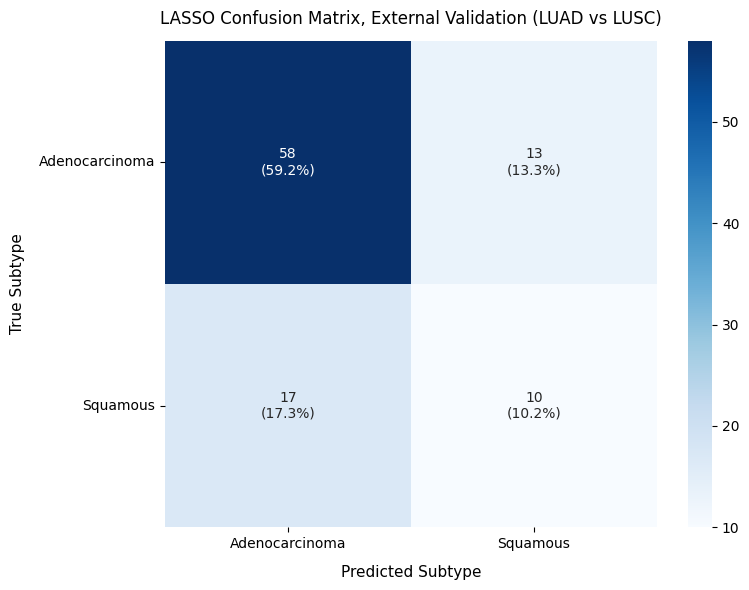

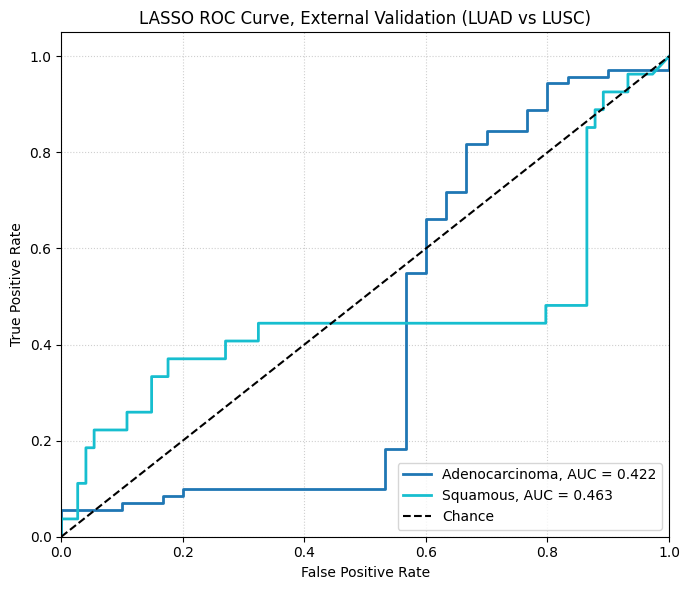

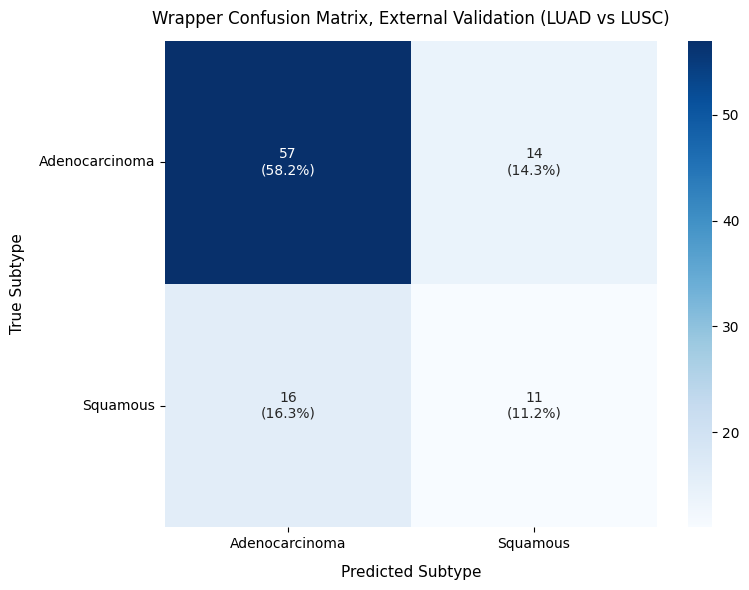

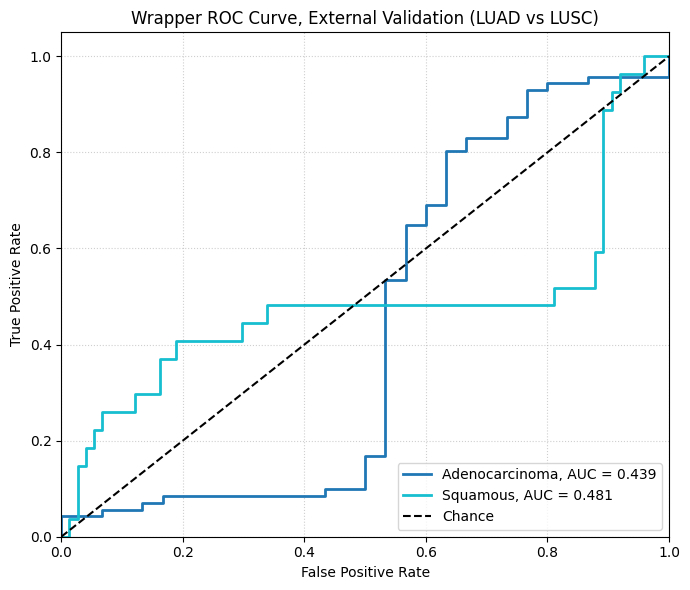

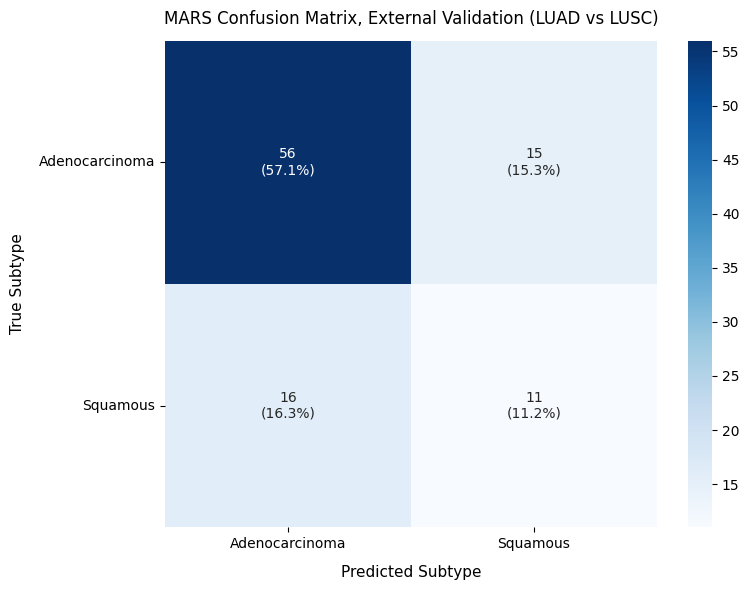

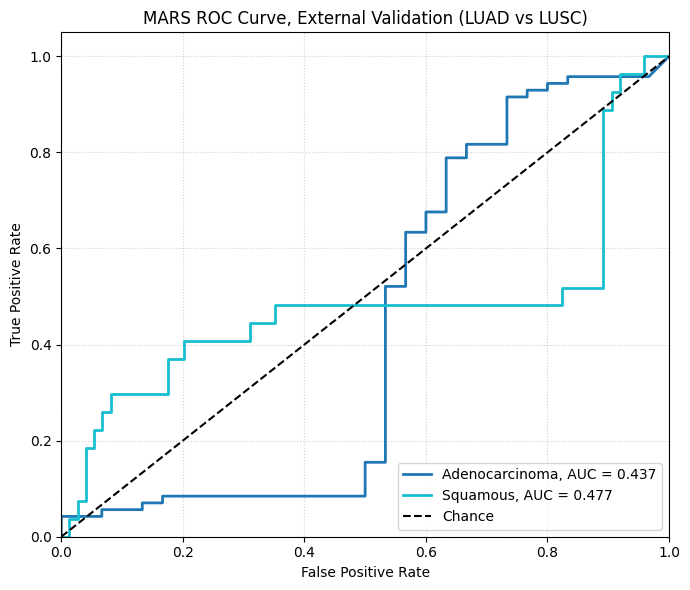

In [126]:
# Confusion matrix and ROC curve for external validation results (without Large-Cell)
for method, results in external_results_by_method.items():
    display_name = method_display_names[method]

    # Plot 2-class confusion matrix excluding Large-Cell
    plot_confusion_matrix(
        Y_ext_eval.values,
        results["y_pred"],
        classes_2class,
        label_map_2class_external,
        title=f"{display_name} Confusion Matrix, External Validation (LUAD vs LUSC)",
    )

    # Plot 2-class ROC curves excluding Large-Cell
    plot_roc_curves(
        Y_ext_eval.values,
        results["y_prob"],
        classes_2class,
        label_map_2class_external,
        title=f"{display_name} ROC Curve, External Validation (LUAD vs LUSC)",
    )

In [127]:
# Rebuilds and fits the final classifier for a given method using its frozen, highest importance
# ranked features, reused across the diagnostics below instead of repeating this setup each time
def fit_final_classifier(method):
    stage1_feats = final_results_by_method[method]["stage1_freq_df"].head(FINAL_STAGE1_K)["Feature"].tolist()
    pair_feats = {
        pair: freq_df.head(FINAL_STAGE2_K)["Feature"].tolist()
        for pair, freq_df in final_results_by_method[method]["pair_freq_dfs"].items()
    }

    counts = Y[no_nos_mask].value_counts()
    balanced_weights = len(Y[no_nos_mask]) / (counts.shape[0] * counts)
    dampened_weights = np.sqrt(balanced_weights).to_dict()

    base_estimator = LogisticRegression(max_iter=5000, C=10.0, class_weight=dampened_weights, random_state=42)
    clf = SymmetricHierarchicalClassifier(base_estimator=base_estimator, stage1_features=stage1_feats, pair_features=pair_feats)
    clf.fit(X_scaled[no_nos_mask], Y[no_nos_mask])
    return clf, stage1_feats, pair_feats

In [128]:
# Diagnostic one, overfitting check, compares in sample performance on the exact training data the
# model was fit on against the already known cross validated performance from earlier in the notebook,
# a large gap means the frozen features and model are memorizing training data rather than learning a
# pattern that generalizes, even before external data enters the picture
print("Overfitting check, in sample versus cross validated performance")
for method in ["lasso", "wrapper", "mars"]:
    clf, _, _ = fit_final_classifier(method)

    y_pred_in_sample = clf.predict(X_scaled[no_nos_mask])
    y_prob_in_sample = clf.predict_proba(X_scaled[no_nos_mask])
    in_sample_table = build_custom_metrics_table(Y[no_nos_mask].values, y_pred_in_sample, y_prob_in_sample, classes_3class, label_map_3class)

    cv_average_auc = final_results_by_method[method]["table"].loc["Average", "ROC-AUC"]
    in_sample_average_auc = in_sample_table.loc["Average", "ROC-AUC"]

    print(f"\n{method_display_names[method]}, cross validated average ROC-AUC: {cv_average_auc:.3f}, "
          f"in sample average ROC-AUC: {in_sample_average_auc:.3f}, gap: {in_sample_average_auc - cv_average_auc:.3f}")

Overfitting check, in sample versus cross validated performance

LASSO, cross validated average ROC-AUC: 0.982, in sample average ROC-AUC: 1.000, gap: 0.018

Wrapper, cross validated average ROC-AUC: 0.966, in sample average ROC-AUC: 0.992, gap: 0.026

MARS, cross validated average ROC-AUC: 0.969, in sample average ROC-AUC: 1.000, gap: 0.031


In [129]:
# Diagnostic two, feature distribution mismatch, checks whether the specific features each model
# actually relies on look wildly different between training and external data as currently processed,
# large shifts point toward features that do not transfer to new scanners and populations, whatever
# the underlying cause turns out to be
print("Feature distribution mismatch, frozen features only")
for method in ["lasso", "wrapper", "mars"]:
    _, stage1_feats, pair_feats = fit_final_classifier(method)
    all_frozen_feats = set(stage1_feats)
    for feats in pair_feats.values():
        all_frozen_feats.update(feats)
    all_frozen_feats = list(all_frozen_feats)

    train_means = X_scaled[no_nos_mask][all_frozen_feats].mean()
    train_stds = X_scaled[no_nos_mask][all_frozen_feats].std()
    external_means = X_external_scaled[all_frozen_feats].mean()

    z_shift = ((external_means - train_means) / train_stds).abs()
    print(f"\n{method_display_names[method]}, {len(all_frozen_feats)} frozen features total")
    print(f"Features shifted more than 2 standard deviations: {(z_shift > 2).sum()}")
    print(f"Features shifted more than 5 standard deviations: {(z_shift > 5).sum()}")
    print(f"Median absolute shift: {z_shift.median():.2f} standard deviations")

Feature distribution mismatch, frozen features only

LASSO, 37 frozen features total
Features shifted more than 2 standard deviations: 0
Features shifted more than 5 standard deviations: 0
Median absolute shift: 0.06 standard deviations

Wrapper, 33 frozen features total
Features shifted more than 2 standard deviations: 0
Features shifted more than 5 standard deviations: 0
Median absolute shift: 0.06 standard deviations

MARS, 34 frozen features total
Features shifted more than 2 standard deviations: 0
Features shifted more than 5 standard deviations: 0
Median absolute shift: 0.06 standard deviations


In [130]:
# Diagnostic three, harmonization mismatch, external features are currently harmonized together with the training data and
# standardized using the combined scale statistics, this compares that against a simple external only z score
# standardization, which at least matches each feature's own mean and spread within the external set, a meaningful
# improvement here would point directly at the harmonization as a major driver, this is a diagnostic stand in, not a validated
# replacement for proper harmonization
scaler_external_only = StandardScaler()
X_external_own_scaled = pd.DataFrame(
    scaler_external_only.fit_transform(X_external.values), columns=X_external.columns, index=X_external.index
)

print("Harmonization mismatch check, current scaling versus external only standardization")
for method in ["lasso", "wrapper", "mars"]:
    clf, _, _ = fit_final_classifier(method)

    y_pred_own_scale = clf.predict(X_external_own_scaled)
    y_prob_own_scale = clf.predict_proba(X_external_own_scaled)
    own_scale_table = build_custom_metrics_table(Y_external.values, y_pred_own_scale, y_prob_own_scale, classes_3class, label_map_3class_external)

    current_average_auc = external_results_by_method[method]["table"].loc["Average", "ROC-AUC"]
    own_scale_average_auc = own_scale_table.loc["Average", "ROC-AUC"]

    print(f"\n{method_display_names[method]}, current approach average ROC-AUC: {current_average_auc:.3f}, "
          f"external only standardization average ROC-AUC: {own_scale_average_auc:.3f}")
    print(own_scale_table.to_string())

Harmonization mismatch check, current scaling versus external only standardization

LASSO, current approach average ROC-AUC: 0.443, external only standardization average ROC-AUC: 0.411
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.700000     0.098592  0.172840     0.900000  0.336634  0.352582
Squamous         0.274725     0.925926  0.423729     0.108108  0.326733  0.386887
Large-Cell       0.000000     0.000000  0.000000     1.000000  0.970297  0.494898
Average          0.324908     0.341506  0.198856     0.669369  0.544554  0.411456

Wrapper, current approach average ROC-AUC: 0.460, external only standardization average ROC-AUC: 0.407
                Precision  Sensitivity  F1-Score  Specificity  Accuracy   ROC-AUC
Adenocarcinoma   0.700000     0.098592  0.172840     0.900000  0.336634  0.344601
Squamous         0.274725     0.925926  0.423729     0.108108  0.326733  0.387888
Large-Cell       0.000000     0.000000  0.000000     1.

In [131]:
# Diagnostic four, residual site leakage, reuses the constrained random forest leakage check from
# earlier in the notebook restricted to each method's frozen feature set, if these specific features
# still let a nonlinear model guess which training scanner a sample came from, part of the strong
# internal cross validated performance may reflect leftover scanner signal rather than histology,
# signal that would not be expected to carry over to external scanners, uses the full training set
# rather than the NOS excluded subset so the row count still matches features_df exactly
print("Residual site leakage check, frozen features only")
for method in ["lasso", "wrapper", "mars"]:
    _, stage1_feats, pair_feats = fit_final_classifier(method)
    all_frozen_feats = set(stage1_feats)
    for feats in pair_feats.values():
        all_frozen_feats.update(feats)
    all_frozen_feats = list(all_frozen_feats)

    print(f"\n{method_display_names[method]}, {len(all_frozen_feats)} frozen features")
    batch_leakage_check(X_scaled[all_frozen_feats], "Logistic Regression")
    batch_leakage_check(X_scaled[all_frozen_feats], "Random Forest", use_random_forest=True)

Residual site leakage check, frozen features only

LASSO, 37 frozen features
Logistic Regression: mean balanced accuracy = 0.5740
Random Forest: mean balanced accuracy = 0.9984

Wrapper, 33 frozen features
Logistic Regression: mean balanced accuracy = 0.5741
Random Forest: mean balanced accuracy = 0.9984

MARS, 34 frozen features
Logistic Regression: mean balanced accuracy = 0.5763
Random Forest: mean balanced accuracy = 0.9984


In [132]:
# Diagnostic five, small sample instability, large cell has only three external cases, at that count
# a single incorrect prediction swings sensitivity by thirty three percentage points, reports sample
# size and a confidence interval per class so the large cell numbers specifically are not read as a
# confident model failure
from scipy.stats import binomtest

print("External sample size and uncertainty per class")
for method in ["lasso", "wrapper", "mars"]:
    y_pred = external_results_by_method[method]["y_pred"]
    print(f"\n{method_display_names[method]}")
    for class_val in classes_3class:
        class_name = label_map_3class_external[class_val]
        n_class = int((Y_external.values == class_val).sum())
        n_correct = int(((Y_external.values == class_val) & (y_pred == class_val)).sum())
        if n_class > 0:
            ci = binomtest(n_correct, n_class).proportion_ci(confidence_level=0.90)
            print(f"{class_name}, n={n_class}, correct={n_correct}, "
                  f"sensitivity 90 percent confidence interval [{ci.low:.2f}, {ci.high:.2f}]")

External sample size and uncertainty per class

LASSO
Adenocarcinoma, n=71, correct=58, sensitivity 90 percent confidence interval [0.72, 0.89]
Squamous, n=27, correct=10, sensitivity 90 percent confidence interval [0.22, 0.55]
Large-Cell, n=3, correct=0, sensitivity 90 percent confidence interval [0.00, 0.63]

Wrapper
Adenocarcinoma, n=71, correct=57, sensitivity 90 percent confidence interval [0.71, 0.88]
Squamous, n=27, correct=11, sensitivity 90 percent confidence interval [0.25, 0.58]
Large-Cell, n=3, correct=0, sensitivity 90 percent confidence interval [0.00, 0.63]

MARS
Adenocarcinoma, n=71, correct=56, sensitivity 90 percent confidence interval [0.69, 0.87]
Squamous, n=27, correct=11, sensitivity 90 percent confidence interval [0.25, 0.58]
Large-Cell, n=3, correct=0, sensitivity 90 percent confidence interval [0.00, 0.63]


In [133]:
# Diagnostic six, segmentation protocol mismatch, external tumor masks came from an automated BAMF
# segmentation pipeline rather than the manually drawn contours used for training, shape features are
# purely geometric and unaffected by intensity harmonization, so comparing them raw isolates a
# segmentation protocol difference cleanly from the scanner and intensity issues above
shape_feature_candidates = [c for c in X.columns if "shape" in c.lower() and any(
    k in c for k in ["Volume", "Sphericity", "SurfaceArea", "Elongation"]
)]

print("Shape feature comparison, training versus external, raw values before any scaling")
for feat in shape_feature_candidates:
    if feat not in X.columns or feat not in X_external.columns:
        continue
    train_vals = X.loc[no_nos_mask, feat]
    external_vals = X_external[feat]
    print(f"\n{feat}")
    print(f"Training, median={train_vals.median():.2f}, IQR=[{train_vals.quantile(0.25):.2f}, {train_vals.quantile(0.75):.2f}]")
    print(f"External, median={external_vals.median():.2f}, IQR=[{external_vals.quantile(0.25):.2f}, {external_vals.quantile(0.75):.2f}]")

Shape feature comparison, training versus external, raw values before any scaling

original_shape_Elongation
Training, median=0.75, IQR=[0.65, 0.84]
External, median=0.52, IQR=[0.24, 0.73]

original_shape_MeshVolume
Training, median=25651.98, IQR=[5345.98, 77002.16]
External, median=5040.96, IQR=[1011.42, 9644.00]

original_shape_Sphericity
Training, median=0.55, IQR=[0.48, 0.60]
External, median=0.61, IQR=[0.51, 0.70]

original_shape_SurfaceArea
Training, median=7986.99, IQR=[2519.23, 17531.73]
External, median=2117.46, IQR=[963.08, 3685.16]

original_shape_SurfaceVolumeRatio
Training, median=0.33, IQR=[0.23, 0.48]
External, median=0.51, IQR=[0.36, 0.93]

original_shape_VoxelVolume
Training, median=25736.50, IQR=[5386.50, 77174.75]
External, median=5075.00, IQR=[1026.00, 9700.00]


In [134]:
# Diagnostic seven, site-only predictor, checks how close a bare out-of-fold "probability this
# scan is from Radiogenomics" gets to real classification skill on the pair the confound hits
# hardest, no texture modeling beyond knowing which of the two scanners this looks like
from sklearn.model_selection import cross_val_predict

print("Site-only predictor check, Adenocarcinoma vs Squamous")
site_detector = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42)
site_prob_oof = cross_val_predict(
    site_detector, X_scaled[no_nos_mask], features_df.loc[no_nos_mask, "source"],
    cv=5, method="predict_proba"
)
site_classes = sorted(features_df.loc[no_nos_mask, "source"].unique())
radiogenomics_idx = site_classes.index("Radiogenomics")
site_score = pd.Series(site_prob_oof[:, radiogenomics_idx], index=Y[no_nos_mask].index)

pair_mask = Y[no_nos_mask].isin([1, 2])
y_binary = (Y[no_nos_mask][pair_mask] == 1).astype(int)
site_only_auc = roc_auc_score(y_binary, site_score[pair_mask])
print(f"AUC from predicted site probability alone: {site_only_auc:.3f}")
print("(compare against LASSO/Wrapper/MARS's real Adenocarcinoma-vs-Squamous CV performance above)")

Site-only predictor check, Adenocarcinoma vs Squamous
AUC from predicted site probability alone: 0.816
(compare against LASSO/Wrapper/MARS's real Adenocarcinoma-vs-Squamous CV performance above)


In [135]:
# Diagnostic eight, leave one training site out, Adenocarcinoma vs Squamous only since Radiogenomics
# has zero Large-Cell cases, tests the frozen pairwise stage across the one site split you actually
# have inside the training data, with no external segmentation protocol involved
print("Leave one training site out, Adenocarcinoma vs Squamous, frozen pairwise features")
pair_key = (1, 2)

for method in ["lasso", "wrapper", "mars"]:
    pair_feats = final_results_by_method[method]["pair_freq_dfs"][pair_key].head(FINAL_STAGE2_K)["Feature"].tolist()
    print(f"\n{method_display_names[method]}")

    for train_site, test_site in [("Radiomics", "Radiogenomics"), ("Radiogenomics", "Radiomics")]:
        train_mask = (features_df["source"] == train_site) & Y.isin(pair_key)
        test_mask = (features_df["source"] == test_site) & Y.isin(pair_key)

        pair_clf = SVC(kernel="rbf", C=10.0, gamma="scale", probability=True, class_weight="balanced", random_state=42)
        pair_clf.fit(X_scaled.loc[train_mask, pair_feats], Y.loc[train_mask])
        y_prob = pair_clf.predict_proba(X_scaled.loc[test_mask, pair_feats])[:, list(pair_clf.classes_).index(1)]

        pair_auc = roc_auc_score((Y.loc[test_mask] == 1).astype(int), y_prob)
        print(f"  Train {train_site} (n={train_mask.sum()}), test {test_site} (n={test_mask.sum()}), AUC: {pair_auc:.3f}")

Leave one training site out, Adenocarcinoma vs Squamous, frozen pairwise features

LASSO
  Train Radiomics (n=173), test Radiogenomics (n=133), AUC: 0.617
  Train Radiogenomics (n=133), test Radiomics (n=173), AUC: 1.000

Wrapper
  Train Radiomics (n=173), test Radiogenomics (n=133), AUC: 0.617
  Train Radiogenomics (n=133), test Radiomics (n=173), AUC: 1.000

MARS
  Train Radiomics (n=173), test Radiogenomics (n=133), AUC: 0.617
  Train Radiogenomics (n=133), test Radiomics (n=173), AUC: 1.000


In [136]:
# Diagnostic nine, external cohort fingerprinting, small n on luad and lusc so read this as
# directional rather than definitive
print("External cohort fingerprinting, frozen features only")
for method in ["lasso", "wrapper", "mars"]:
    _, stage1_feats, pair_feats = fit_final_classifier(method)
    all_frozen_feats = list(set(stage1_feats).union(*pair_feats.values()))
    X_ext_feats = X_external_scaled[all_frozen_feats]

    clf = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42)
    scores = []
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
    for train_idx, test_idx in rskf.split(X_ext_feats, source_external):
        clf.fit(X_ext_feats.iloc[train_idx], source_external.iloc[train_idx])
        preds = clf.predict(X_ext_feats.iloc[test_idx])
        scores.append(balanced_accuracy_score(source_external.iloc[test_idx], preds))
    print(f"{method_display_names[method]}, mean balanced accuracy identifying luad/lusc/dx: {np.mean(scores):.4f}")

External cohort fingerprinting, frozen features only
LASSO, mean balanced accuracy identifying luad/lusc/dx: 0.8889
Wrapper, mean balanced accuracy identifying luad/lusc/dx: 0.8667
MARS, mean balanced accuracy identifying luad/lusc/dx: 0.9529


In [137]:
# Diagnostic ten, splits already-scored external cases by whether their tumor volume falls inside
# the training distribution, isolates the segmentation protocol effect from the site leakage effect
train_volume = X.loc[no_nos_mask, "original_shape_MeshVolume"]
low, high = train_volume.quantile(0.05), train_volume.quantile(0.95)
external_volume = X_external["original_shape_MeshVolume"]
plausible_mask = ((external_volume >= low) & (external_volume <= high)).values

print(f"Training volume 5th-95th percentile: {low:.0f} to {high:.0f} mm3")
print(f"External cases inside that range: {plausible_mask.sum()} of {len(plausible_mask)}")

for method in ["lasso", "wrapper", "mars"]:
    y_pred, y_true = external_results_by_method[method]["y_pred"], Y_external.values
    for group_name, mask in [("Plausible", plausible_mask), ("Implausible", ~plausible_mask)]:
        if mask.sum() == 0:
            continue
        acc = accuracy_score(y_true[mask], y_pred[mask])
        print(f"{method_display_names[method]}, {group_name} (n={mask.sum()}): accuracy={acc:.3f}")

Training volume 5th-95th percentile: 852 to 226017 mm3
External cases inside that range: 79 of 101
LASSO, Plausible (n=79): accuracy=0.696
LASSO, Implausible (n=22): accuracy=0.591
Wrapper, Plausible (n=79): accuracy=0.709
Wrapper, Implausible (n=22): accuracy=0.545
MARS, Plausible (n=79): accuracy=0.709
MARS, Implausible (n=22): accuracy=0.500


In [138]:
# Fix test A, searches the full feature space for anything whose Adenocarcinoma vs Squamous
# separation points the same direction within each site individually, a real biological feature
# should agree at both sites even though the sites differ in scale, a pure site fingerprint should not
pair_mask = Y.isin([1, 2])

within_site_results = []
for feat in X.columns:
    aucs = {}
    for site in ["Radiomics", "Radiogenomics"]:
        site_mask = pair_mask & (features_df["source"] == site)
        aucs[site] = roc_auc_score((Y[site_mask] == 1).astype(int), X.loc[site_mask, feat])
    within_site_results.append({"Feature": feat, "Radiomics_AUC": aucs["Radiomics"], "Radiogenomics_AUC": aucs["Radiogenomics"]})

within_site_df = pd.DataFrame(within_site_results)
within_site_df["Consistent"] = ((within_site_df["Radiomics_AUC"] - 0.5) * (within_site_df["Radiogenomics_AUC"] - 0.5)) > 0
within_site_df["Min_Deviation"] = within_site_df[["Radiomics_AUC", "Radiogenomics_AUC"]].sub(0.5).abs().min(axis=1)

consistent_feats = within_site_df[within_site_df["Consistent"]].sort_values("Min_Deviation", ascending=False)
print(f"Features agreeing in direction at both sites: {len(consistent_feats)} of {len(within_site_df)}")
print(consistent_feats.head(15).to_string())

Features agreeing in direction at both sites: 643 of 1781
                                                         Feature  Radiomics_AUC  Radiogenomics_AUC  Consistent  Min_Deviation
882                                log-sigma-0-5-mm-3D_glcm_Imc1       0.592572           0.578571        True       0.078571
245                          wavelet-LHL_gldm_DependenceVariance       0.375277           0.422109        True       0.077891
298                              wavelet-LHH_firstorder_Kurtosis       0.423688           0.414966        True       0.076312
417                                        wavelet-HLL_glcm_Imc1       0.575942           0.601020        True       0.075942
1397   log-sigma-3-0-mm-3D_glszm_SizeZoneNonUniformityNormalized       0.424612           0.422789        True       0.075388
230                                         wavelet-LHL_glcm_Idn       0.425536           0.424490        True       0.074464
205                              wavelet-LHL_firstorder_Kurt

In [139]:
# Fix test B, refits the pairwise stage on only the within-site-consistent features and reruns
# the exact leave one site out test from diagnostic eight, if this doesn't clear ~0.5 by a real
# margin, the biological signal isn't recoverable from this data
candidate_feats = consistent_feats.head(10)["Feature"].tolist()
site_pairs = [("Radiomics", "Radiogenomics"), ("Radiogenomics", "Radiomics")]

for train_site, test_site in site_pairs:
    train_mask = (features_df["source"] == train_site) & pair_mask
    test_mask = (features_df["source"] == test_site) & pair_mask

    pair_clf = SVC(
        kernel="rbf", C=10.0, gamma="scale",
        probability=True, class_weight="balanced", random_state=42,
    )
    pair_clf.fit(X_scaled.loc[train_mask, candidate_feats], Y.loc[train_mask])

    pos_idx = list(pair_clf.classes_).index(1)
    X_test = X_scaled.loc[test_mask, candidate_feats]
    y_prob = pair_clf.predict_proba(X_test)[:, pos_idx]

    y_test_binary = (Y.loc[test_mask] == 1).astype(int)
    auc = roc_auc_score(y_test_binary, y_prob)
    print(f"Train {train_site}, test {test_site}, "
          f"within-site-consistent features, AUC: {auc:.3f}")

Train Radiomics, test Radiogenomics, within-site-consistent features, AUC: 0.469
Train Radiogenomics, test Radiomics, within-site-consistent features, AUC: 0.376


In [140]:
# Formal null check, shuffles labels within each site and reruns the same leave one
# site out test to see whether 0.469 and 0.376 fall inside the range pure noise produces here
n_permutations = 200
rng = np.random.default_rng(42)
null_aucs = {pair: [] for pair in site_pairs}

for _ in range(n_permutations):
    Y_shuffled = Y.copy()
    for site in ["Radiomics", "Radiogenomics"]:
        site_mask = pair_mask & (features_df["source"] == site)
        shuffled_vals = rng.permutation(Y_shuffled.loc[site_mask].values)
        Y_shuffled.loc[site_mask] = shuffled_vals

    for train_site, test_site in site_pairs:
        train_mask = (features_df["source"] == train_site) & pair_mask
        test_mask = (features_df["source"] == test_site) & pair_mask

        pair_clf = SVC(
            kernel="rbf", C=10.0, gamma="scale",
            probability=True, class_weight="balanced", random_state=42,
        )
        pair_clf.fit(X_scaled.loc[train_mask, candidate_feats], Y_shuffled.loc[train_mask])

        pos_idx = list(pair_clf.classes_).index(1)
        X_test = X_scaled.loc[test_mask, candidate_feats]
        y_prob = pair_clf.predict_proba(X_test)[:, pos_idx]

        y_test_binary = (Y_shuffled.loc[test_mask] == 1).astype(int)
        auc = roc_auc_score(y_test_binary, y_prob)
        null_aucs[(train_site, test_site)].append(auc)

for pair_key, aucs in null_aucs.items():
    lo, hi = np.percentile(aucs, [5, 95])
    print(f"{pair_key}, null AUC mean={np.mean(aucs):.3f}, 5th-95th=[{lo:.3f}, {hi:.3f}]")

('Radiomics', 'Radiogenomics'), null AUC mean=0.499, 5th-95th=[0.393, 0.601]
('Radiogenomics', 'Radiomics'), null AUC mean=0.498, 5th-95th=[0.401, 0.593]
